In [2]:
import os, sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib import rcParams
from scipy import stats
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA

GLM_DIR = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model'
if GLM_DIR not in sys.path:
    sys.path.insert(0, GLM_DIR)
from core.session_pipeline import BASE_DATA_PATH, MODEL_1_DIR, Y_SCALE, Y_SMOOTH_SIGMA

os.makedirs(os.path.join(GLM_DIR, 'figures'), exist_ok=True)

# ── Plot style ─────────────────────────────────────────────────────────────
rcParams['font.family']       = 'Arial'
rcParams['axes.spines.right'] = False
rcParams['axes.spines.top']   = False
rcParams['axes.labelsize']    = 7
rcParams['xtick.labelsize']   = 7
rcParams['ytick.labelsize']   = 7
rcParams['figure.dpi']        = 800

# ── Constants ─────────────────────────────────────────────────────────────
CTX_COLORS_STR = {'cg': '#9B59B6', 'visual': '#EC008C', 'audio': '#27AAE1'}

M1_GROUPS = [
    'position_only',
    'audio_context', 'audio_stim',
    'visual_context', 'visual_stim',
    'velocity',
    'choice_spatial', 'turn_onset',
    'outcome',
]
GROUP_LABELS = {
    'position_only':  'Position',  'audio_context':  'Audio Ctx',
    'audio_stim':     'Audio Stim','visual_context': 'Visual Ctx',
    'visual_stim':    'Visual Stim','velocity':       'Velocity',
    'choice_spatial': 'Choice',    'turn_onset':     'Turn Onset',
    'outcome':        'Outcome',
}
GROUP_COLORS = {
    'position_only':  'grey',   # grey  (kinematics)
    'velocity':       '#7F8C8D',   # darker grey
    'audio_context':  '#27AAE1',   # blue
    'audio_stim':     '#1A7AAF',   # darker blue
    'visual_context': '#EC008C',   # pink
    'visual_stim':    '#A8005E',   # darker pink
    'choice_spatial': 'red',   # red
    'turn_onset':     '#C0392B',   # darker red
    'outcome':        'green',   # green
}
CLASS_COLORS = {**GROUP_COLORS, 'mixed': '#95A5A6', 'unclassified': '#BDC3C7'}

MERGE_GROUPS = {
    'Kinematics': ['position_only', 'velocity'],
    'Audio':      ['audio_context', 'audio_stim'],
    'Visual':     ['visual_context', 'visual_stim'],
    'Choice':     ['choice_spatial', 'turn_onset'],
    'Outcome':    ['outcome'],
}
MERGE_ORDER  = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome']
MERGE_COLORS = {
    'Kinematics': 'grey',   # grey  (was '#9B59B6' purple)
    'Audio':      '#27AAE1',   # blue  (unchanged)
    'Visual':     '#EC008C',   # pink  (unchanged)
    'Choice':     'red',   # red   (was '#E67E22' orange)
    'Outcome':    'green',   # green (was '#F39C12' yellow)
}

RESP_THRESHOLD = 0.1
print('Setup complete')

Setup complete


# Load Data

In [3]:
# ── Session registry ──────────────────────────────────────────────────────
PPC_AVC = {
    'IS-2-1L': ['2025-03-10', '2025-03-11', '2025-03-12', '2025-03-13',
                '2025-03-20', '2025-03-26', '2025-04-02', '2025-04-04',
                '2025-04-08', '2025-04-09', '2025-05-05',
                '2025-05-28', '2025-05-30', '2025-11-20'],
    'IS-3-1R': ['2024-12-23', '2024-12-24'],
    'JP-2-1L': ['2025-08-19', '2025-08-26', '2025-09-16', '2025-09-17',
                '2025-09-19', '2025-09-22'],
    'KA-1-00': ['2025-12-16', '2026-01-08'],
    'KA-2-00': ['2026-01-08', '2026-01-13', '2026-01-14'],
    'KO-5-1L': ['2026-03-05', '2026-03-06', '2026-03-12', '2026-03-13', 
                '2026-03-24', '2026-03-30', '2026-04-06', '2026-04-27'],
    'KO-6-00': ['2026-03-12', '2026-03-23', '2026-03-25', '2026-03-30'], #'2026-04-06'
}
total = sum(len(v) for v in PPC_AVC.values())
print(f'Registry: {len(PPC_AVC)} mice | {total} sessions')

Registry: 7 mice | 39 sessions


In [4]:
def load_sessions(sessions_dict, model_dir, prefix):
    """Load full + lesion results for a given model."""
    sessions = []
    for mouse_ID, dates in sessions_dict.items():
        for date in dates:
            res_dir     = os.path.join(BASE_DATA_PATH, mouse_ID, date, model_dir)
            full_path   = os.path.join(res_dir, f'{prefix}_full.pkl')
            lesion_path = os.path.join(res_dir, f'{prefix}_lesion_all.pkl')
            if not os.path.exists(full_path):
                continue
            with open(full_path, 'rb') as f:
                full_res = pickle.load(f)
            lesion_res = None
            if os.path.exists(lesion_path):
                with open(lesion_path, 'rb') as f:
                    lesion_res = pickle.load(f)
            n = full_res['test_frac_dev'].shape[0]
            sessions.append(dict(mouse_ID=mouse_ID, date=date,
                                 full_res=full_res, lesion_res=lesion_res))
            tag = '+ lesion' if lesion_res else '  no lesion'
            print(f'  {mouse_ID}/{date}  n={n:5d}  {tag}')
    print(f'Loaded {len(sessions)} sessions')
    return sessions


def build_neuron_df(sessions, resp_threshold=0.1, mixed_margin=0.9):
    """Build per-neuron DataFrame with FDE, per-context FDE, and lesion deltas."""
    rows = []
    for s in sessions:
        mouse_ID, date = s['mouse_ID'], s['date']
        full_res, lesion_res = s['full_res'], s['lesion_res']
        n = len(full_res['test_frac_dev'])
        base = {
            'mouse_ID':        [mouse_ID]*n,
            'date':            [date]*n,
            'neuron_idx':      np.arange(n),
            'test_frac_dev':   full_res['test_frac_dev'],
            'cv_frac_dev':     full_res.get('cv_frac_dev', np.full(n, np.nan)),
            'test_r2':         full_res.get('test_trial_avg_r2', np.full(n, np.nan)),
            'frac_dev_cg':     full_res['test_frac_dev_per_ctx'].get(0, np.zeros(n)),
            'frac_dev_visual': full_res['test_frac_dev_per_ctx'].get(1, np.zeros(n)),
            'frac_dev_audio':  full_res['test_frac_dev_per_ctx'].get(2, np.zeros(n)),
        }
        df_s = pd.DataFrame(base)
        if lesion_res is not None:
            for grp in lesion_res['groups']:
                df_s[f'delta_fd_{grp}'] = lesion_res['delta_frac_dev'].get(grp, np.full(n, np.nan))
                df_s[f'delta_r2_{grp}'] = lesion_res['delta_r2'].get(grp, np.full(n, np.nan))
        rows.append(df_s)

    df = pd.concat(rows, ignore_index=True)
    df['neuron_uid'] = df['mouse_ID'] + '_' + df['date'] + '_n' + df['neuron_idx'].astype(str)
    df = df.set_index('neuron_uid')
    df['is_responsive'] = df['test_frac_dev'] > resp_threshold

    # ── Dominant group classification at MERGED category level ────────────────
    # Summing sub-groups first prevents false "mixed" labels when a neuron's
    # top two raw groups both belong to the same merged category
    # (e.g. position_only + velocity are both Kinematics).
    delta_cols = [c for c in df.columns if c.startswith('delta_fd_')]
    if delta_cols:
        dc_raw = df[delta_cols].clip(lower=0)

        # Sum raw sub-group deltas into merged categories
        dc_merged = pd.DataFrame(index=df.index)
        for merged_name, src_groups in MERGE_GROUPS.items():
            src_cols = [f'delta_fd_{g}' for g in src_groups if f'delta_fd_{g}' in dc_raw.columns]
            dc_merged[merged_name] = dc_raw[src_cols].sum(axis=1) if src_cols else 0.0

        # Dominant merged category
        df['dominant_group'] = dc_merged.idxmax(axis=1)
        df['dominant_delta'] = dc_merged.max(axis=1)

        # Runner-up: zero out dominant column then find next best
        _dm = dc_merged.to_numpy().copy()
        _dm[np.arange(len(_dm)), dc_merged.values.argmax(axis=1)] = 0.0
        df['runner_up_group'] = pd.Series(
            dc_merged.columns[_dm.argmax(axis=1)], index=df.index
        )
        df['runner_up_delta'] = _dm.max(axis=1)

        with np.errstate(divide='ignore', invalid='ignore'):
            df['mixedness'] = np.where(
                df['dominant_delta'] > 0,
                df['runner_up_delta'] / df['dominant_delta'], 0.0
            )

        df['is_mixed']     = df['mixedness'] >= mixed_margin
        df['neuron_class'] = np.where(
            ~df['is_responsive'] | (df['dominant_delta'] <= 0), 'unclassified',
            np.where(df['is_mixed'], 'mixed', df['dominant_group'])
        )

    # Context preference
    df['cg_advantage'] = (
        df['frac_dev_cg'] - df[['frac_dev_visual', 'frac_dev_audio']].max(axis=1)
    )
    df['vis_aud_ci'] = (
        (df['frac_dev_visual'] - df['frac_dev_audio']) /
        (df['frac_dev_visual'] + df['frac_dev_audio'] + 1e-8)
    )

    n_resp = df['is_responsive'].sum()
    print(f'{len(df):,} neurons total | {n_resp:,} responsive ({n_resp/len(df)*100:.1f}%)')
    return df


print('Loaders defined')

Loaders defined


In [5]:
print('Loading Unisensory model...')
sessions_uni = load_sessions(PPC_AVC, model_dir='GLM_uni_results', prefix='GLM_uni')
df_uni   = build_neuron_df(sessions_uni)
resp_uni = df_uni['is_responsive']

print('\nLoading Unisensory Coupling model...')
sessions_uni_coup = load_sessions(PPC_AVC, model_dir='GLM_uni_coupling_results', prefix='glm_uni_cpl')
df_uni_coup   = build_neuron_df(sessions_uni_coup)
resp_uni_coup = df_uni_coup['is_responsive']

print(f'\n Unisensory model  : {resp_uni.sum():,} responsive')
print(f'Unisensory Coupling : {resp_uni_coup.sum():,} responsive')

Loading Unisensory model...
  IS-2-1L/2025-03-10  n= 2115  + lesion
  IS-2-1L/2025-03-11  n= 1958  + lesion
  IS-2-1L/2025-03-12  n= 1783  + lesion
  IS-2-1L/2025-03-13  n= 1143  + lesion
  IS-2-1L/2025-03-20  n= 1800  + lesion
  IS-2-1L/2025-03-26  n= 1757  + lesion
  IS-2-1L/2025-04-02  n= 1884  + lesion
  IS-2-1L/2025-04-04  n= 2019  + lesion
  IS-2-1L/2025-04-08  n= 2049  + lesion
  IS-2-1L/2025-04-09  n= 1598  + lesion
  IS-2-1L/2025-05-05  n= 2147  + lesion
  IS-2-1L/2025-05-28  n= 1451  + lesion
  IS-2-1L/2025-05-30  n= 1122  + lesion
  IS-2-1L/2025-11-20  n= 1874  + lesion
  IS-3-1R/2024-12-23  n= 1855  + lesion
  IS-3-1R/2024-12-24  n= 2139  + lesion
  JP-2-1L/2025-08-19  n= 2325  + lesion
  JP-2-1L/2025-08-26  n= 1830  + lesion
  JP-2-1L/2025-09-16  n= 1654  + lesion
  JP-2-1L/2025-09-17  n= 1135  + lesion
  JP-2-1L/2025-09-19  n= 1566  + lesion
  JP-2-1L/2025-09-22  n= 1835  + lesion
  KA-1-00/2025-12-16  n= 1274  + lesion
  KA-1-00/2026-01-08  n= 1555  + lesion
  KA-2-00/20

In [6]:
print('Loading CG model...')
sessions_cg = load_sessions(PPC_AVC, model_dir='GLM_cg_results', prefix='glm_cg')
df_cg   = build_neuron_df(sessions_cg)
resp_cg = df_cg['is_responsive']

print('\nLoading CG Coupling model...')
sessions_cg_coup = load_sessions(PPC_AVC, model_dir='GLM_cg_coupling_results', prefix='glm_cg_cpl')
df_cg_coup   = build_neuron_df(sessions_cg_coup)
resp_cg_coup = df_cg_coup['is_responsive']

print(f'\n Unisensory model  : {resp_cg.sum():,} responsive')
print(f'Unisensory Coupling : {resp_cg_coup.sum():,} responsive')

Loading CG model...
  IS-2-1L/2025-03-10  n= 2115  + lesion
  IS-2-1L/2025-03-11  n= 1958  + lesion
  IS-2-1L/2025-03-12  n= 1783  + lesion
  IS-2-1L/2025-03-13  n= 1143  + lesion
  IS-2-1L/2025-03-20  n= 1800  + lesion
  IS-2-1L/2025-03-26  n= 1757  + lesion
  IS-2-1L/2025-04-02  n= 1884  + lesion
  IS-2-1L/2025-04-04  n= 2019  + lesion
  IS-2-1L/2025-04-08  n= 2049  + lesion
  IS-2-1L/2025-04-09  n= 1598  + lesion
  IS-2-1L/2025-05-05  n= 2147  + lesion
  IS-2-1L/2025-05-28  n= 1451  + lesion
  IS-2-1L/2025-05-30  n= 1122  + lesion
  IS-2-1L/2025-11-20  n= 1874  + lesion
  IS-3-1R/2024-12-23  n= 1855  + lesion
  IS-3-1R/2024-12-24  n= 2139  + lesion
  JP-2-1L/2025-08-19  n= 2325  + lesion
  JP-2-1L/2025-08-26  n= 1830  + lesion
  JP-2-1L/2025-09-16  n= 1654  + lesion
  JP-2-1L/2025-09-17  n= 1135  + lesion
  JP-2-1L/2025-09-19  n= 1566  + lesion
  JP-2-1L/2025-09-22  n= 1835  + lesion
  KA-1-00/2025-12-16  n= 1274  + lesion
  KA-1-00/2026-01-08  n= 1555  + lesion
  KA-2-00/2026-01-08

# FDE across datasets + contexts 

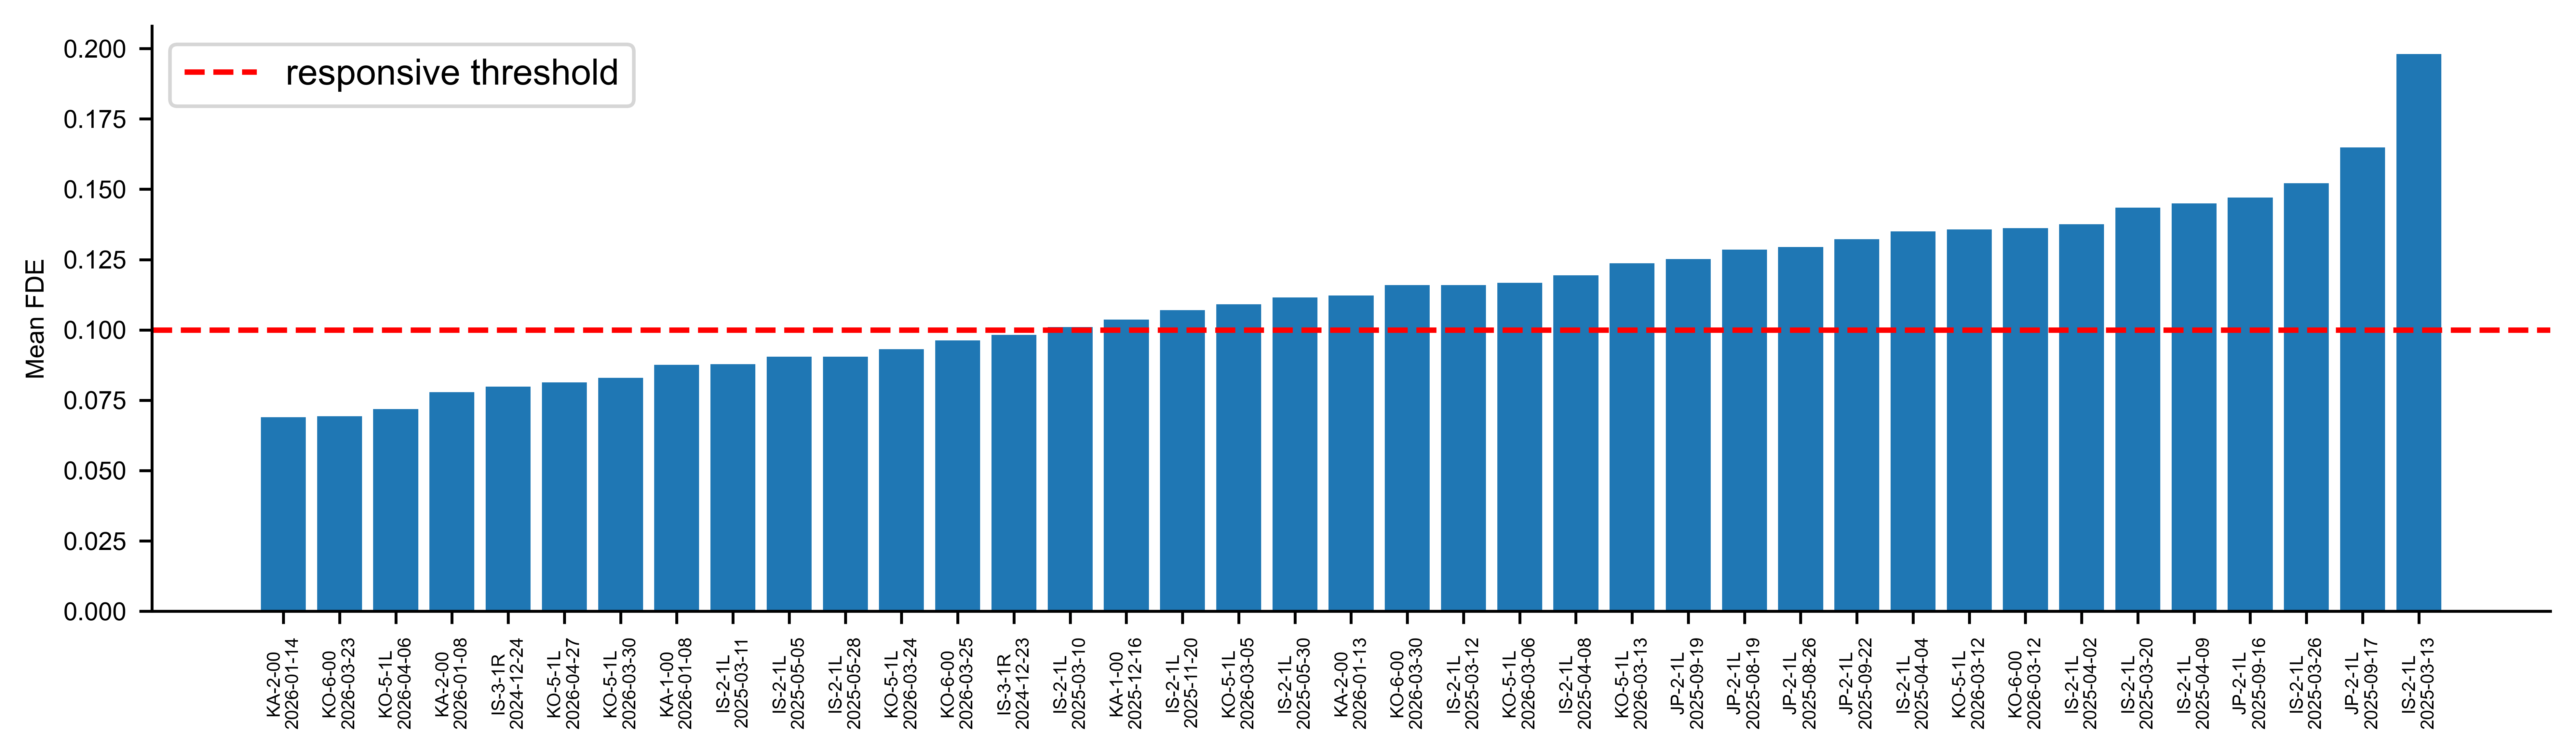

In [7]:
summary = (
    df_uni
    .groupby(['mouse_ID', 'date'])['test_frac_dev']
    .mean()
    .reset_index(name='mean_FDE')
    .sort_values('mean_FDE')
)

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(len(summary)), summary['mean_FDE'])
ax.axhline(RESP_THRESHOLD, color='red', linestyle='--', label='responsive threshold')
ax.set_xticks(range(len(summary)))
ax.set_xticklabels(summary['mouse_ID'] + '\n' + summary['date'], rotation=90, fontsize=5)
ax.set_ylabel('Mean FDE')
ax.legend()
plt.tight_layout()
plt.show()

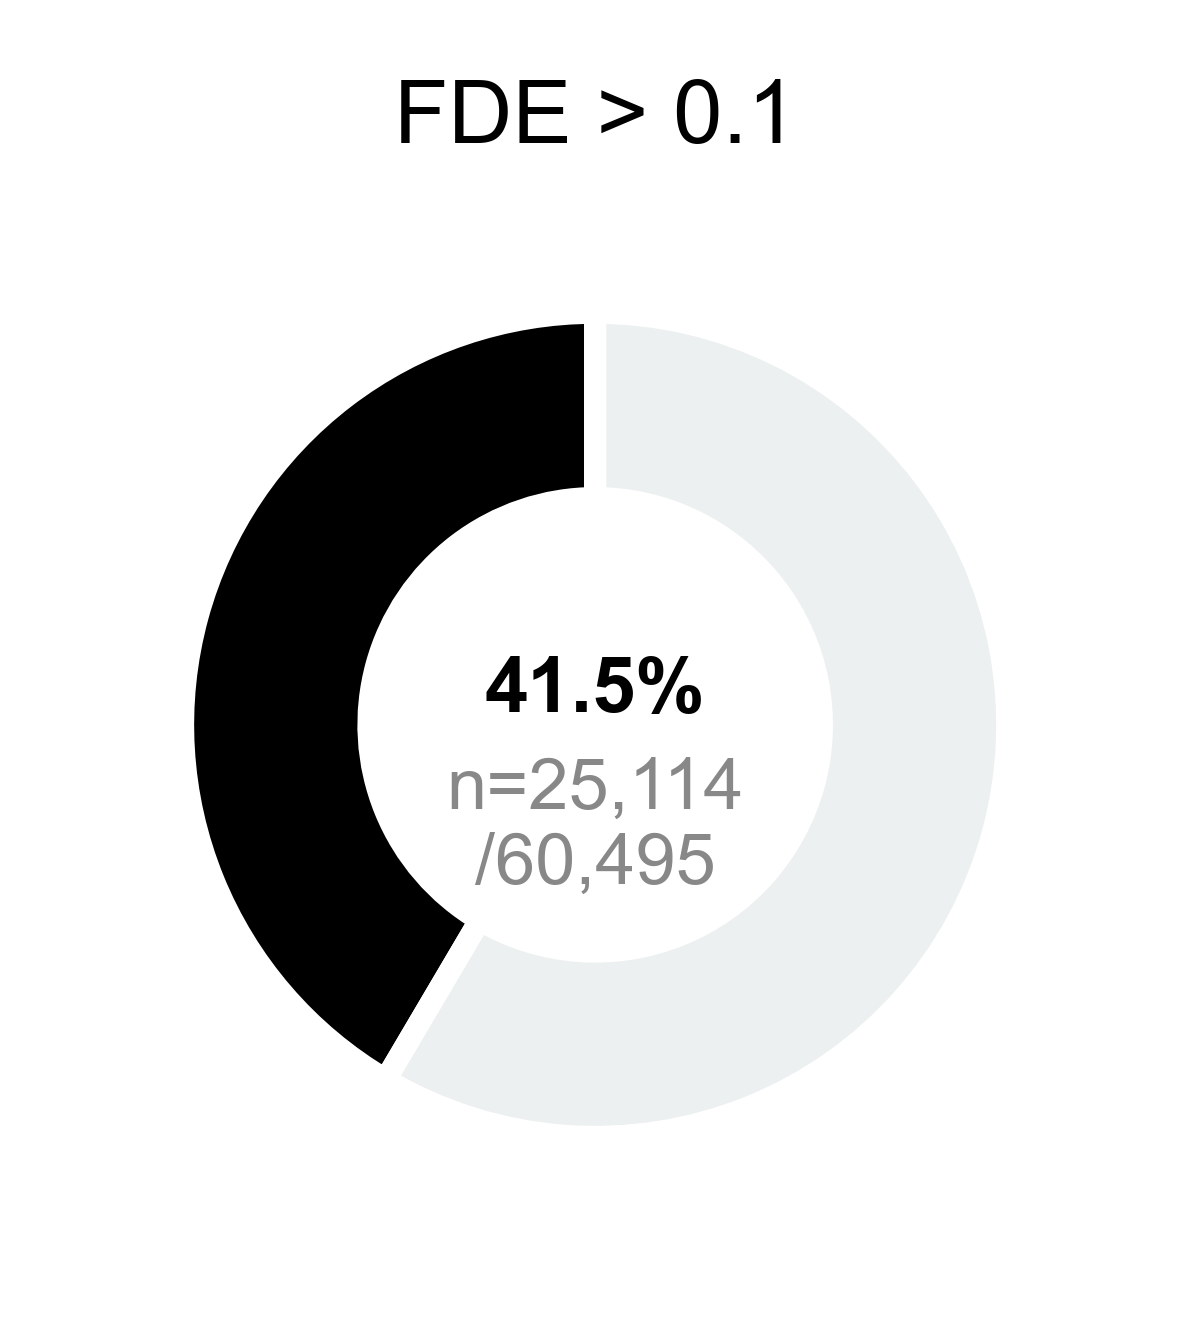

In [8]:
# ── 1a. Responsiveness donut ──────────────────────────────────────────────
def plot_responsiveness_donut(df, threshold=RESP_THRESHOLD, figsize=(1.75, 1.75)):
    n_total = len(df)
    n_resp  = (df['test_frac_dev'] > threshold).sum()
    pct     = n_resp / n_total * 100
    fig, ax = plt.subplots(figsize=figsize, dpi=800)
    ax.pie(
        [n_resp, n_total - n_resp],
        colors=['black', '#ECF0F1'], startangle=90,
        wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    )
    ax.text(0,  0.08, f'{pct:.1f}%', ha='center', va='center',
            fontsize=7, color='black', fontweight='bold')
    ax.text(0, -0.25, f'n={n_resp:,}\n/{n_total:,}', ha='center', va='center',
            fontsize=6.5, color='#888888')
    ax.set_title(f'FDE > {threshold}', fontsize=8)
    plt.tight_layout()
    return fig

fig = plot_responsiveness_donut(df_uni)
plt.savefig('figures/uni_responsiveness_donut.svg', bbox_inches='tight', facecolor='white')
plt.show()

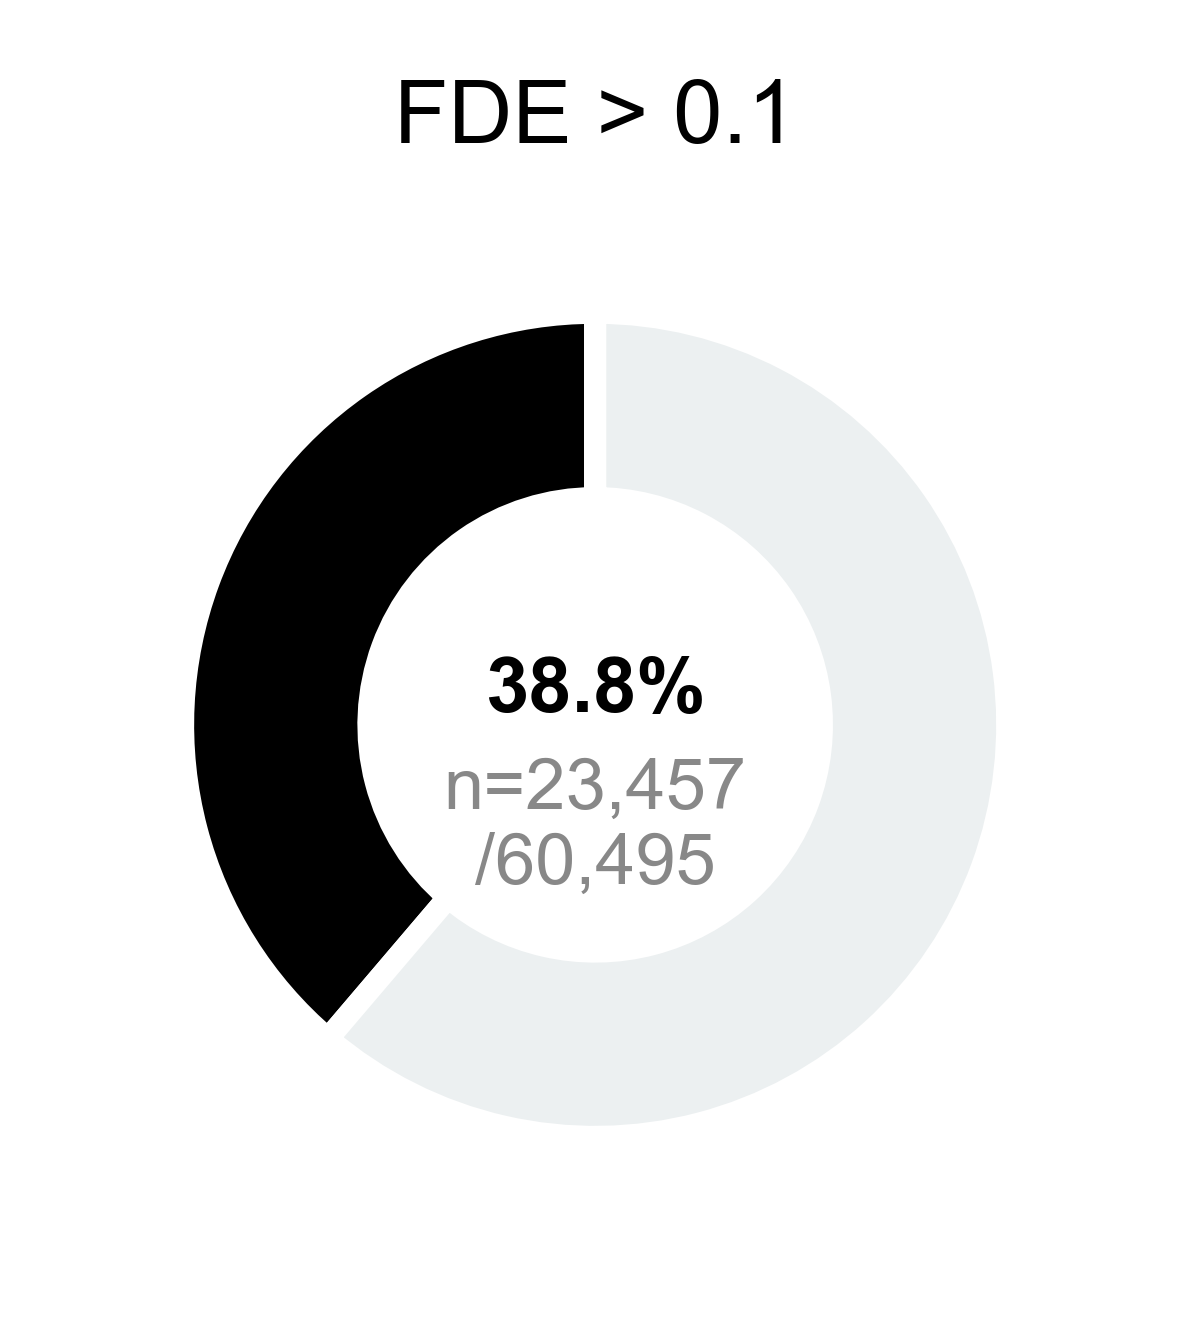

In [9]:
fig = plot_responsiveness_donut(df_cg)
plt.savefig('figures/cg_responsiveness_donut.svg', bbox_inches='tight', facecolor='white')
plt.show()

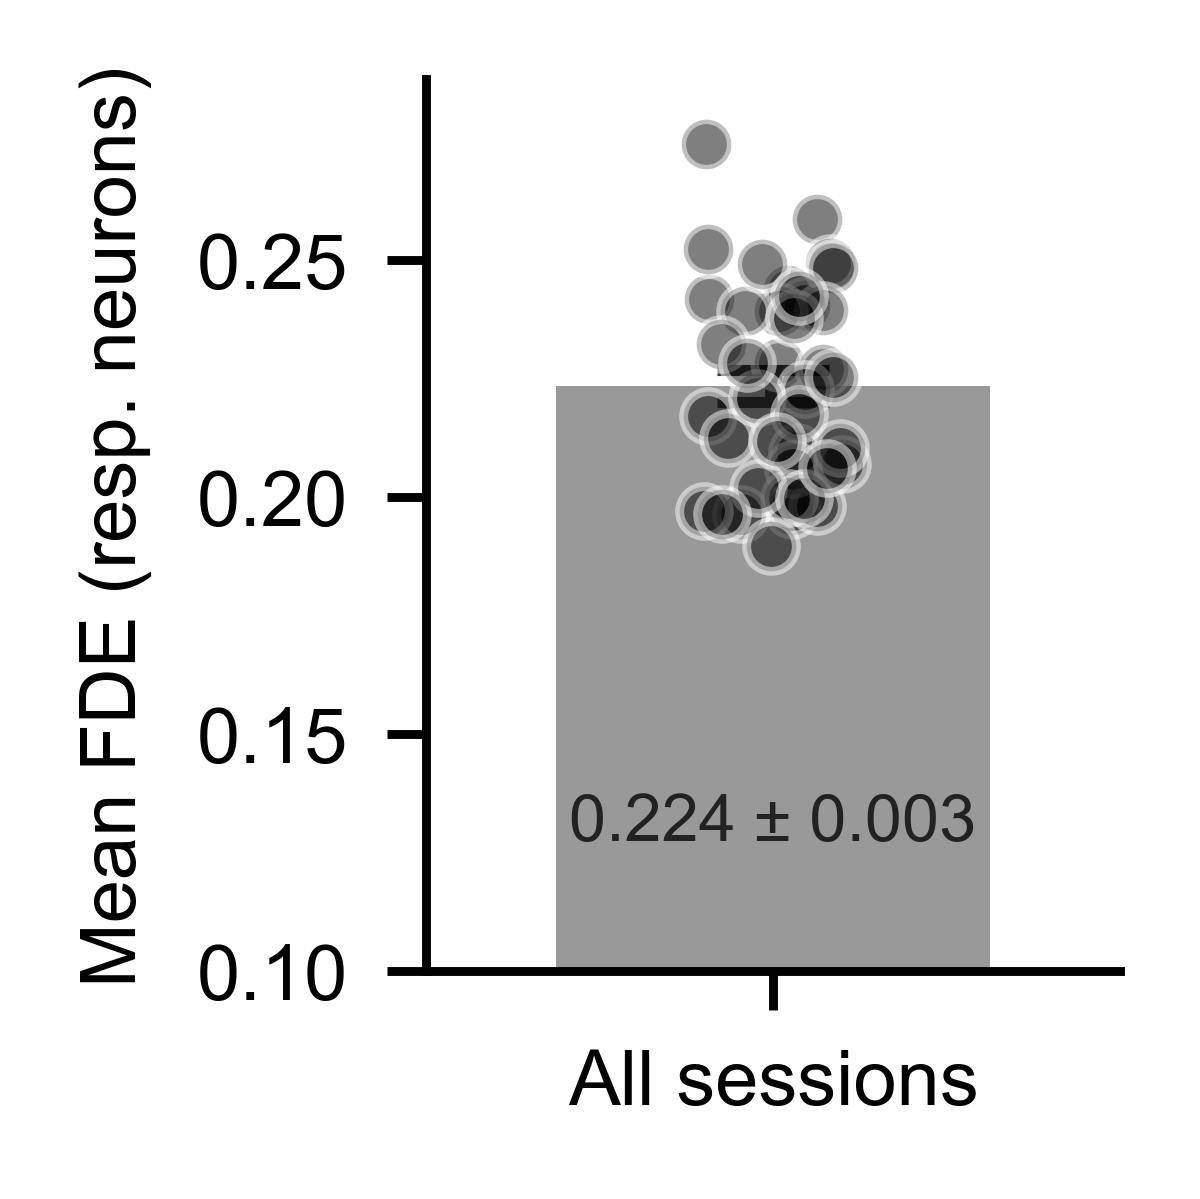

In [10]:
def plot_frac_dev_summary(df, resp_threshold=0.1, figsize=(1.6, 1.6)):
    """
    Single bar: mean of per-session median FDE across responsive neurons only.
    Error bar = SEM across sessions. Dots = individual session medians.
    """
    resp_df = df[df['test_frac_dev'] > resp_threshold].copy()

    sess_medians = (
        resp_df.groupby(['mouse_ID', 'date'])['test_frac_dev']
        .mean()
        .reset_index()
        .rename(columns={'test_frac_dev': 'median_fd'})
    )

    grand_mean = sess_medians['median_fd'].mean()
    grand_sem  = sess_medians['median_fd'].sem()

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    ax.bar(0, grand_mean, yerr=grand_sem, width=0.5,
           color='grey', alpha=0.8,
           error_kw=dict(elinewidth=1.5, capsize=5, ecolor='#333333'),
           zorder=2)

    rng    = np.random.default_rng(seed=0)
    jitter = rng.uniform(-0.08, 0.08, size=len(sess_medians))
    for i, row in sess_medians.iterrows():
        ax.scatter(jitter[i], row['median_fd'],
                   color='black', s=20, zorder=4, alpha=0.5,
                   edgecolors='white', linewidths=0.8)
    ax.text(0, 0.125, f'{grand_mean:.3f} ± {grand_sem:.3f}',
        ha='center', va='bottom', fontsize=6, color='#222222')
    ax.set_xticks([0])
    ax.set_xticklabels(['All sessions'], fontsize=7)
    ax.set_xlim(-0.4, 0.4)
    ax.set_ylim(bottom=resp_threshold)
    ax.set_ylabel('Mean FDE (resp. neurons)', fontsize=7)

    sns.despine()
    plt.tight_layout()
    return fig

figure = plot_frac_dev_summary(df_uni)
save_path='figures/perc_frac_dev_responsive_all_sessions.svg'
plt.savefig(save_path, bbox_inches='tight', facecolor='white', edgecolor='none')

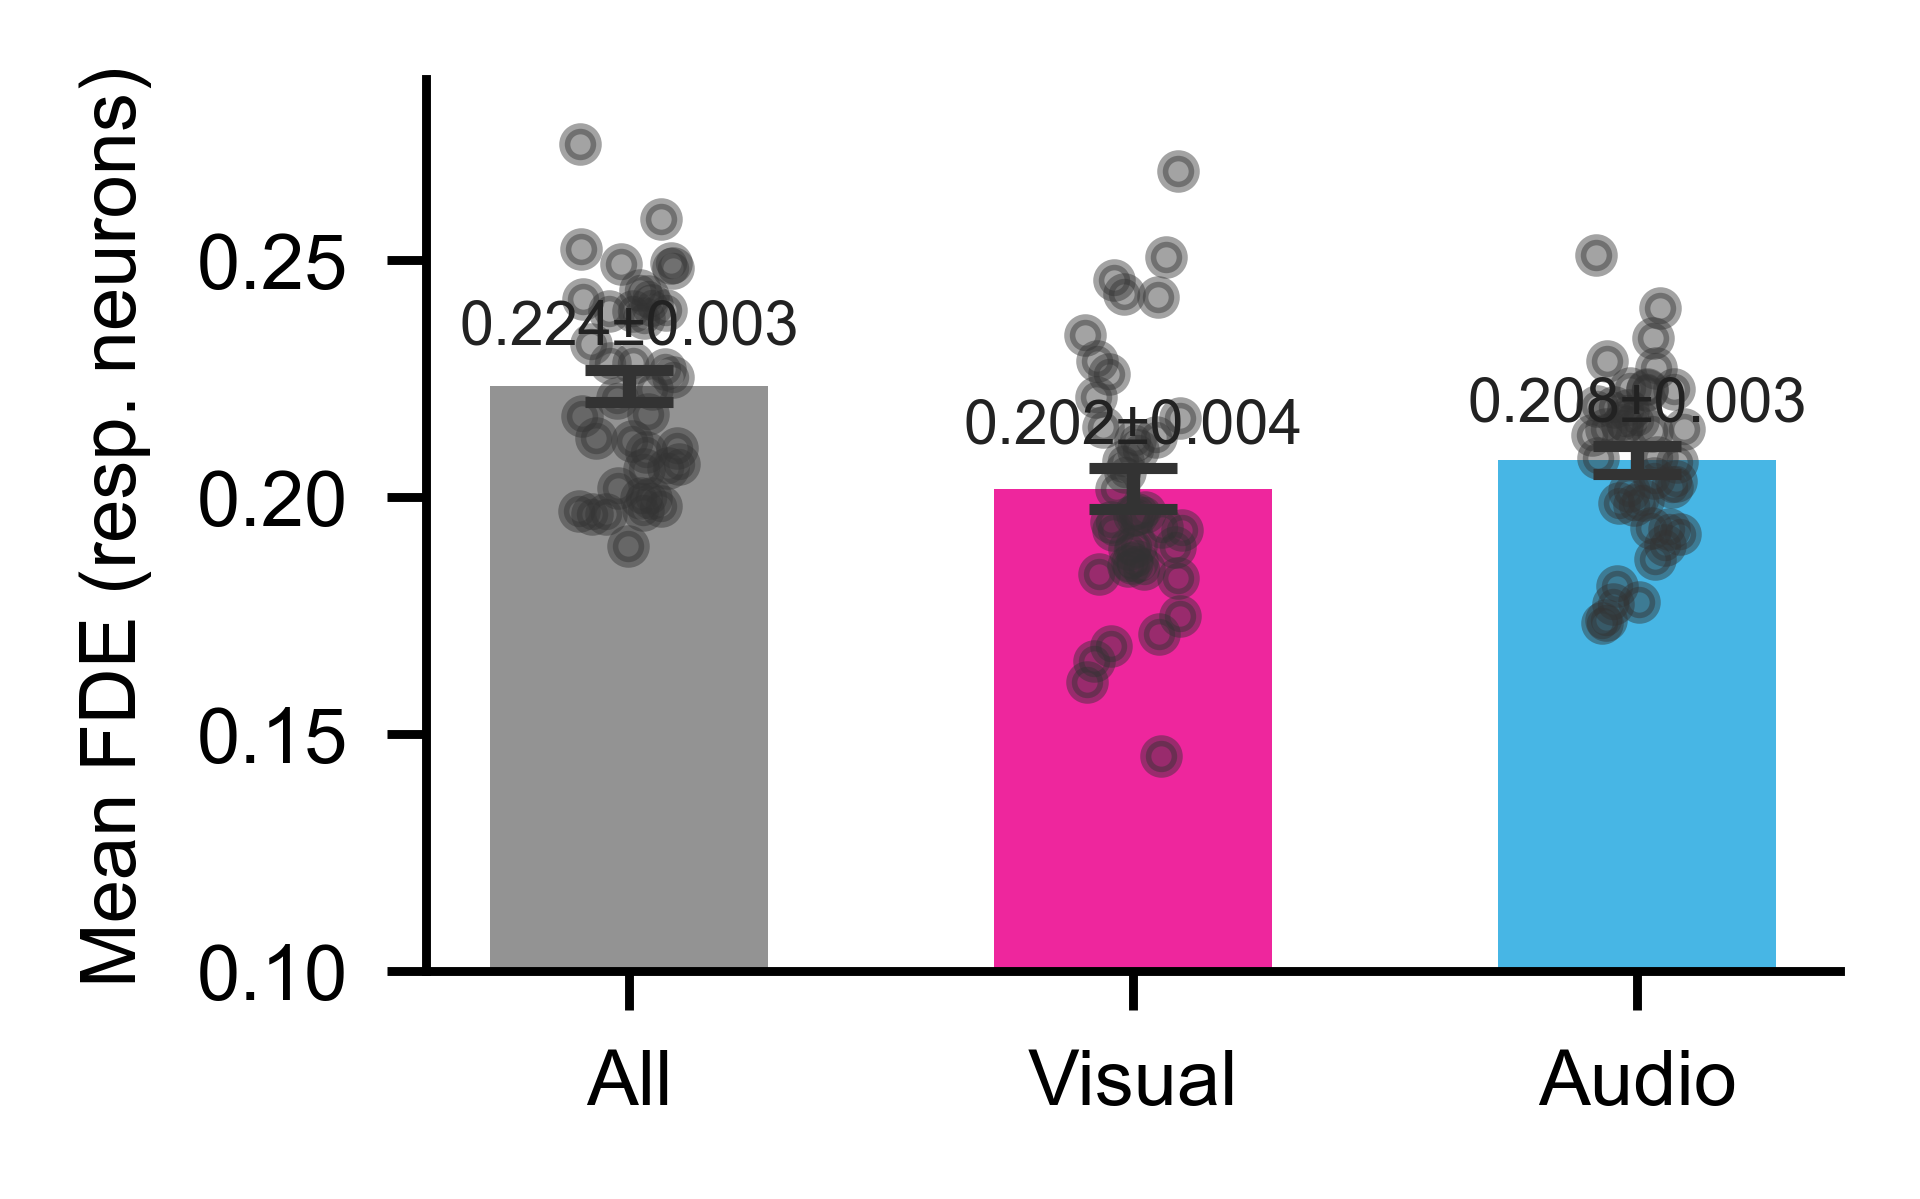

In [11]:
def plot_frac_dev_summary(df, resp_threshold=0.1, figsize=(2.5, 1.6)):
    """
    Three bars: overall, visual trials only, audio trials only.
    All use mean per session (consistent with plot_fde_by_context).
    """
    resp_df = df[df['test_frac_dev'] > resp_threshold].copy()

    cols   = ['test_frac_dev', 'frac_dev_visual', 'frac_dev_audio']
    labels = ['All', 'Visual', 'Audio']
    colors = ['grey', CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio']]

    sess_stats = (
        resp_df.groupby(['mouse_ID', 'date'])[cols]
        .mean()
        .reset_index()
    )
    n_sessions = len(sess_stats)

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for i, (col, label, color) in enumerate(zip(cols, labels, colors)):
        mean_val = sess_stats[col].mean()
        sem_val  = sess_stats[col].sem()

        ax.bar(i, mean_val, yerr=sem_val, width=0.55,
               color=color, alpha=0.85, edgecolor='none',
               error_kw=dict(elinewidth=1.2, capsize=4, ecolor='#333333'),
               zorder=2)

        rng    = np.random.default_rng(seed=i)
        jitter = rng.uniform(-0.1, 0.1, size=n_sessions)
        ax.scatter(i + jitter, sess_stats[col].values,
                   color='#333333', s=8, alpha=0.45, zorder=3)

        ax.text(i, mean_val + sem_val + 0.003,
                f'{mean_val:.3f}±{sem_val:.3f}',
                ha='center', va='bottom', fontsize=5.5, color='#222222')

    ax.set_xticks(range(3))
    ax.set_xticklabels(labels, fontsize=7)
    ax.set_ylim(bottom=resp_threshold)
    ax.set_ylabel('Mean FDE (resp. neurons)', fontsize=7)

    sns.despine()
    plt.tight_layout()
    return fig


figure = plot_frac_dev_summary(df_uni)
plt.savefig('figures/perc_frac_dev_responsive_all_sessions.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Wilcoxon (N=39 sessions): W=268.0  p=9.014e-02


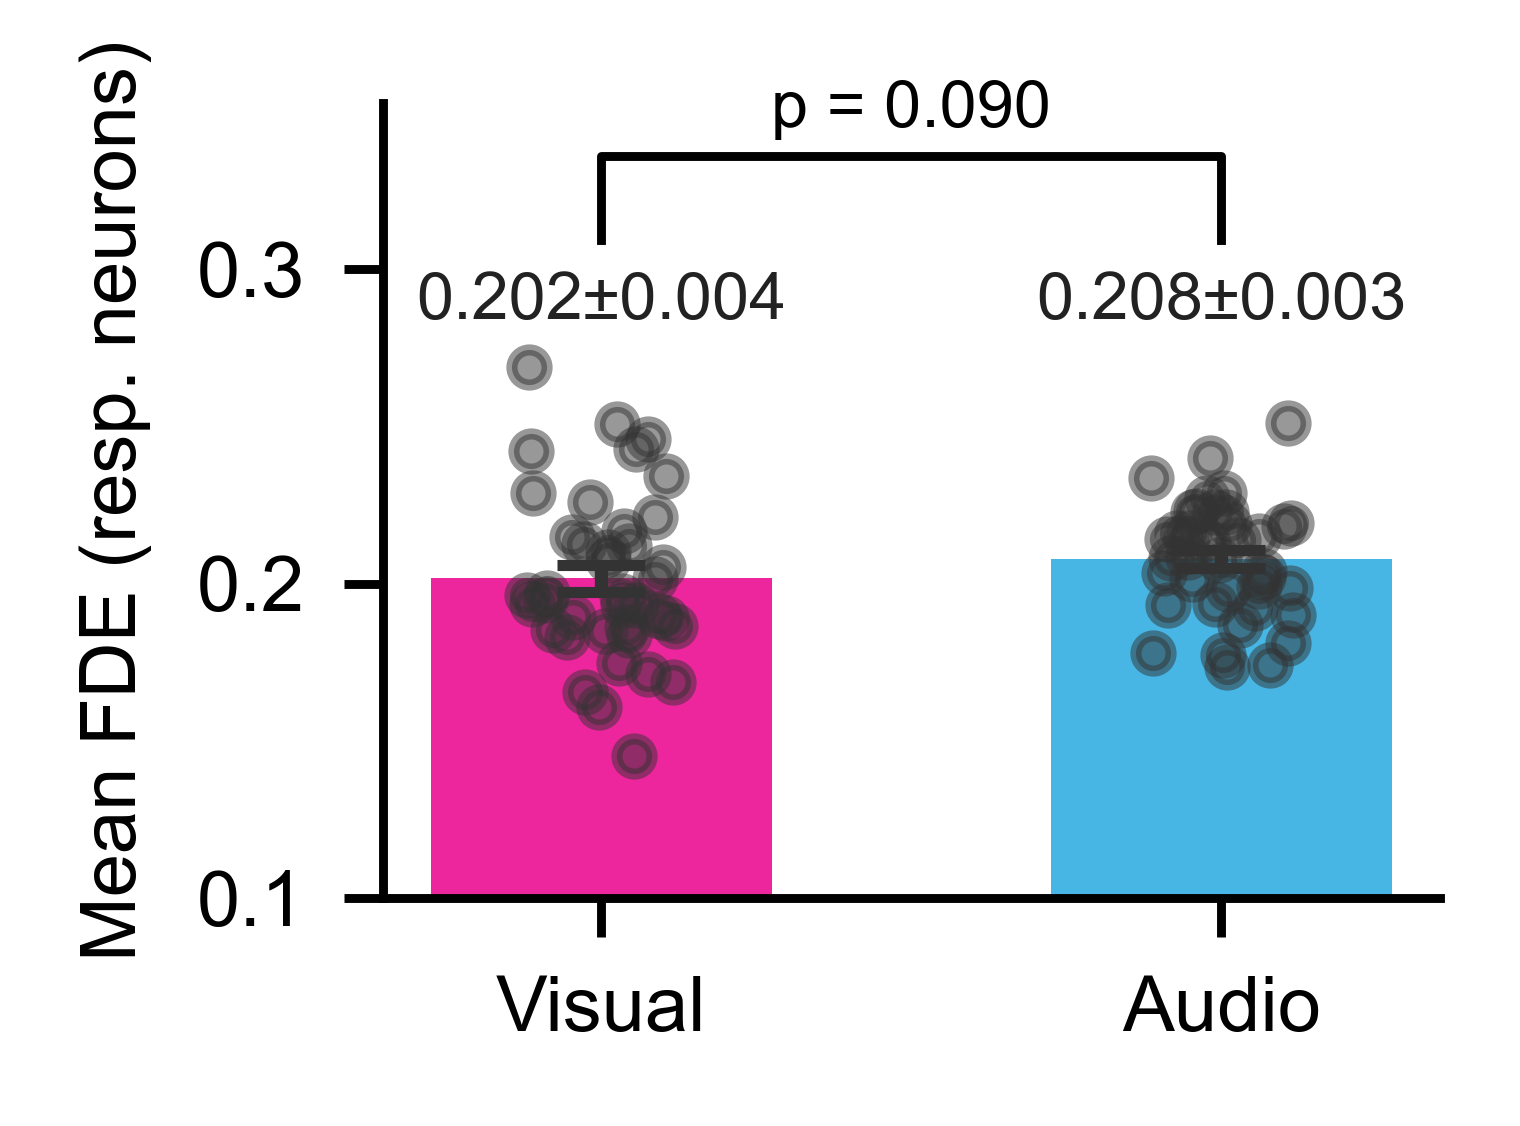

In [12]:
from scipy.stats import wilcoxon

def plot_fde_by_context(df, resp_threshold=0.1, figsize=(2, 1.5)):
    resp_df = df[df['test_frac_dev'] > resp_threshold].copy()

    ctx_cols   = ['frac_dev_visual', 'frac_dev_audio']
    ctx_labels = ['Visual', 'Audio']
    ctx_colors = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio']]

    sess_ctx = (
        resp_df.groupby(['mouse_ID', 'date'])[ctx_cols]
        .mean()
        .reset_index()
    )
    n_sessions = len(sess_ctx)

    w_stat, p_val = wilcoxon(sess_ctx['frac_dev_visual'], sess_ctx['frac_dev_audio'])
    print(f'Wilcoxon (N={n_sessions} sessions): W={w_stat:.1f}  p={p_val:.3e}')

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for i, (col, color) in enumerate(zip(ctx_cols, ctx_colors)):
        mean_val = sess_ctx[col].mean()
        sem_val  = sess_ctx[col].sem()

        ax.bar(i, mean_val, yerr=sem_val, width=0.55,
               color=color, alpha=0.85,
               error_kw=dict(elinewidth=1.2, capsize=4, ecolor='#333333'),
               zorder=2)

        rng    = np.random.default_rng(seed=i)
        jitter = rng.uniform(-0.12, 0.12, size=n_sessions)
        ax.scatter(i + jitter, sess_ctx[col].values,
                   color='#333333', s=10, alpha=0.5, zorder=3)

        ax.text(i, 0.28,
                f'{mean_val:.3f}±{sem_val:.3f}',
                ha='center', va='bottom', fontsize=6, color='#222222')

    def sig_label(p):
        if p < 0.001: return '***'
        if p < 0.01:  return '**'
        if p < 0.05:  return '*'
        return 'ns'

    y_top = max(sess_ctx[c].max() for c in ctx_cols)
    bar_h = y_top * 1.25
    ax.plot([0, 0, 1, 1], [y_top * 1.15, bar_h, bar_h, y_top * 1.15], lw=0.8, color='k')
    #ax.text(0.5, bar_h, sig_label(p_val), ha='center', va='bottom', fontsize=7)

    # with this:
    p_text = f'p = {p_val:.3f}' if p_val >= 0.001 else f'p = {p_val:.2e}'
    ax.text(0.5, bar_h+0.005, p_text, ha='center', va='bottom', fontsize=6)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(ctx_labels, fontsize=7)
    ax.set_yticks([0.1, 0.2, 0.3])
    ax.set_ylabel('Mean FDE (resp. neurons)', fontsize=7)
    ax.set_ylim(bottom=resp_threshold)

    sns.despine()
    plt.tight_layout()
    return fig

fig_ctx = plot_fde_by_context(df_uni)
plt.savefig('figures/context_fde_unisensory.svg', bbox_inches='tight', facecolor='white')
plt.show()

# Delta FDE Across Contexts

Responsive neurons: 25,114
  Context-invariant (|Δ| < 0.02): 3,280 (13.1%)
  Visual-preferring (Δ ≥  0.02):  10,891  (43.4%)
  Audio-preferring  (Δ ≤ -0.02): 10,943  (43.6%)


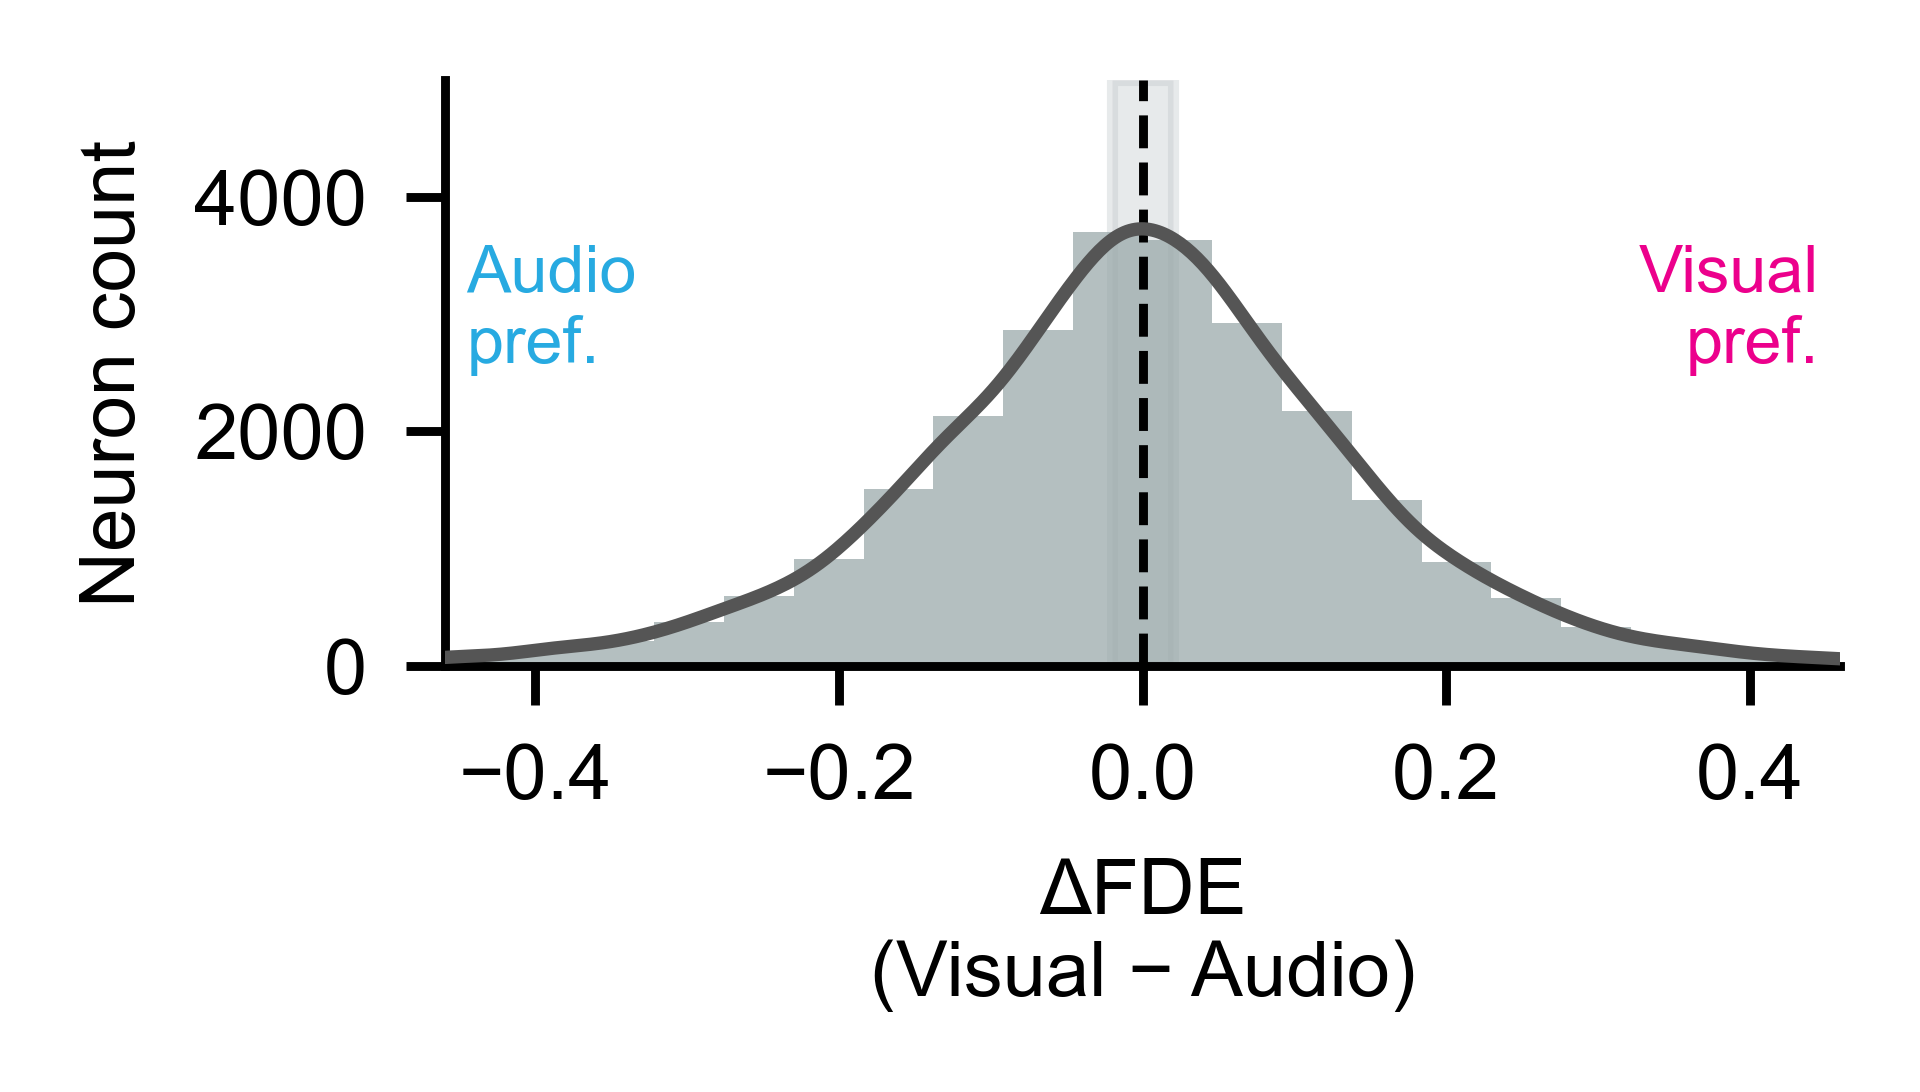

In [13]:
from scipy.stats import gaussian_kde
def plot_vis_aud_delta(df, resp_threshold=0.1, invariant_thresh=0.02, figsize=(2.5, 1.5)):
    resp_df = df[df['is_responsive']].copy()
    delta = resp_df['frac_dev_visual'].values - resp_df['frac_dev_audio'].values

    n_total     = len(delta)
    n_invariant = (np.abs(delta) < invariant_thresh).sum()
    n_vis_pref  = (delta >=  invariant_thresh).sum()
    n_aud_pref  = (delta <= -invariant_thresh).sum()
    print(f'Responsive neurons: {n_total:,}')
    print(f'  Context-invariant (|Δ| < {invariant_thresh}): {n_invariant:,} ({n_invariant/n_total*100:.1f}%)')
    print(f'  Visual-preferring (Δ ≥  {invariant_thresh}):  {n_vis_pref:,}  ({n_vis_pref/n_total*100:.1f}%)')
    print(f'  Audio-preferring  (Δ ≤ -{invariant_thresh}): {n_aud_pref:,}  ({n_aud_pref/n_total*100:.1f}%)')

    d_max = np.percentile(np.abs(delta), 99)   # clip extreme outliers for display

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    counts, edges, _ = ax.hist(
        delta, bins=20, range=(-d_max, d_max),
        color='#95A5A6', edgecolor='none', alpha=0.7, zorder=2
    )

    kde    = gaussian_kde(delta, bw_method=0.15)
    x_kde  = np.linspace(-d_max, d_max, 500)
    y_kde  = kde(x_kde) * n_total * (edges[1] - edges[0])
    ax.plot(x_kde, y_kde, color='#555555', lw=1.2, zorder=4)

    ax.axvspan(-invariant_thresh, invariant_thresh,
               color='#BDC3C7', alpha=0.35, zorder=1)
    ax.axvline(0, color='k', lw=0.8, ls='--', zorder=3)

    y_max = counts.max()
    ax.text(-d_max * 0.97, y_max * 0.97, 'Audio\npref.',
            fontsize=6, color=CTX_COLORS_STR['audio'], va='top', ha='left')
    ax.text( d_max * 0.97, y_max * 0.97, 'Visual\npref.',
            fontsize=6, color=CTX_COLORS_STR['visual'], va='top', ha='right')

    ax.set_xlabel('ΔFDE\n(Visual − Audio)', fontsize=7)
    ax.set_ylabel('Neuron count', fontsize=7)
    ax.set_xlim(-d_max, d_max)
    ax.set_ylim(0, 5000)

    sns.despine()
    plt.tight_layout()
    return fig

fig_delta = plot_vis_aud_delta(df_uni)
plt.savefig('figures/vis_aud_delta_fde.svg', bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()

Responsive neurons: 25,114
  Context-invariant (|CI| < 0.1): 6,634 (26.4%)
  Visual-preferring (CI ≥  0.1):  9,165  (36.5%)
  Audio-preferring  (CI ≤ -0.1): 9,315  (37.1%)


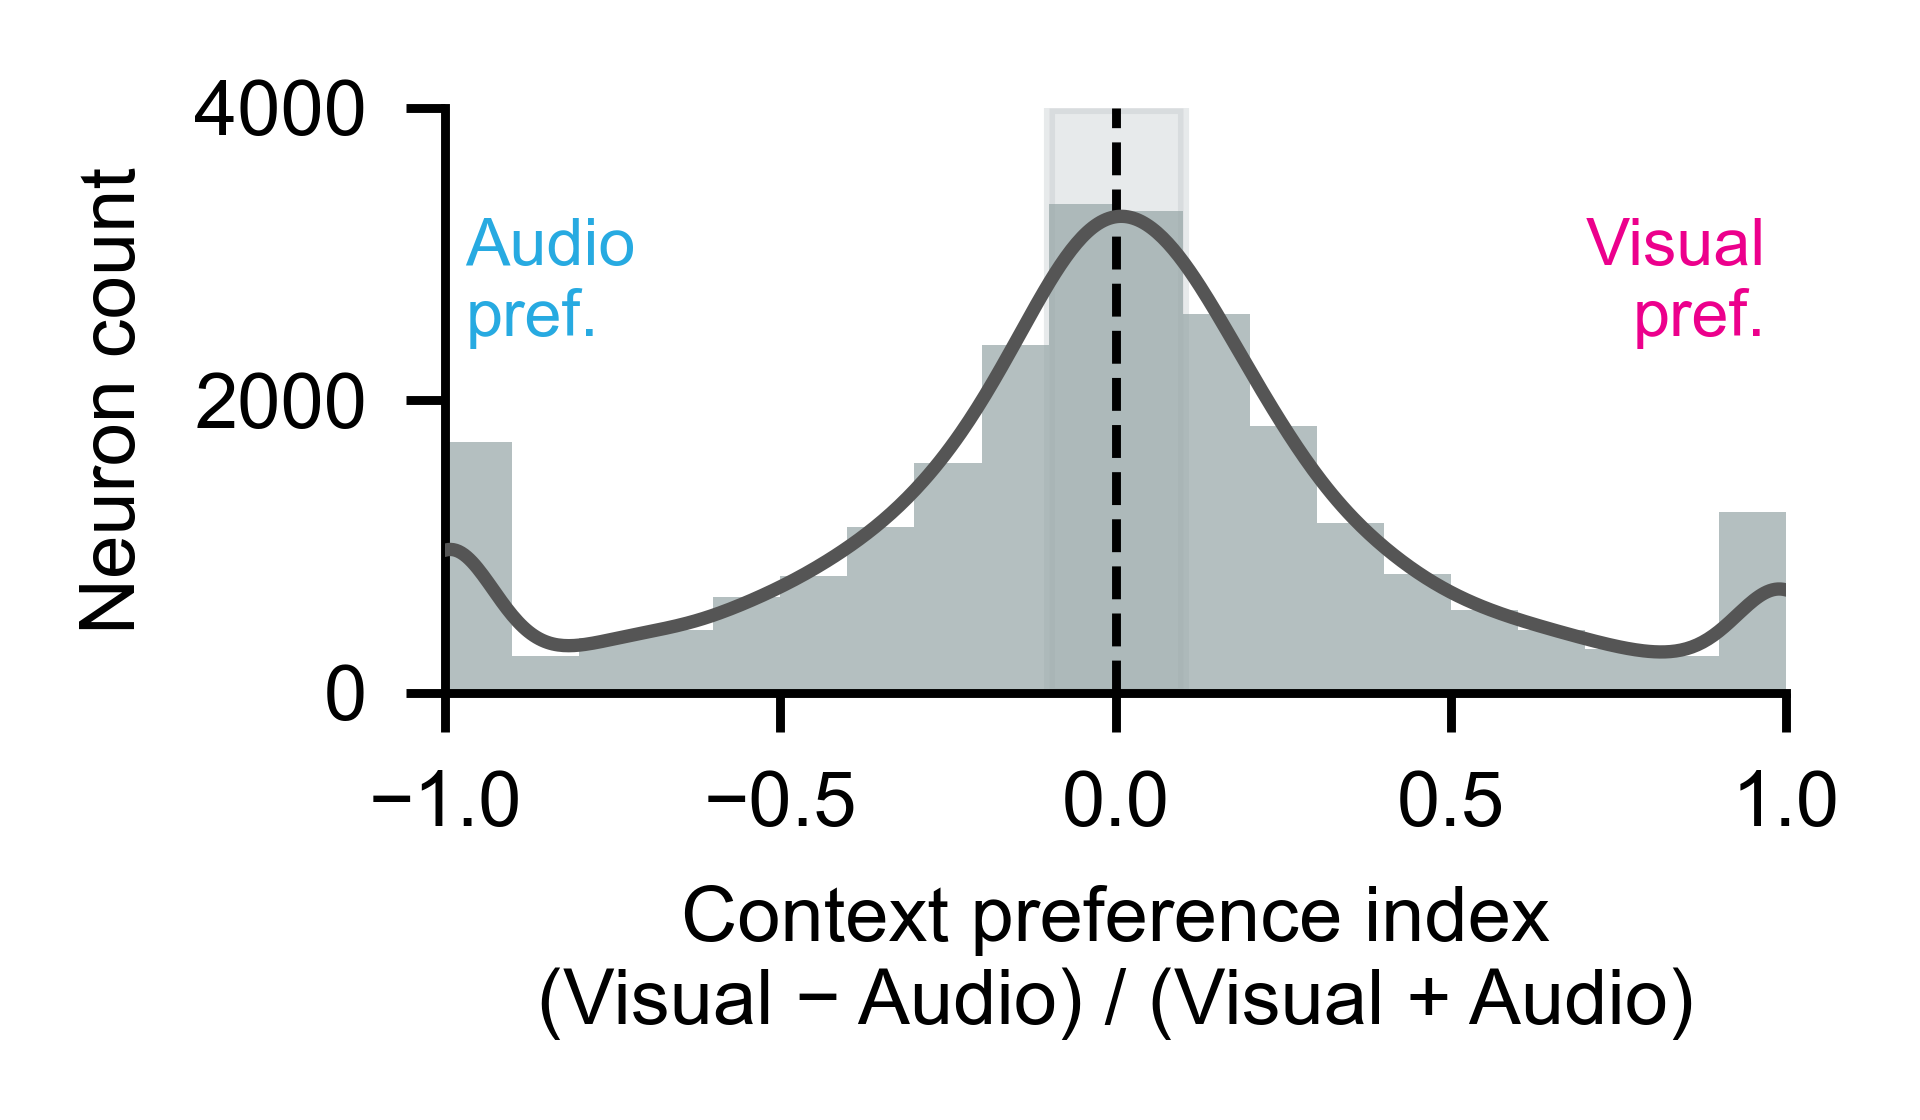

In [14]:
from scipy.stats import gaussian_kde

def plot_vis_aud_ci(df, resp_threshold=0.1, invariant_thresh=0.1, figsize=(2.5, 1.5)):
    resp_df = df[df['is_responsive']].copy()
    ci = resp_df['vis_aud_ci'].values

    n_total     = len(ci)
    n_invariant = (np.abs(ci) < invariant_thresh).sum()
    n_vis_pref  = (ci >=  invariant_thresh).sum()
    n_aud_pref  = (ci <= -invariant_thresh).sum()
    print(f'Responsive neurons: {n_total:,}')
    print(f'  Context-invariant (|CI| < {invariant_thresh}): {n_invariant:,} ({n_invariant/n_total*100:.1f}%)')
    print(f'  Visual-preferring (CI ≥  {invariant_thresh}):  {n_vis_pref:,}  ({n_vis_pref/n_total*100:.1f}%)')
    print(f'  Audio-preferring  (CI ≤ -{invariant_thresh}): {n_aud_pref:,}  ({n_aud_pref/n_total*100:.1f}%)')

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    counts, edges, _ = ax.hist(
        ci, bins=20, range=(-1, 1),
        color='#95A5A6', edgecolor='none', alpha=0.7, zorder=2
    )

    # KDE overlay (scaled to histogram height)
    kde     = gaussian_kde(ci, bw_method=0.15)
    x_kde   = np.linspace(-1, 1, 500)
    y_kde   = kde(x_kde)
    bin_w   = edges[1] - edges[0]
    y_kde  *= n_total * bin_w          # scale to match histogram counts
    ax.plot(x_kde, y_kde, color='#555555', lw=1.2, zorder=4)

    # Shaded invariant zone
    ax.axvspan(-invariant_thresh, invariant_thresh,
               color='#BDC3C7', alpha=0.35, zorder=1, label=f'|CI| < {invariant_thresh}')
    ax.axvline(0, color='k', lw=0.8, ls='--', zorder=3)

    y_max = counts.max()
    ax.text(-0.97, y_max * 0.97, 'Audio\npref.',
            fontsize=6, color=CTX_COLORS_STR['audio'], va='top', ha='left')
    ax.text( 0.97, y_max * 0.97, 'Visual\npref.',
            fontsize=6, color=CTX_COLORS_STR['visual'], va='top', ha='right')

    ax.set_xlabel('Context preference index\n(Visual − Audio) / (Visual + Audio)', fontsize=7)
    ax.set_ylabel('Neuron count', fontsize=7)
    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 4000)

    sns.despine()
    plt.tight_layout()
    return fig

fig_ci = plot_vis_aud_ci(df_uni)
plt.savefig('figures/vis_aud_context_index.svg', bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()

# Example Neurons

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Context-invariant example neuron: observed vs model, vis & aud contexts
# ─────────────────────────────────────────────────────────────────────────────
import pickle
from scipy.ndimage import gaussian_filter1d
from scipy.stats import pearsonr
from core.session_pipeline import BASE_DATA_PATH, Y_SCALE, Y_SMOOTH_SIGMA, add_coupling_predictor
from core.glm_class import make_prediction

CTX_MAP   = {1: 'Visual', 2: 'Audio'}
CTX_ORDER = [1, 2]
WINDOW    = 800
STRIDE    = 20
FS        = 15.0

T_STARTS  = {1: None, 2: None}

# ── Step 1: find best context-invariant neuron with a matching session ────────
MIN_FDE_BOTH = 0.20
MAX_ABS_CPI  = 0.15

inv_df = df_uni[df_uni['test_frac_dev'] > MIN_FDE_BOTH].copy()
inv_df = inv_df[
    (inv_df['frac_dev_visual'] >= MIN_FDE_BOTH) &
    (inv_df['frac_dev_audio']  >= MIN_FDE_BOTH) &
    (inv_df['vis_aud_ci'].abs() <= MAX_ABS_CPI)
].sort_values('test_frac_dev', ascending=False)

if inv_df.empty:
    raise ValueError('No neurons meet criteria — lower MIN_FDE_BOTH or raise MAX_ABS_CPI')

# Iterate top candidates until feature dims match
best = X = Y = W = w0 = glm_data = ex_session = None
for rank in range(min(20, len(inv_df))):
    cand      = inv_df.iloc[rank]
    _mouse    = cand['mouse_ID']
    _date     = cand['date']
    _nidx     = int(cand['neuron_idx'])
    _session  = next((s for s in sessions_uni
                      if s['mouse_ID'] == _mouse and s['date'] == _date), None)
    if _session is None:
        continue

    _W  = _session['full_res']['weights']
    _w0 = _session['full_res']['w0'].flatten()

    stacked_path = f'{BASE_DATA_PATH}/{_mouse}/{_date}/glm_data_stacked.pkl'
    if not os.path.exists(stacked_path):
        continue
    with open(stacked_path, 'rb') as f:
        _glm_data = pickle.load(f)

    _X = _glm_data['X']
    _Y = _glm_data['Y'] * Y_SCALE
    if Y_SMOOTH_SIGMA > 0:
        _Y = gaussian_filter1d(_Y, sigma=Y_SMOOTH_SIGMA, axis=0)
        _Y = np.clip(_Y, 0.0, None)

    # Try without coupling first
    if _W.shape[0] == _X.shape[1]:
        print(f'Rank {rank}: {_mouse}/{_date}  — no coupling needed')
        best, X, Y, W, w0, glm_data, ex_session = cand, _X, _Y, _W, _w0, _glm_data, _session
        nidx = _nidx
        break

    # Try with coupling
    _X_coup, _, _ = add_coupling_predictor(
        _X.copy(), _Y, _glm_data['predictor_info'],
        n_pcs=5, n_lag_bases=4, lag_frames=8
    )
    if _W.shape[0] == _X_coup.shape[1]:
        print(f'Rank {rank}: {_mouse}/{_date}  — coupling added')
        best, X, Y, W, w0, glm_data, ex_session = cand, _X_coup, _Y, _W, _w0, _glm_data, _session
        nidx = _nidx
        break

    print(f'Rank {rank}: {_mouse}/{_date}  — skipped (W={_W.shape[0]}, '
          f'X_base={_X.shape[1]}, X_coup={_X_coup.shape[1]})')

if best is None:
    raise ValueError('No candidate with matching feature dimensions found in top 20')

print(f'\nSelected neuron:')
print(f'  Session    : {best["mouse_ID"]} / {best["date"]}')
print(f'  Neuron     : {nidx}')
print(f'  FDE overall: {best["test_frac_dev"]:.3f}')
print(f'  FDE Visual : {best["frac_dev_visual"]:.3f}')
print(f'  FDE Audio  : {best["frac_dev_audio"]:.3f}')
print(f'  CPI        : {best["vis_aud_ci"]:.3f}')
print(f'  N candidates in pool: {len(inv_df)}')

# ── Step 2: make predictions ──────────────────────────────────────────────────
Y_pred    = make_prediction(X, W, w0, activation='exp')
test_mask = ex_session['full_res']['combined_test_mask']
metadata  = glm_data['metadata']

# Filter to the contexts used by the unisensory model (1 & 2 only)
# so that test_mask, Y, Y_pred, and metadata all share the same frame axis.
CONTEXTS   = [1, 2]
ctx_filter = np.isin(metadata['context'], CONTEXTS)

metadata  = {k: v[ctx_filter] for k, v in metadata.items()}
Y         = Y[ctx_filter]
Y_pred    = Y_pred[ctx_filter]
# test_mask is already over the filtered frame space — no change needed

# ── Step 3: auto-search helper ────────────────────────────────────────────────
def find_best_ctx_window(y_obs, y_pred, ctx_frames, window=WINDOW, stride=STRIDE,
                         min_mean=0.1):
    idx    = np.sort(ctx_frames)
    n      = len(idx)
    best_r, best_start = -np.inf, idx[0]
    for k in range(0, n - window, stride):
        win_idx = idx[k : k + window]
        if win_idx[-1] - win_idx[0] > window * 3:
            continue
        y_o, y_p = y_obs[win_idx], y_pred[win_idx]
        if y_o.mean() < min_mean or y_o.std() < 1e-6 or y_p.std() < 1e-6:
            continue
        r, _ = pearsonr(y_o, y_p)
        if r > best_r:
            best_r, best_start = r, win_idx[0]
    return best_start, best_r

# ── Step 4: resolve windows ───────────────────────────────────────────────────
ctx_windows = {}
for ctx_id in CTX_ORDER:
    if T_STARTS[ctx_id] is not None:
        ctx_windows[ctx_id] = (T_STARTS[ctx_id], None)
        print(f'  {CTX_MAP[ctx_id]:6s}  manual  start={T_STARTS[ctx_id]}')
    else:
        ctx_frames = np.where(test_mask & (metadata['context'] == ctx_id))[0]
        t_start, r = find_best_ctx_window(Y[:, nidx], Y_pred[:, nidx], ctx_frames)
        ctx_windows[ctx_id] = (t_start, r)
        print(f'  {CTX_MAP[ctx_id]:6s}  auto    start={t_start}  r={r:.3f}')

In [ ]:
# ── Step 5: figure ────────────────────────────────────────────────────────────
fde_per_ctx = {1: best['frac_dev_visual'], 2: best['frac_dev_audio']}
ctx_colors  = {1: CTX_COLORS_STR['visual'], 2: CTX_COLORS_STR['audio']}

t_axis = np.arange(WINDOW) / FS
fig, axes = plt.subplots(1, 2, figsize=(3.5, 1.5), dpi=800, sharey=True)

for col_i, ctx_id in enumerate(CTX_ORDER):
    ax      = axes[col_i]
    t_start = ctx_windows[ctx_id][0]
    color   = ctx_colors[ctx_id]
    fde     = fde_per_ctx[ctx_id]

    y_obs  = Y[t_start : t_start + WINDOW, nidx]
    y_pred = Y_pred[t_start : t_start + WINDOW, nidx]

    ax.fill_between(t_axis, y_obs, alpha=0.3, color='#444444', lw=0)
    ax.plot(t_axis, y_obs,  color='#444444', lw=0.7, label='Observed')
    ax.plot(t_axis, y_pred, color=color,     lw=1.2, alpha=0.9, label='Model')

    ax.set_xlim(0, WINDOW / FS)
    ax.set_ylim(bottom=0)
    ax.set_xlabel('Time (s)', fontsize=7)
    ax.set_title(f'{CTX_MAP[ctx_id]}  —  FDE = {fde:.2f}', fontsize=8, color=color)
    ax.set_yticklabels([])
    if col_i == 0:
        ax.set_ylabel('Activity (a.u.)', fontsize=7)
        ax.legend(fontsize=6, frameon=False, loc='upper right')
    if col_i == 1:
        ax.text(0.97, 0.97, f'CPI = {best["vis_aud_ci"]:.2f}',
                transform=ax.transAxes, fontsize=6, ha='right', va='top',
                color='#555555')

plt.tight_layout()
plt.savefig('figures/example_invariant_neuron.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Context-dependent example neuron: observed vs model, vis & aud contexts
# ─────────────────────────────────────────────────────────────────────────────
import pickle
from scipy.ndimage import gaussian_filter1d
from scipy.stats import pearsonr
from core.session_pipeline import BASE_DATA_PATH, Y_SCALE, Y_SMOOTH_SIGMA, add_coupling_predictor
from core.glm_class import make_prediction

CTX_MAP   = {1: 'Visual', 2: 'Audio'}
CTX_ORDER = [1, 2]
WINDOW    = 800
STRIDE    = 20
FS        = 15.0

T_STARTS  = {1: None, 2: None}

# ── Step 1: find best context-dependent neuron ────────────────────────────────
MIN_FDE_PREF   = 0.25    # high FDE in preferred context
MAX_FDE_NONPREF = 0.12   # low FDE in non-preferred context
MIN_ABS_CPI    = 0.50    # strongly context-dependent

# Options: 'visual'  → CPI > 0  (visual-preferring)
#          'audio'   → CPI < 0  (audio-preferring)
#          'either'  → highest |CPI| regardless of direction
CTX_PREF = 'either'

dep_df = df_uni[df_uni['is_responsive']].copy()

if CTX_PREF == 'visual':
    dep_df = dep_df[
        (dep_df['vis_aud_ci']      >=  MIN_ABS_CPI)  &
        (dep_df['frac_dev_visual'] >= MIN_FDE_PREF)  &
        (dep_df['frac_dev_audio']  <= MAX_FDE_NONPREF)
    ]
elif CTX_PREF == 'audio':
    dep_df = dep_df[
        (dep_df['vis_aud_ci']      <= -MIN_ABS_CPI)  &
        (dep_df['frac_dev_audio']  >= MIN_FDE_PREF)  &
        (dep_df['frac_dev_visual'] <= MAX_FDE_NONPREF)
    ]
else:  # 'either'
    dep_df = dep_df[
        (dep_df['vis_aud_ci'].abs() >= MIN_ABS_CPI) &
        (dep_df[['frac_dev_visual', 'frac_dev_audio']].max(axis=1) >= MIN_FDE_PREF) &
        (dep_df[['frac_dev_visual', 'frac_dev_audio']].min(axis=1) <= MAX_FDE_NONPREF)
    ]

dep_df = dep_df.sort_values('vis_aud_ci', key=abs, ascending=False)

if dep_df.empty:
    raise ValueError('No neurons meet criteria — lower MIN_ABS_CPI, lower MIN_FDE_PREF, '
                     'or raise MAX_FDE_NONPREF')

print(f'{len(dep_df):,} candidate context-dependent neurons')

# ── Step 2: iterate candidates until feature dims match ───────────────────────
best = X = Y = W = w0 = glm_data = ex_session = None
for rank in range(min(20, len(dep_df))):
    cand     = dep_df.iloc[rank]
    _mouse   = cand['mouse_ID']
    _date    = cand['date']
    _nidx    = int(cand['neuron_idx'])
    _session = next((s for s in sessions_uni
                     if s['mouse_ID'] == _mouse and s['date'] == _date), None)
    if _session is None:
        continue

    _W  = _session['full_res']['weights']
    _w0 = _session['full_res']['w0'].flatten()

    stacked_path = f'{BASE_DATA_PATH}/{_mouse}/{_date}/glm_data_stacked.pkl'
    if not os.path.exists(stacked_path):
        continue
    with open(stacked_path, 'rb') as f:
        _glm_data = pickle.load(f)

    _X = _glm_data['X']
    _Y = _glm_data['Y'] * Y_SCALE
    if Y_SMOOTH_SIGMA > 0:
        _Y = gaussian_filter1d(_Y, sigma=Y_SMOOTH_SIGMA, axis=0)
        _Y = np.clip(_Y, 0.0, None)

    if _W.shape[0] == _X.shape[1]:
        print(f'Rank {rank}: {_mouse}/{_date}  — no coupling needed')
        best, X, Y, W, w0, glm_data, ex_session = cand, _X, _Y, _W, _w0, _glm_data, _session
        nidx = _nidx
        break

    _X_coup, _, _ = add_coupling_predictor(
        _X.copy(), _Y, _glm_data['predictor_info'],
        n_pcs=5, n_lag_bases=4, lag_frames=8
    )
    if _W.shape[0] == _X_coup.shape[1]:
        print(f'Rank {rank}: {_mouse}/{_date}  — coupling added')
        best, X, Y, W, w0, glm_data, ex_session = cand, _X_coup, _Y, _W, _w0, _glm_data, _session
        nidx = _nidx
        break

    print(f'Rank {rank}: {_mouse}/{_date}  — skipped '
          f'(W={_W.shape[0]}, X_base={_X.shape[1]}, X_coup={_X_coup.shape[1]})')

if best is None:
    raise ValueError('No candidate with matching feature dimensions found in top 20')

pref_ctx = 'Visual' if best['vis_aud_ci'] > 0 else 'Audio'
print(f'\nSelected neuron:')
print(f'  Session     : {best["mouse_ID"]} / {best["date"]}')
print(f'  Neuron      : {nidx}')
print(f'  Preference  : {pref_ctx}')
print(f'  FDE overall : {best["test_frac_dev"]:.3f}')
print(f'  FDE Visual  : {best["frac_dev_visual"]:.3f}')
print(f'  FDE Audio   : {best["frac_dev_audio"]:.3f}')
print(f'  CPI         : {best["vis_aud_ci"]:.3f}')

# ── Step 3: make predictions ──────────────────────────────────────────────────
# ── Step 2: make predictions ──────────────────────────────────────────────────
Y_pred    = make_prediction(X, W, w0, activation='exp')
test_mask = ex_session['full_res']['combined_test_mask']
metadata  = glm_data['metadata']

# Filter to the contexts used by the unisensory model (1 & 2 only)
# so that test_mask, Y, Y_pred, and metadata all share the same frame axis.
CONTEXTS   = [1, 2]
ctx_filter = np.isin(metadata['context'], CONTEXTS)

metadata  = {k: v[ctx_filter] for k, v in metadata.items()}
Y         = Y[ctx_filter]
Y_pred    = Y_pred[ctx_filter]
# test_mask is already over the filtered frame space — no change needed

# ── Step 4: auto-search helper ────────────────────────────────────────────────
def find_best_ctx_window(y_obs, y_pred, ctx_frames, window=WINDOW, stride=STRIDE,
                         min_mean=0.1):
    idx    = np.sort(ctx_frames)
    n      = len(idx)
    best_r, best_start = -np.inf, idx[0]
    for k in range(0, n - window, stride):
        win_idx = idx[k : k + window]
        if win_idx[-1] - win_idx[0] > window * 3:
            continue
        y_o, y_p = y_obs[win_idx], y_pred[win_idx]
        if y_o.mean() < min_mean or y_o.std() < 1e-6 or y_p.std() < 1e-6:
            continue
        r, _ = pearsonr(y_o, y_p)
        if r > best_r:
            best_r, best_start = r, win_idx[0]
    return best_start, best_r

# ── Step 5: resolve windows ───────────────────────────────────────────────────
ctx_windows = {}
for ctx_id in CTX_ORDER:
    if T_STARTS[ctx_id] is not None:
        ctx_windows[ctx_id] = (T_STARTS[ctx_id], None)
        print(f'  {CTX_MAP[ctx_id]:6s}  manual  start={T_STARTS[ctx_id]}')
    else:
        ctx_frames = np.where(test_mask & (metadata['context'] == ctx_id))[0]
        t_start, r = find_best_ctx_window(Y[:, nidx], Y_pred[:, nidx], ctx_frames)
        ctx_windows[ctx_id] = (t_start, r)
        print(f'  {CTX_MAP[ctx_id]:6s}  auto    start={t_start}  r={r:.3f}')


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CG-enhanced example neuron: observed vs model, vis | aud | CG
# ─────────────────────────────────────────────────────────────────────────────
import pickle
from scipy.ndimage import gaussian_filter1d
from scipy.stats import pearsonr
from core.session_pipeline import BASE_DATA_PATH, Y_SCALE, Y_SMOOTH_SIGMA, add_coupling_predictor
from core.glm_class import make_prediction

CTX_MAP   = {0: 'CG', 1: 'Visual', 2: 'Audio'}
CTX_ORDER = [1, 2, 0]   # Visual | Audio | CG
WINDOW    = 800
STRIDE    = 20
FS        = 15.0

T_STARTS  = {1: None, 2: None, 0: None}

# ── Step 1: find best CG-enhanced neuron ─────────────────────────────────────
MIN_UNI_FDE = 0.15
MIN_CG_FDE  = 0.35

merge_keys = ['mouse_ID', 'date', 'neuron_idx']
merged_df = df_uni[merge_keys + ['test_frac_dev', 'frac_dev_visual', 'frac_dev_audio']].merge(
    df_cg[merge_keys + ['frac_dev_cg', 'test_frac_dev']].rename(
        columns={'test_frac_dev': 'test_frac_dev_cg'}),
    on=merge_keys, how='inner'
)

cg_df = merged_df[
    (merged_df['test_frac_dev']    > 0.2) &
    (merged_df['frac_dev_visual'] >= MIN_UNI_FDE) &
    (merged_df['frac_dev_audio']  >= MIN_UNI_FDE) &
    (merged_df['frac_dev_cg']     >= MIN_CG_FDE)
].copy()

if cg_df.empty:
    raise ValueError('No neurons meet criteria — lower MIN_UNI_FDE or MIN_CG_FDE')

cg_df['cg_advantage'] = cg_df['frac_dev_cg'] - np.maximum(
    cg_df['frac_dev_visual'], cg_df['frac_dev_audio']
)
cg_df = cg_df.sort_values('cg_advantage', ascending=False)
print(f'{len(cg_df):,} candidate CG-enhanced neurons')

# ── Step 2: iterate candidates until feature dims match in BOTH models ────────
best = X = Y = W_uni = w0_uni = W_cg = w0_cg = glm_data = None
ex_session_uni = ex_session_cg = None

for rank in range(min(20, len(cg_df))):
    cand   = cg_df.iloc[rank]
    _mouse = cand['mouse_ID']
    _date  = cand['date']
    _nidx  = int(cand['neuron_idx'])

    _sess_uni = next((s for s in sessions_uni
                      if s['mouse_ID'] == _mouse and s['date'] == _date), None)
    _sess_cg  = next((s for s in sessions_cg
                      if s['mouse_ID'] == _mouse and s['date'] == _date), None)
    if _sess_uni is None or _sess_cg is None:
        continue

    stacked_path = f'{BASE_DATA_PATH}/{_mouse}/{_date}/glm_data_stacked.pkl'
    if not os.path.exists(stacked_path):
        continue
    with open(stacked_path, 'rb') as f:
        _glm_data = pickle.load(f)

    _X = _glm_data['X']
    _Y = _glm_data['Y'] * Y_SCALE
    if Y_SMOOTH_SIGMA > 0:
        _Y = gaussian_filter1d(_Y, sigma=Y_SMOOTH_SIGMA, axis=0)
        _Y = np.clip(_Y, 0.0, None)

    _W_uni  = _sess_uni['full_res']['weights']
    _w0_uni = _sess_uni['full_res']['w0'].flatten()
    _W_cg   = _sess_cg['full_res']['weights']
    _w0_cg  = _sess_cg['full_res']['w0'].flatten()

    # Try without coupling
    if _W_uni.shape[0] == _X.shape[1] and _W_cg.shape[0] == _X.shape[1]:
        print(f'Rank {rank}: {_mouse}/{_date}  — no coupling needed')
        best = cand
        X, Y = _X, _Y
        W_uni, w0_uni, W_cg, w0_cg = _W_uni, _w0_uni, _W_cg, _w0_cg
        glm_data, ex_session_uni, ex_session_cg = _glm_data, _sess_uni, _sess_cg
        nidx = _nidx
        break

    # Try with coupling
    _X_coup, _, _ = add_coupling_predictor(
        _X.copy(), _Y, _glm_data['predictor_info'],
        n_pcs=5, n_lag_bases=4, lag_frames=8
    )
    if _W_uni.shape[0] == _X_coup.shape[1] and _W_cg.shape[0] == _X_coup.shape[1]:
        print(f'Rank {rank}: {_mouse}/{_date}  — coupling added')
        best = cand
        X, Y = _X_coup, _Y
        W_uni, w0_uni, W_cg, w0_cg = _W_uni, _w0_uni, _W_cg, _w0_cg
        glm_data, ex_session_uni, ex_session_cg = _glm_data, _sess_uni, _sess_cg
        nidx = _nidx
        break

    print(f'Rank {rank}: {_mouse}/{_date}  — skipped '
          f'(W_uni={_W_uni.shape[0]}, W_cg={_W_cg.shape[0]}, '
          f'X_base={_X.shape[1]}, X_coup={_X_coup.shape[1]})')

if best is None:
    raise ValueError('No matching session found in top 20 candidates')

print(f'\nSelected neuron:')
print(f'  Session     : {best["mouse_ID"]} / {best["date"]}')
print(f'  Neuron      : {nidx}')
print(f'  FDE overall : {best["test_frac_dev"]:.3f}')
print(f'  FDE Visual  : {best["frac_dev_visual"]:.3f}')
print(f'  FDE Audio   : {best["frac_dev_audio"]:.3f}')
print(f'  FDE CG      : {best["frac_dev_cg"]:.3f}')
print(f'  CG advantage: {best["cg_advantage"]:.3f}')

# ── Step 3: predictions from context-appropriate model ───────────────────────
# Uni model weights are valid for ctx 1 & 2 frames; CG model weights for ctx 0.
# Make both passes then combine so the full frame axis is populated correctly.
Y_pred_uni = make_prediction(X, W_uni, w0_uni, activation='exp')
Y_pred_cg  = make_prediction(X, W_cg,  w0_cg,  activation='exp')

metadata = glm_data['metadata']
ctx_arr  = metadata['context']

Y_pred                = Y_pred_uni.copy()
Y_pred[ctx_arr == 0]  = Y_pred_cg[ctx_arr == 0]

# Reconstruct a full-frame test mask by mapping each model's mask back to the
# full frame index space (uni mask covers ctx 1,2 frames; CG mask covers ctx 0).
n_frames       = X.shape[0]
test_mask_full = np.zeros(n_frames, dtype=bool)

ctx_12_frames = np.where(np.isin(ctx_arr, [1, 2]))[0]
ctx_0_frames  = np.where(ctx_arr == 0)[0]

tm_uni = ex_session_uni['full_res']['combined_test_mask']  # over ctx-1,2 frame space
tm_cg  = ex_session_cg['full_res']['combined_test_mask']   # over ctx-0 frame space

test_mask_full[ctx_12_frames[tm_uni]] = True
test_mask_full[ctx_0_frames[tm_cg]]   = True

# ── Step 4: auto-search helper ────────────────────────────────────────────────
def find_best_ctx_window(y_obs, y_pred, ctx_frames, window=WINDOW, stride=STRIDE,
                         min_mean=0.1):
    idx    = np.sort(ctx_frames)
    n      = len(idx)
    best_r, best_start = -np.inf, idx[0]
    for k in range(0, n - window, stride):
        win_idx = idx[k : k + window]
        if win_idx[-1] - win_idx[0] > window * 3:
            continue
        y_o, y_p = y_obs[win_idx], y_pred[win_idx]
        if y_o.mean() < min_mean or y_o.std() < 1e-6 or y_p.std() < 1e-6:
            continue
        r, _ = pearsonr(y_o, y_p)
        if r > best_r:
            best_r, best_start = r, win_idx[0]
    return best_start, best_r

# ── Step 5: resolve windows ───────────────────────────────────────────────────
ctx_windows = {}
for ctx_id in CTX_ORDER:
    if T_STARTS[ctx_id] is not None:
        ctx_windows[ctx_id] = (T_STARTS[ctx_id], None)
        print(f'  {CTX_MAP[ctx_id]:6s}  manual  start={T_STARTS[ctx_id]}')
    else:
        ctx_frames = np.where(test_mask_full & (ctx_arr == ctx_id))[0]
        t_start, r = find_best_ctx_window(Y[:, nidx], Y_pred[:, nidx], ctx_frames)
        ctx_windows[ctx_id] = (t_start, r)
        print(f'  {CTX_MAP[ctx_id]:6s}  auto    start={t_start}  r={r:.3f}')

In [ ]:
# ── Step 6: figure ────────────────────────────────────────────────────────────
fde_per_ctx = {
    0: best['frac_dev_cg'],
    1: best['frac_dev_visual'],
    2: best['frac_dev_audio'],
}
ctx_colors = {
    0: CTX_COLORS_STR['cg'],
    1: CTX_COLORS_STR['visual'],
    2: CTX_COLORS_STR['audio'],
}

t_axis = np.arange(WINDOW) / FS
fig, axes = plt.subplots(1, 3, figsize=(4.5, 1.5), dpi=800, sharey=True)

for col_i, ctx_id in enumerate(CTX_ORDER):
    ax      = axes[col_i]
    t_start = ctx_windows[ctx_id][0]
    color   = ctx_colors[ctx_id]
    fde     = fde_per_ctx[ctx_id]

    y_obs  = Y[t_start : t_start + WINDOW, nidx]
    y_pred = Y_pred[t_start : t_start + WINDOW, nidx]

    ax.fill_between(t_axis, y_obs, alpha=0.3, color='#444444', lw=0)
    ax.plot(t_axis, y_obs,  color='#444444', lw=0.7, label='Observed')
    ax.plot(t_axis, y_pred, color=color,     lw=1.2, alpha=0.9, label='Model')

    ax.set_xlim(0, WINDOW / FS)
    ax.set_ylim(0,0.8)
    ax.set_xlabel('Time (s)', fontsize=7)
    ax.set_title(f'{CTX_MAP[ctx_id]}  —  FDE = {fde:.2f}',
                 fontsize=8, color=color)

    if col_i == 0:
        ax.set_ylabel('Activity (a.u.)', fontsize=7)
        ax.legend(fontsize=6, frameon=False, loc='upper right')

# plt.suptitle(f'{best["mouse_ID"]}  n{nidx}  —  CG advantage = {best["cg_advantage"]:.2f}',
#              fontsize=7, y=1.02)
plt.tight_layout()
plt.savefig('figures/example_CG_enhanced_neuron_1.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

# Lesion analysis

In [15]:
def build_lesion_dataframe(df):
    """
    Extract a focused DataFrame with just the lesion delta columns per neuron.

    Columns
    -------
    Identity (from index + columns):
        neuron_uid  (index)
        mouse_ID, date, neuron_idx

    Model quality:
        test_frac_dev       — full model performance
        is_responsive

    Per-group deltas:
        delta_fd_{group}    — unique frac_dev contribution (full − lesion)
        delta_r2_{group}    — unique R² contribution

    Classification:
        dominant_group, dominant_delta
        runner_up_group, runner_up_delta
        mixedness, neuron_class
    """
    id_cols    = ['mouse_ID', 'date', 'neuron_idx',
                  'test_frac_dev', 'is_responsive']
    delta_fd   = [c for c in df.columns if c.startswith('delta_fd_')]
    delta_r2   = [c for c in df.columns if c.startswith('delta_r2_')]
    class_cols = ['dominant_group', 'dominant_delta',
                  'runner_up_group', 'runner_up_delta',
                  'mixedness', 'neuron_class']

    keep = id_cols + delta_fd + delta_r2 + class_cols
    keep = [c for c in keep if c in df.columns]   # guard against missing cols

    df_lesion = df[keep].copy()

    print(f'Lesion DataFrame: {df_lesion.shape[0]:,} neurons × {df_lesion.shape[1]} columns')
    print(f'  Groups: {[c.replace("delta_fd_","") for c in delta_fd]}')
    return df_lesion


df_lesion = build_lesion_dataframe(df_uni)
df_lesion.head()

Lesion DataFrame: 60,495 neurons × 29 columns
  Groups: ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']


,mouse_ID,date,neuron_idx,test_frac_dev,is_responsive,delta_fd_position_only,delta_fd_audio_context,delta_fd_audio_stim,delta_fd_visual_context,delta_fd_visual_stim,...,delta_r2_velocity,delta_r2_choice_spatial,delta_r2_turn_onset,delta_r2_outcome,dominant_group,dominant_delta,runner_up_group,runner_up_delta,mixedness,neuron_class
neuron_uid,,,,,,,,,,,,,,,,,,,,,
IS-2-1L_2025-03-10_n0,IS-2-1L,2025-03-10,0,0.160165,True,0.000363,-0.001703,-0.000125,0.001762,-0.000473,...,0.066132,0.014648,0.000507,0.069243,Kinematics,0.039377,Outcome,0.019587,0.497429,Kinematics
IS-2-1L_2025-03-10_n1,IS-2-1L,2025-03-10,1,0.011006,False,0.000176,-0.001070,-0.001142,0.011006,0.002066,...,-0.030211,0.071269,0.001942,0.002878,Visual,0.013072,Outcome,0.004922,0.376565,unclassified
IS-2-1L_2025-03-10_n2,IS-2-1L,2025-03-10,2,0.033304,False,-0.000724,0.003280,-0.008427,-0.000006,-0.000715,...,0.016187,-0.022467,0.005080,0.104120,Outcome,0.033304,Kinematics,0.014180,0.425772,unclassified
IS-2-1L_2025-03-10_n3,IS-2-1L,2025-03-10,3,0.202397,True,0.000682,-0.000271,-0.000089,-0.000028,0.000369,...,-0.044929,0.013319,0.012243,0.034719,Kinematics,0.077961,Choice,0.020435,0.262118,Kinematics
IS-2-1L_2025-03-10_n4,IS-2-1L,2025-03-10,4,0.042809,False,0.001356,-0.000189,0.000483,0.000627,-0.000417,...,0.029406,0.001332,0.001754,-0.007480,Kinematics,0.007916,Choice,0.006817,0.861148,unclassified


In [16]:
# ── Neurons × groups delta matrix (responsive neurons only, clipped at 0) ─────
# Uses df_m1 and M1_GROUPS from this notebook's setup

delta_fd_cols = [f'delta_fd_{g}' for g in M1_GROUPS
                 if f'delta_fd_{g}' in df_uni.columns]

df_delta_resp = (
    df_uni
    .loc[df_uni['is_responsive'], delta_fd_cols]
    .clip(lower=0)                                          # negative delta → 0
    .rename(columns=lambda c: c.replace('delta_fd_', ''))  # clean column names
)

# Numpy matrix for numerical work
X_delta = df_delta_resp.to_numpy()   # shape: (n_responsive_neurons, n_groups)

print(f'Matrix shape: {X_delta.shape}  '
      f'— {X_delta.shape[0]:,} neurons × {X_delta.shape[1]} groups')
print(f'Groups: {df_delta_resp.columns.tolist()}')

# Sanity check — how many neurons have at least one nonzero delta
n_nonzero = (X_delta.sum(axis=1) > 0).sum()
print(f'Neurons with ≥1 nonzero delta: {n_nonzero:,} '
      f'({n_nonzero/X_delta.shape[0]*100:.1f}%)')

df_delta_resp.head()

Matrix shape: (25114, 9)  — 25,114 neurons × 9 groups
Groups: ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']
Neurons with ≥1 nonzero delta: 25,114 (100.0%)


,position_only,audio_context,audio_stim,visual_context,visual_stim,velocity,choice_spatial,turn_onset,outcome
neuron_uid,,,,,,,,,
IS-2-1L_2025-03-10_n0,0.000363,0.000000,0.000000,0.001762,0.000000,0.039013,0.001663,0.000438,0.019587
IS-2-1L_2025-03-10_n3,0.000682,0.000000,0.000000,0.000000,0.000369,0.077279,0.009729,0.010706,0.004536
IS-2-1L_2025-03-10_n6,0.001691,0.000000,0.000070,0.000000,0.000000,0.008147,0.015427,0.014103,0.028449
IS-2-1L_2025-03-10_n9,0.000883,0.000650,0.001028,0.002372,0.000947,0.162853,0.024201,0.001613,0.004465
IS-2-1L_2025-03-10_n10,0.000653,0.000718,0.000000,0.000070,0.000000,0.073045,0.000000,0.008037,0.000000


Responsive neuron class breakdown:
  Choice            8,187
  Kinematics        6,986
  Outcome           5,296
  mixed             2,087
  Visual            1,636
  Audio               922


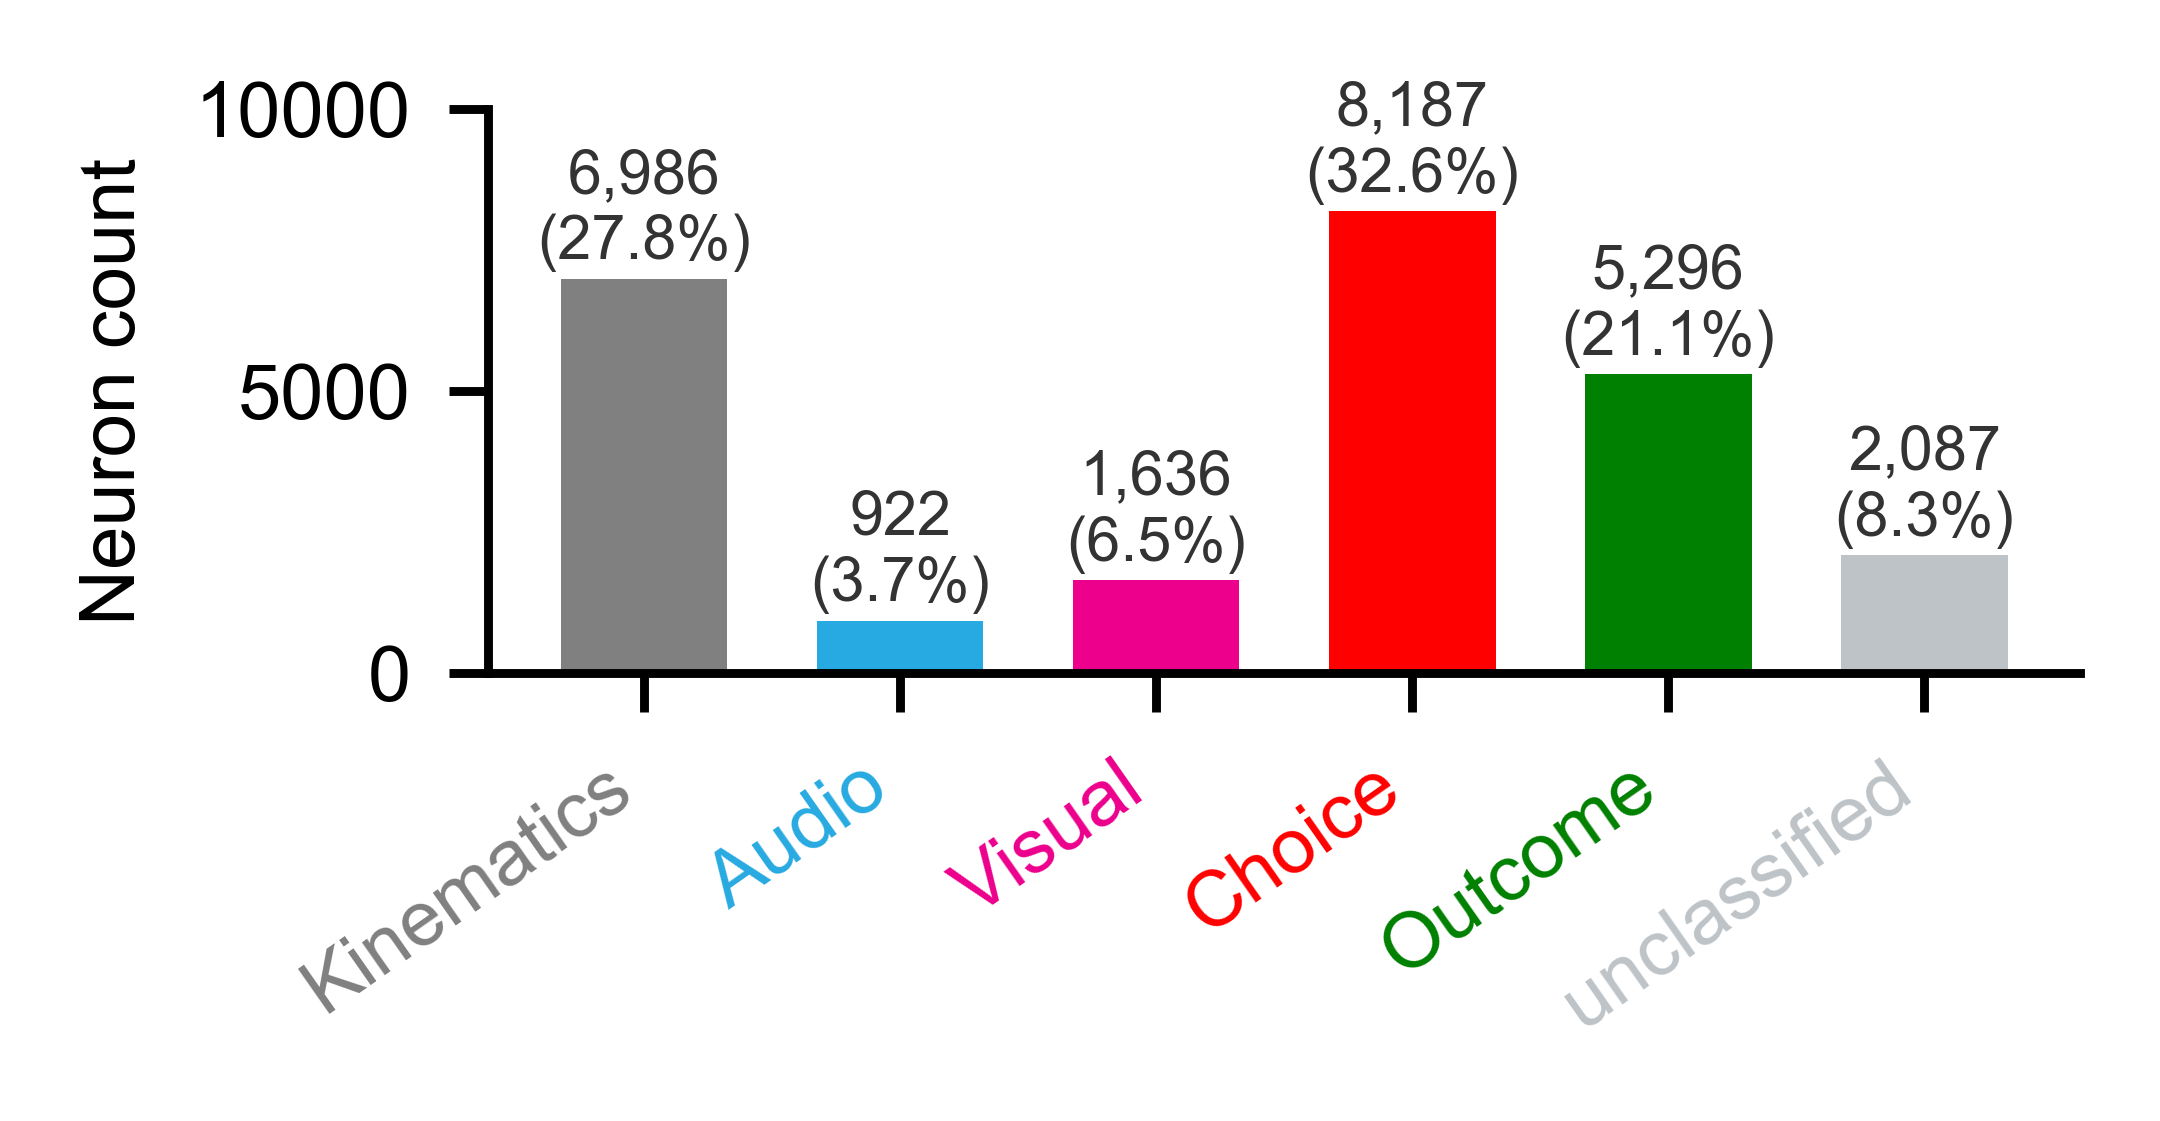

In [18]:
CLASS_COLORS_MERGED = {**MERGE_COLORS, 'mixed': '#95A5A6', 'unclassified': '#BDC3C7'}
group_to_merge = {g: cat for cat, groups in MERGE_GROUPS.items() for g in groups}

def add_merged_class(df):
    df = df.copy()
    df['merged_class'] = df['neuron_class'].map(
        lambda x: group_to_merge.get(x, x) if x is not None and x == x else 'unclassified'
    )
    counts = df[df['is_responsive']]['merged_class'].value_counts()
    print('Responsive neuron class breakdown:')
    for cls, n in counts.items():
        print(f'  {cls:<15s}  {n:>6,}')
    return df

df_uni = add_merged_class(df_uni)

def plot_neuron_class_counts(df, figsize=(2.8, 1.5)):
    resp_df = df[df['is_responsive']].copy()

    # Collapse mixed → unclassified; NaN → unclassified
    resp_df['merged_class_plot'] = (
        resp_df['merged_class']
        .replace({'mixed': 'unclassified'})
        .fillna('unclassified')
    )

    plot_order  = MERGE_ORDER + ['unclassified']
    plot_colors = [MERGE_COLORS.get(c, CLASS_COLORS_MERGED.get(c, '#AAAAAA')) for c in plot_order]

    counts = resp_df['merged_class_plot'].value_counts()
    ns     = [counts.get(cls, 0) for cls in plot_order]
    total  = sum(ns)   # use plotted neurons as denominator so percentages sum to 100%

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    bars = ax.bar(range(len(plot_order)), ns,
                  color=plot_colors, edgecolor='none', width=0.65, zorder=2)

    for i, (bar, n) in enumerate(zip(bars, ns)):
        if n == 0:
            continue
        ax.text(i, n + total * 0.005,
                f'{n:,}\n({n/total*100:.1f}%)',
                ha='center', va='bottom', fontsize=5.5, color='#333333')

    ax.set_xticks(range(len(plot_order)))
    ax.set_xticklabels(plot_order, rotation=35, ha='right', fontsize=7)
    ax.set_ylabel('Neuron count', fontsize=7)
    ax.set_ylim(0, 10000)

    for tick, color in zip(ax.get_xticklabels(), plot_colors):
        tick.set_color(color)

    sns.despine()
    plt.tight_layout()
    return fig

fig_counts = plot_neuron_class_counts(df_uni)
plt.savefig('figures/neuron_class_counts.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

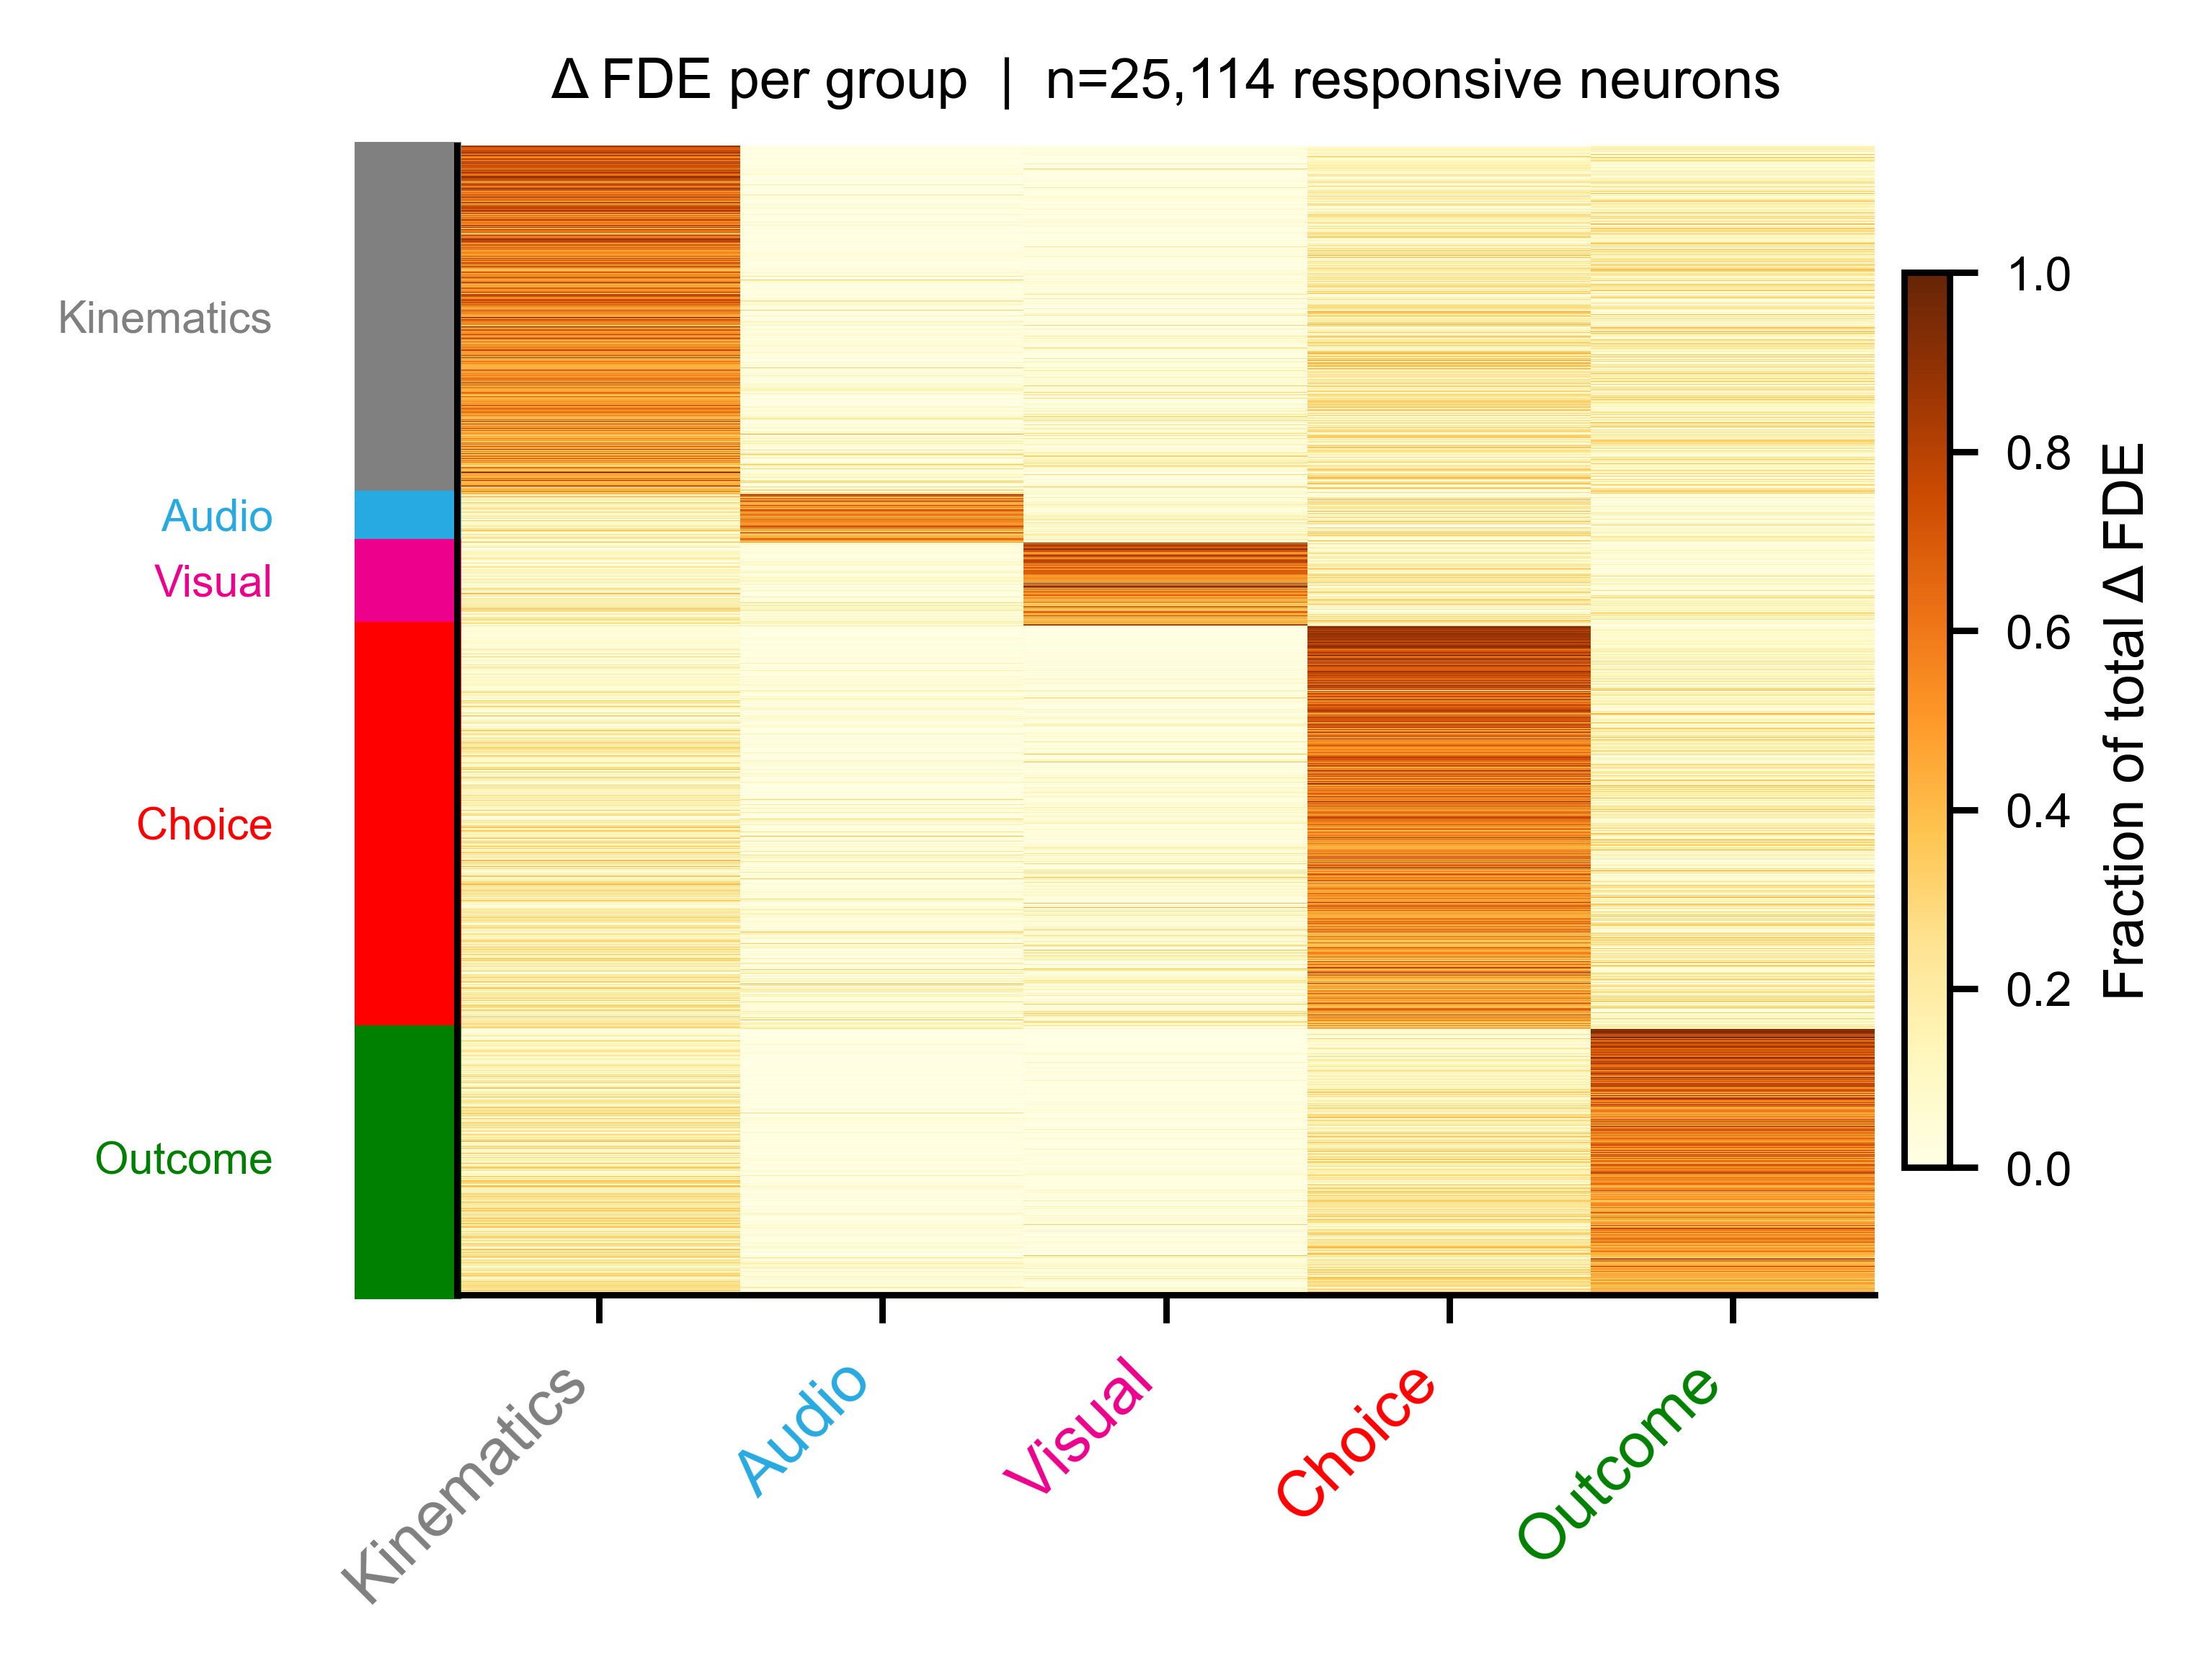

In [19]:
def plot_delta_heatmap(
    X_delta,
    df_delta_resp,
    sort_by   = 'dominant_group',
    normalise = 'row',
    figsize   = (4, 3),
    cmap      = 'YlOrBr',
):
    groups_raw = df_delta_resp.columns.tolist()

    # ── Merge predictor groups ────────────────────────────────────────────────
    MERGE_GROUPS = {
        'Kinematics': ['position_only', 'velocity'],
        'Audio':      ['audio_context', 'audio_stim'],
        'Visual':     ['visual_context', 'visual_stim'],
        'Choice':     ['choice_spatial', 'turn_onset'],
        'Outcome':    ['outcome'],
    }
    MERGE_COLORS = {
        'Kinematics': 'grey',
        'Audio':      '#27AAE1',
        'Visual':     '#EC008C',
        'Choice':     'red',
        'Outcome':    'green',
    }
    MERGE_ORDER = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome']

    df_merged = pd.DataFrame(index=df_delta_resp.index)
    for merged_name, src_cols in MERGE_GROUPS.items():
        present = [c for c in src_cols if c in groups_raw]
        df_merged[merged_name] = df_delta_resp[present].sum(axis=1)

    groups = MERGE_ORDER
    mat    = np.clip(df_merged[groups].to_numpy(), 0, None)

    # ── Build orig_to_merged once — handles both raw group names (legacy)
    #    and already-merged names (new build_neuron_df) ──────────────────────
    orig_to_merged = {}
    for merged, srcs in MERGE_GROUPS.items():
        for s in srcs:
            orig_to_merged[s] = merged          # raw → merged
    orig_to_merged.update({k: k for k in MERGE_ORDER})   # merged → merged (identity)
    orig_to_merged.update({'mixed': 'mixed', 'unclassified': 'unclassified'})

    # ── Sort rows ─────────────────────────────────────────────────────────────
    meta = df_uni.loc[df_delta_resp.index]

    if sort_by == 'dominant_group':
        group_rank = {g: i for i, g in
                      enumerate(MERGE_ORDER + ['mixed', 'unclassified'])}
        merged_dom = meta['dominant_group'].map(orig_to_merged).fillna('unclassified')
        sort_keys  = (
            merged_dom.map(group_rank).fillna(99).values * 1e6
            - meta['dominant_delta'].fillna(0).values
        )
        order = np.argsort(sort_keys)
    elif sort_by in groups:
        order = np.argsort(-mat[:, groups.index(sort_by)])
    else:
        raise ValueError(f'sort_by must be "dominant_group" or one of {groups}')

    mat      = mat[order]
    meta_ord = meta.iloc[order]

    # ── Normalise ─────────────────────────────────────────────────────────────
    if normalise == 'row':
        row_sum = mat.sum(axis=1, keepdims=True)
        row_sum[row_sum == 0] = 1
        mat        = mat / row_sum
        cbar_label = 'Fraction of total Δ FDE'
        vmin, vmax = 0, 1
    elif normalise == 'zscore':
        from scipy.stats import zscore as _zscore
        mat        = np.nan_to_num(_zscore(mat, axis=1))
        cbar_label = 'Z-score across groups'
        vmin, vmax = -2, 2
    else:
        cbar_label = 'Δ frac. deviance'
        vmin, vmax = 0, np.percentile(mat[mat > 0], 99) if mat.max() > 0 else 1

    # ── Plot ──────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    im = ax.imshow(mat, aspect='auto', cmap=cmap,
                   interpolation='nearest', vmin=vmin, vmax=vmax)

    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels(groups, rotation=45, ha='right', fontsize=8)
    ax.set_yticks([])

    for tick, grp in zip(ax.get_xticklabels(), groups):
        tick.set_color(MERGE_COLORS[grp])

    cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label(cbar_label, fontsize=7)
    cbar.ax.tick_params(labelsize=6)

    # ── Class boundary lines + colour bar in left margin ─────────────────────
    if sort_by == 'dominant_group':
        merged_dom_ord = meta_ord['dominant_group'].map(orig_to_merged).fillna('unclassified').values
        prev, start    = merged_dom_ord[0], 0
        boundaries     = []
        for i, cls in enumerate(merged_dom_ord):
            if cls != prev:
                boundaries.append((start, i, prev))
                prev, start = cls, i
        boundaries.append((start, len(merged_dom_ord), prev))

        for s, e, cls in boundaries:
            color = MERGE_COLORS.get(cls, '#aaaaaa')
            ax.add_patch(plt.Rectangle(
                (-0.5 - 0.35, s - 0.5), 0.35, e - s,
                color=color, clip_on=False, transform=ax.transData,
            ))
            ax.text(-0.5 - 0.65, (s + e) / 2, cls,
                    ha='right', va='center', fontsize=5.5,
                    color=color, transform=ax.transData)

    ax.set_title(f'Δ FDE per group  |  n={len(mat):,} responsive neurons',
                 fontsize=7)
    plt.tight_layout()
    return fig


figure = plot_delta_heatmap(X_delta, df_delta_resp)
save_path = 'figures/delta_heatmap.svg'
plt.savefig(save_path, bbox_inches='tight', facecolor='white', edgecolor='none')

In [20]:
# ── Step 1: build df_delta_resp (responsive neurons only) ─────────────────────
RESP_THRESHOLD = 0.1

delta_cols = [f'delta_fd_{g}' for g in M1_GROUPS
              if f'delta_fd_{g}' in df_uni.columns]

df_resp = df_uni[df_uni['is_responsive']].copy()

df_delta_resp = df_resp[delta_cols].copy()
df_delta_resp.columns = [c.replace('delta_fd_', '') for c in delta_cols]
df_delta_resp = df_delta_resp.dropna()

print(f'Responsive neurons: {len(df_delta_resp):,} / {len(df_uni):,} '
      f'({len(df_delta_resp)/len(df_uni)*100:.1f}%)')

# ── Step 2: build X_delta ─────────────────────────────────────────────────────
X_delta = df_delta_resp.to_numpy()

# ── Step 3: row-normalise → X_norm ────────────────────────────────────────────
X_clipped = np.clip(X_delta, 0, None)
row_sum   = X_clipped.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1
X_norm    = X_clipped / row_sum

print(f'X_delta shape: {X_delta.shape}')
print(f'X_norm shape:  {X_norm.shape}')
print(f'NaNs in X_norm: {np.isnan(X_norm).sum()}')
print(f'Row sums (should all be ~1): min={X_norm.sum(axis=1).min():.3f}  '
      f'max={X_norm.sum(axis=1).max():.3f}')
print(f'Groups: {df_delta_resp.columns.tolist()}')

Responsive neurons: 25,114 / 60,495 (41.5%)
X_delta shape: (25114, 9)
X_norm shape:  (25114, 9)
NaNs in X_norm: 0
Row sums (should all be ~1): min=1.000  max=1.000
Groups: ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']


Responsive neurons : 25,114
X_norm shape       : (25114, 9)   (neurons × 9 groups)
NaNs in X_norm     : 0
Row sums — min=1.000  max=1.000

PCs to explain 90% variance: 5
PCs to explain 95% variance: 5


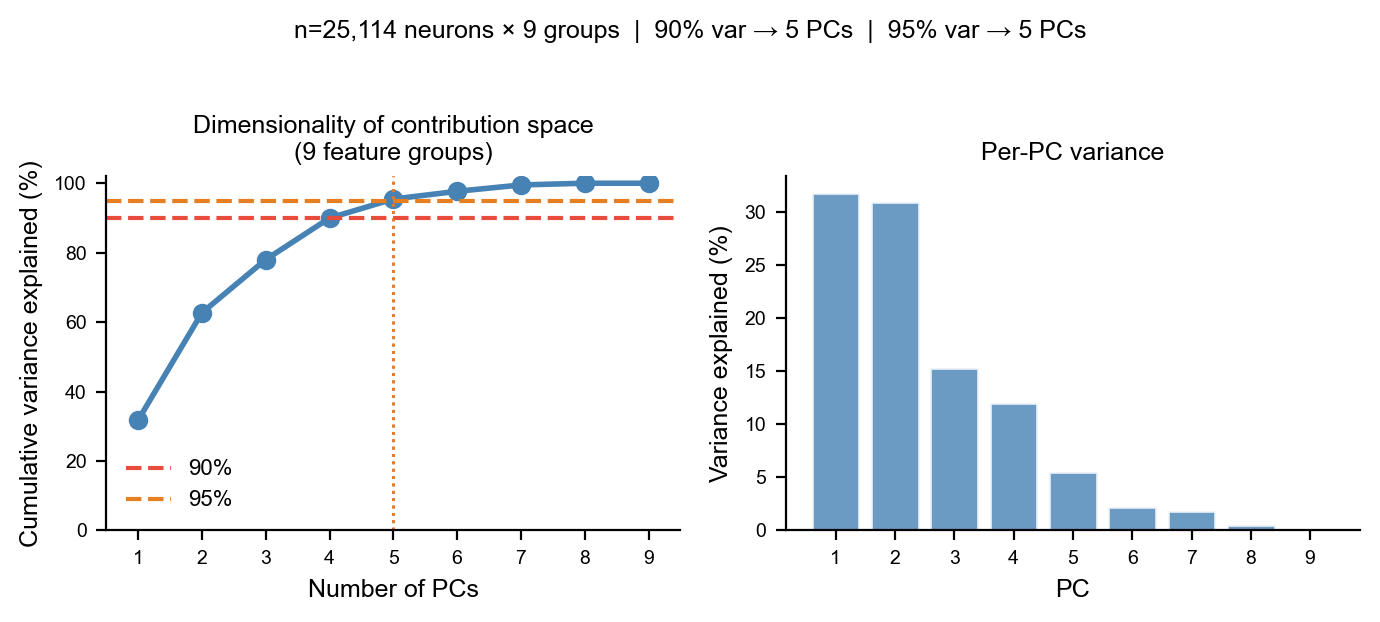


PC loadings (rows=groups, cols=PCs):
                  PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8    PC9
position_only  -0.011 -0.009 -0.000  0.013  0.033  0.059  0.020  0.940 -0.333
audio_context  -0.040 -0.068  0.049  0.159  0.785 -0.473 -0.008 -0.119 -0.333
audio_stim     -0.010 -0.023  0.024  0.061  0.184  0.615 -0.670 -0.150 -0.333
visual_context -0.027 -0.038  0.024  0.101  0.133  0.530  0.740 -0.173 -0.333
visual_stim    -0.054 -0.089  0.263  0.734 -0.461 -0.213 -0.054 -0.099 -0.333
velocity        0.837 -0.241 -0.209 -0.193 -0.158 -0.127 -0.002 -0.095 -0.333
choice_spatial -0.525 -0.436 -0.525 -0.254 -0.225 -0.143 -0.022 -0.108 -0.333
turn_onset     -0.134  0.046  0.706 -0.563 -0.166 -0.128 -0.000 -0.098 -0.333
outcome        -0.035  0.857 -0.331 -0.058 -0.125 -0.120 -0.003 -0.098 -0.333


In [21]:
# ── Step 1: build df_delta_resp (responsive neurons, original 9 groups) ───────
delta_cols = [f'delta_fd_{g}' for g in M1_GROUPS
              if f'delta_fd_{g}' in df_uni.columns]

df_resp       = df_uni[df_uni['is_responsive']].copy()
df_delta_resp = df_resp[delta_cols].copy()
df_delta_resp.columns = [c.replace('delta_fd_', '') for c in delta_cols]
df_delta_resp = df_delta_resp.dropna()

# ── Step 2: build X_norm directly from 9 groups (no merging) ─────────────────
X_clipped = df_delta_resp.clip(lower=0).to_numpy()
row_sum   = X_clipped.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1
X_norm    = X_clipped / row_sum

n_groups  = X_norm.shape[1]   # 9

print(f'Responsive neurons : {len(df_delta_resp):,}')
print(f'X_norm shape       : {X_norm.shape}   (neurons × 9 groups)')
print(f'NaNs in X_norm     : {np.isnan(X_norm).sum()}')
print(f'Row sums — min={X_norm.sum(axis=1).min():.3f}  max={X_norm.sum(axis=1).max():.3f}')

# ── Step 3: PCA on 9-group X_norm ────────────────────────────────────────────
pca      = PCA()
pca.fit(X_norm)

cumvar    = np.cumsum(pca.explained_variance_ratio_)
n_dims_90 = np.searchsorted(cumvar, 0.90) + 1
n_dims_95 = np.searchsorted(cumvar, 0.95) + 1

print(f'\nPCs to explain 90% variance: {n_dims_90}')
print(f'PCs to explain 95% variance: {n_dims_95}')

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(7, 3), dpi=200)

# Left: cumulative explained variance
ax = axes[0]
ax.plot(range(1, n_groups + 1), cumvar * 100, 'o-',
        color='steelblue', lw=2, markersize=6)
ax.axhline(90, color='#E74C3C', lw=1.5, ls='--', label='90%')
ax.axhline(95, color='#E67E22', lw=1.5, ls='--', label='95%')
ax.axvline(n_dims_90, color='#E74C3C', lw=1, ls=':')
ax.axvline(n_dims_95, color='#E67E22', lw=1, ls=':')
ax.set_xlabel('Number of PCs', fontsize=9)
ax.set_ylabel('Cumulative variance explained (%)', fontsize=9)
ax.set_title('Dimensionality of contribution space\n(9 feature groups)', fontsize=9)
ax.set_xlim(0.5, n_groups + 0.5)
ax.set_xticks(range(1, n_groups + 1))
ax.set_ylim(0, 102)
ax.legend(fontsize=8, frameon=False)
sns.despine(ax=ax)

# Right: per-PC variance
ax = axes[1]
bar_colors = [GROUP_COLORS.get(g, '#AAAAAA') for g in M1_GROUPS
              if f'delta_fd_{g}' in df_uni.columns]

ax.bar(range(1, n_groups + 1),
       pca.explained_variance_ratio_ * 100,
       color='steelblue', alpha=0.8, edgecolor='white')

# Loadings heatmap inset (optional but informative)
ax.set_xlabel('PC', fontsize=9)
ax.set_ylabel('Variance explained (%)', fontsize=9)
ax.set_title('Per-PC variance', fontsize=9)
ax.set_xticks(range(1, n_groups + 1))
sns.despine(ax=ax)

plt.suptitle(
    f'n={X_norm.shape[0]:,} neurons × {n_groups} groups  |  '
    f'90% var → {n_dims_90} PCs  |  95% var → {n_dims_95} PCs',
    fontsize=9, y=1.02
)
plt.tight_layout()
plt.show()

# ── PC loadings table ─────────────────────────────────────────────────────────
group_names = df_delta_resp.columns.tolist()
loadings_df = pd.DataFrame(
    pca.components_.T,
    index   = group_names,
    columns = [f'PC{i+1}' for i in range(n_groups)]
)
print('\nPC loadings (rows=groups, cols=PCs):')
print(loadings_df.round(3).to_string())

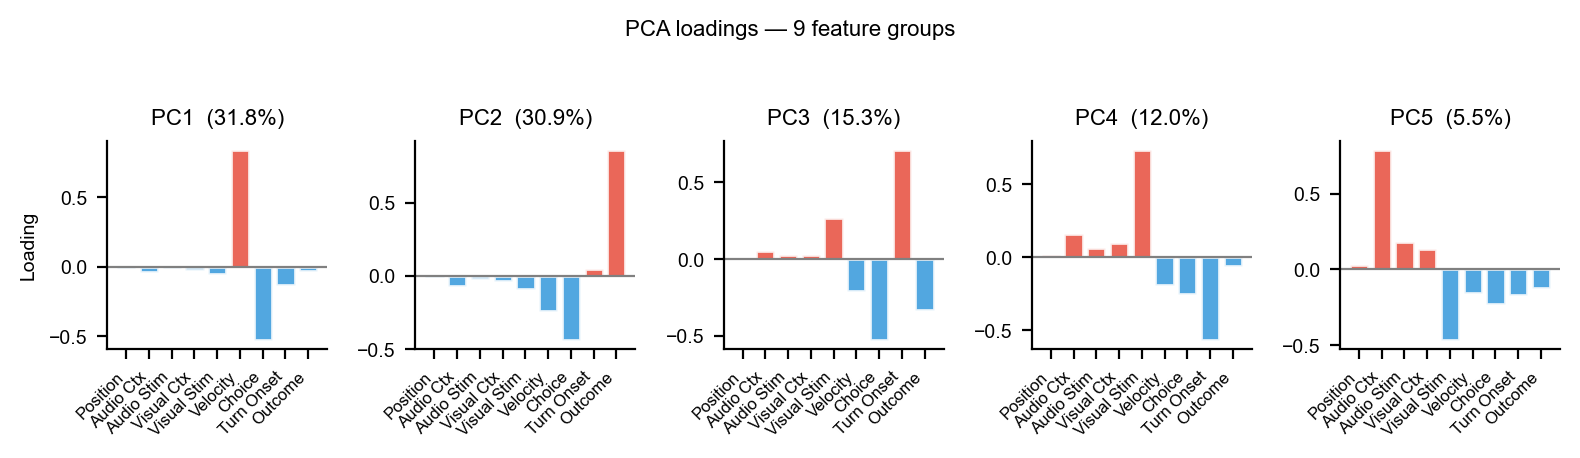

In [22]:
# ── PC loadings plot (9 groups) ───────────────────────────────────────────────
groups   = df_delta_resp.columns.tolist()   # 9 group names from the data itself
n_pcs    = pca.n_components_               # 9
n_plot   = min(n_pcs, 5)                   # show top 5 PCs max

fig, axes = plt.subplots(1, n_plot, figsize=(n_plot * 1.6, 2.2), dpi=200, sharey=False)

for i, ax in enumerate(axes):
    loadings = pca.components_[i]          # shape (9,)
    colors   = ['#E74C3C' if v > 0 else '#3498DB' for v in loadings]
    ax.bar(range(len(groups)), loadings, color=colors, edgecolor='white', alpha=0.85)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels(
        [GROUP_LABELS.get(g, g) for g in groups],
        rotation=45, ha='right', fontsize=6
    )
    ax.set_title(f'PC{i+1}  ({pca.explained_variance_ratio_[i]*100:.1f}%)',
                 fontsize=8)
    if i == 0:
        ax.set_ylabel('Loading', fontsize=7)

plt.suptitle('PCA loadings — 9 feature groups', fontsize=8, y=1.02)
sns.despine()
plt.tight_layout()
plt.show()

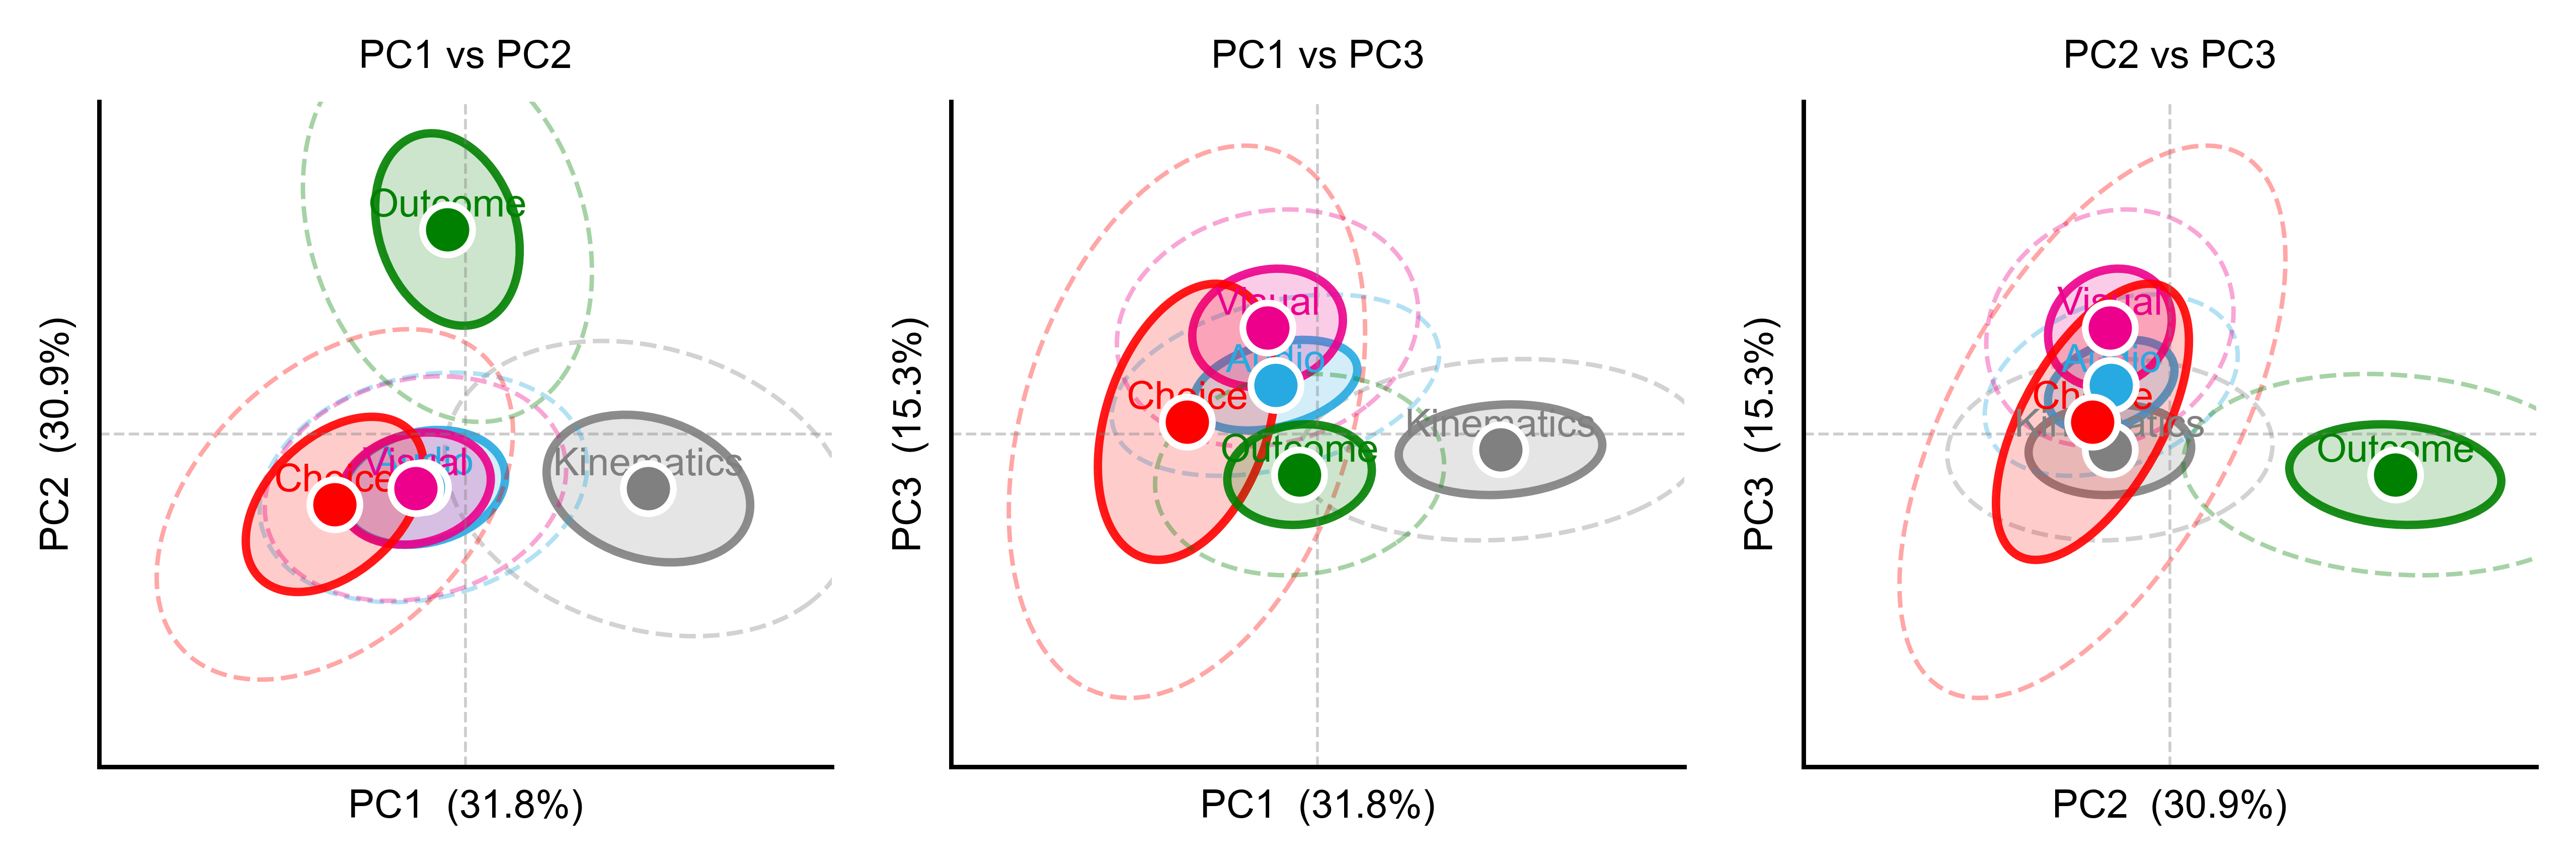

In [23]:
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

def confidence_ellipse(x, y, ax, n_std=1.0, facecolor='none', **kwargs):
    if len(x) < 3:
        return
    cov     = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    rx      = np.sqrt(1 + pearson)
    ry      = np.sqrt(1 - pearson)
    ellipse = Ellipse((0, 0), width=rx*2, height=ry*2,
                      facecolor=facecolor, **kwargs)
    scale_x = np.sqrt(cov[0, 0]) * n_std
    scale_y = np.sqrt(cov[1, 1]) * n_std
    t = (transforms.Affine2D()
         .rotate_deg(45)
         .scale(scale_x, scale_y)
         .translate(np.mean(x), np.mean(y)))
    ellipse.set_transform(t + ax.transData)
    ax.add_patch(ellipse)

# ── PCA scores (9-group) ──────────────────────────────────────────────────────
scores = pca.transform(X_norm)   # (n_neurons, 9)

# ── Map dominant_group → cloud label ─────────────────────────────────────────
# Handles both raw group names (legacy) and already-merged names (new)
orig_to_cloud = {
    # raw sub-group names
    'position_only':  'kinematics',
    'velocity':       'kinematics',
    'audio_context':  'audio',
    'audio_stim':     'audio',
    'visual_context': 'visual',
    'visual_stim':    'visual',
    'choice_spatial': 'choice',
    'turn_onset':     'choice',
    'outcome':        'outcome',
    # merged category names (identity mapping)
    'Kinematics':     'kinematics',
    'Audio':          'audio',
    'Visual':         'visual',
    'Choice':         'choice',
    'Outcome':        'outcome',
    # catch-all
    'mixed':          'mixed',
    'unclassified':   'unclassified',
}

meta = df_uni.loc[df_delta_resp.index]
cloud_labels_per_neuron = meta['dominant_group'].map(orig_to_cloud).fillna('unclassified')

CLOUD_COLORS = {
    'kinematics':   'grey',
    'audio':        MERGE_COLORS['Audio'],
    'visual':       MERGE_COLORS['Visual'],
    'choice':       'red',
    'outcome':      'green',
    'mixed':        CLASS_COLORS['mixed'],
    'unclassified': CLASS_COLORS['unclassified'],
}
CLOUD_LABELS = {
    'kinematics':   'Kinematics',
    'audio':        'Audio',
    'visual':       'Visual',
    'choice':       'Choice',
    'outcome':      'Outcome',
    'mixed':        'Mixed',
    'unclassified': 'Unclassified',
}

PLOT_CLOUDS = ['kinematics', 'audio', 'visual', 'choice', 'outcome']

# ── PC scatter plots ──────────────────────────────────────────────────────────
pc_pairs = [(0, 1), (0, 2), (1, 2)]

fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.25), dpi=800)

for ax, (px, py) in zip(axes, pc_pairs):
    for cloud in PLOT_CLOUDS:
        mask = (cloud_labels_per_neuron == cloud).values
        if mask.sum() < 10:
            continue
        x, y  = scores[mask, px], scores[mask, py]
        color = CLOUD_COLORS[cloud]
        label = CLOUD_LABELS[cloud]

        confidence_ellipse(x, y, ax, n_std=1.0,
                           facecolor=color, alpha=0.2, edgecolor='none')
        confidence_ellipse(x, y, ax, n_std=1.0,
                           facecolor='none', edgecolor=color, lw=1.5, alpha=0.9)
        confidence_ellipse(x, y, ax, n_std=2.0,
                           facecolor='none', edgecolor=color, lw=0.8,
                           alpha=0.35, linestyle='--')

        cx, cy = np.mean(x), np.mean(y)
        ax.scatter(cx, cy, color=color, s=80, zorder=5,
                   edgecolors='white', linewidths=1.2)
        ax.text(cx, cy + 0.01, label,
                ha='center', va='bottom', fontsize=7,
                color=color)

    ax.axhline(0, color='gray', lw=0.5, ls='--', alpha=0.4)
    ax.axvline(0, color='gray', lw=0.5, ls='--', alpha=0.4)
    ax.set_xlim(-0.6,0.6)
    ax.set_ylim(-0.6,0.6)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    vx = pca.explained_variance_ratio_[px] * 100
    vy = pca.explained_variance_ratio_[py] * 100
    ax.set_xlabel(f'PC{px+1}  ({vx:.1f}%)', fontsize=7)
    ax.set_ylabel(f'PC{py+1}  ({vy:.1f}%)', fontsize=7)
    ax.set_title(f'PC{px+1} vs PC{py+1}', fontsize=7)
    sns.despine(ax=ax)

handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=CLOUD_COLORS[c], markersize=8,
               label=f'{CLOUD_LABELS[c]}  (n={(cloud_labels_per_neuron==c).sum():,})')
    for c in PLOT_CLOUDS
]
plt.tight_layout()
plt.savefig('figures/pca_scatter_9groups.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Pairwise centroid angles in PC1–PC5 space
(variance-weighted)

Pair                            cos θ    θ (°)
----------------------------------------------
  Kinematics vs Audio          -0.276    106.0°
  Kinematics vs Visual         -0.262    105.2°
  Kinematics vs Choice         -0.665    131.7°
  Kinematics vs Outcome        -0.375    112.0°
  Audio vs Visual              +0.798     37.1°
  Audio vs Choice              +0.674     47.6°
  Audio vs Outcome             -0.613    127.8°
  Visual vs Choice             +0.473     61.8°
  Visual vs Outcome            -0.442    116.2°
  Choice vs Outcome            -0.425    115.2°


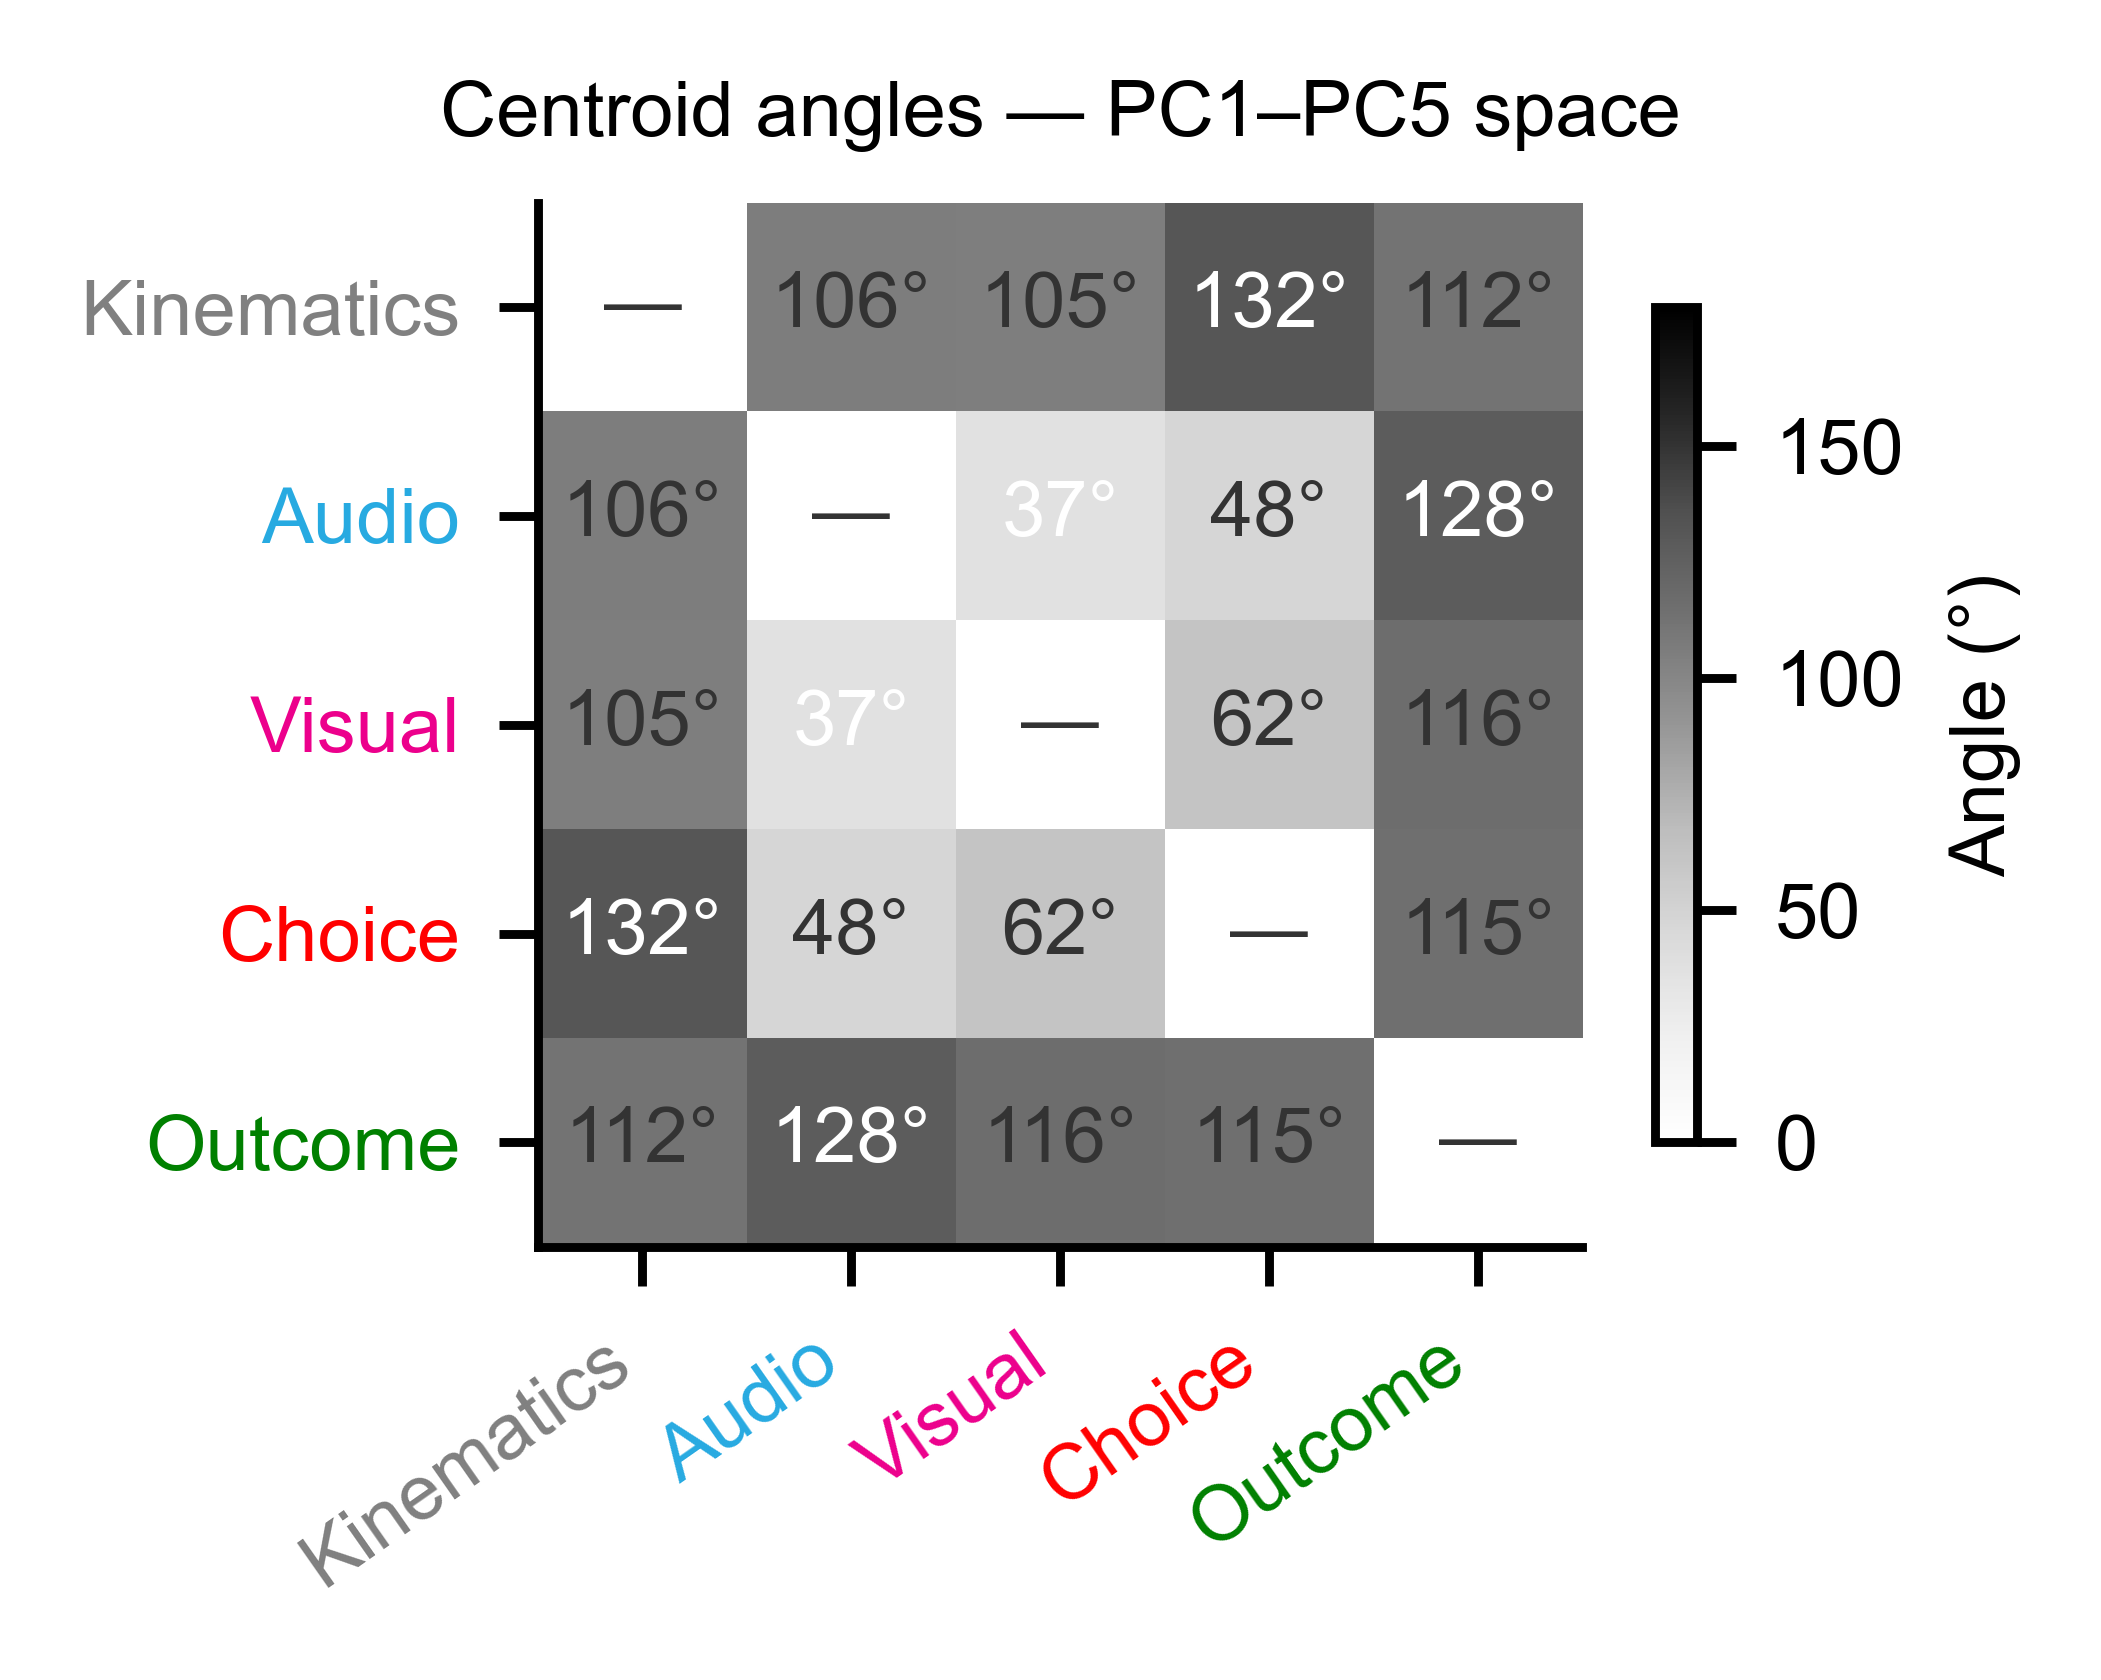

In [24]:
from scipy.spatial.distance import cosine as cosine_dist
from itertools import combinations

N_PCS = 5   # use top 3 PCs (76% variance)

# ── Compute centroids in PC space ─────────────────────────────────────────────
centroids = {}
for cloud in PLOT_CLOUDS:
    mask = (cloud_labels_per_neuron == cloud).values
    if mask.sum() < 10:
        continue
    centroids[cloud] = scores[mask, :N_PCS].mean(axis=0)

# Optional: variance-weight the centroid coordinates
var_w = pca.explained_variance_ratio_[:N_PCS]
centroids_w = {k: v * var_w for k, v in centroids.items()}

# ── Pairwise angles ───────────────────────────────────────────────────────────
print(f'Pairwise centroid angles in PC1–PC{N_PCS} space\n'
      f'(variance-weighted)\n')
print(f'{"Pair":<28s}  {"cos θ":>7s}  {"θ (°)":>7s}')
print('-' * 46)

clouds_present = list(centroids_w.keys())
angle_matrix   = np.zeros((len(clouds_present), len(clouds_present)))

for i, j in combinations(range(len(clouds_present)), 2):
    ci = centroids_w[clouds_present[i]]
    cj = centroids_w[clouds_present[j]]
    cos_sim = 1 - cosine_dist(ci, cj)
    cos_sim = np.clip(cos_sim, -1, 1)
    angle   = np.degrees(np.arccos(cos_sim))
    angle_matrix[i, j] = angle
    angle_matrix[j, i] = angle
    pair_str = f'{CLOUD_LABELS[clouds_present[i]]} vs {CLOUD_LABELS[clouds_present[j]]}'
    print(f'  {pair_str:<26s}  {cos_sim:>+7.3f}  {angle:>7.1f}°')

# ── Angle matrix heatmap ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(2.8, 2.2), dpi=800)
labels  = [CLOUD_LABELS[c] for c in clouds_present]
colors  = [CLOUD_COLORS[c]  for c in clouds_present]

im = ax.imshow(angle_matrix, cmap='Greys', vmin=0, vmax=180)

for i in range(len(clouds_present)):
    for j in range(len(clouds_present)):
        val = angle_matrix[i, j]
        ax.text(j, i, f'{val:.0f}°' if i != j else '—',
                ha='center', va='center', fontsize=7,
                color='white' if val > 120 or (val > 0 and val < 40) else '#333333')

ax.set_xticks(range(len(clouds_present)))
ax.set_yticks(range(len(clouds_present)))
ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=7)
ax.set_yticklabels(labels, fontsize=7)

# Color the tick labels
for tick, color in zip(ax.get_xticklabels(), colors):
    tick.set_color(color)
for tick, color in zip(ax.get_yticklabels(), colors):
    tick.set_color(color)

plt.colorbar(im, ax=ax, label='Angle (°)', shrink=0.8)
ax.set_title(f'Centroid angles — PC1–PC{N_PCS} space', fontsize=7)
plt.tight_layout()
plt.savefig('figures/centroid_angles.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Class                 n  median CPI      p vs 0
--------------------------------------------------
  Kinematics      6,986      -0.014    4.40e-09
  Audio             922      -0.933   6.34e-137
  Visual          1,636      +0.510   5.80e-174
  Choice          8,187      +0.004    1.05e-01
  Outcome         5,296      -0.003    3.90e-02
  mixed           2,087      -0.026    1.93e-04


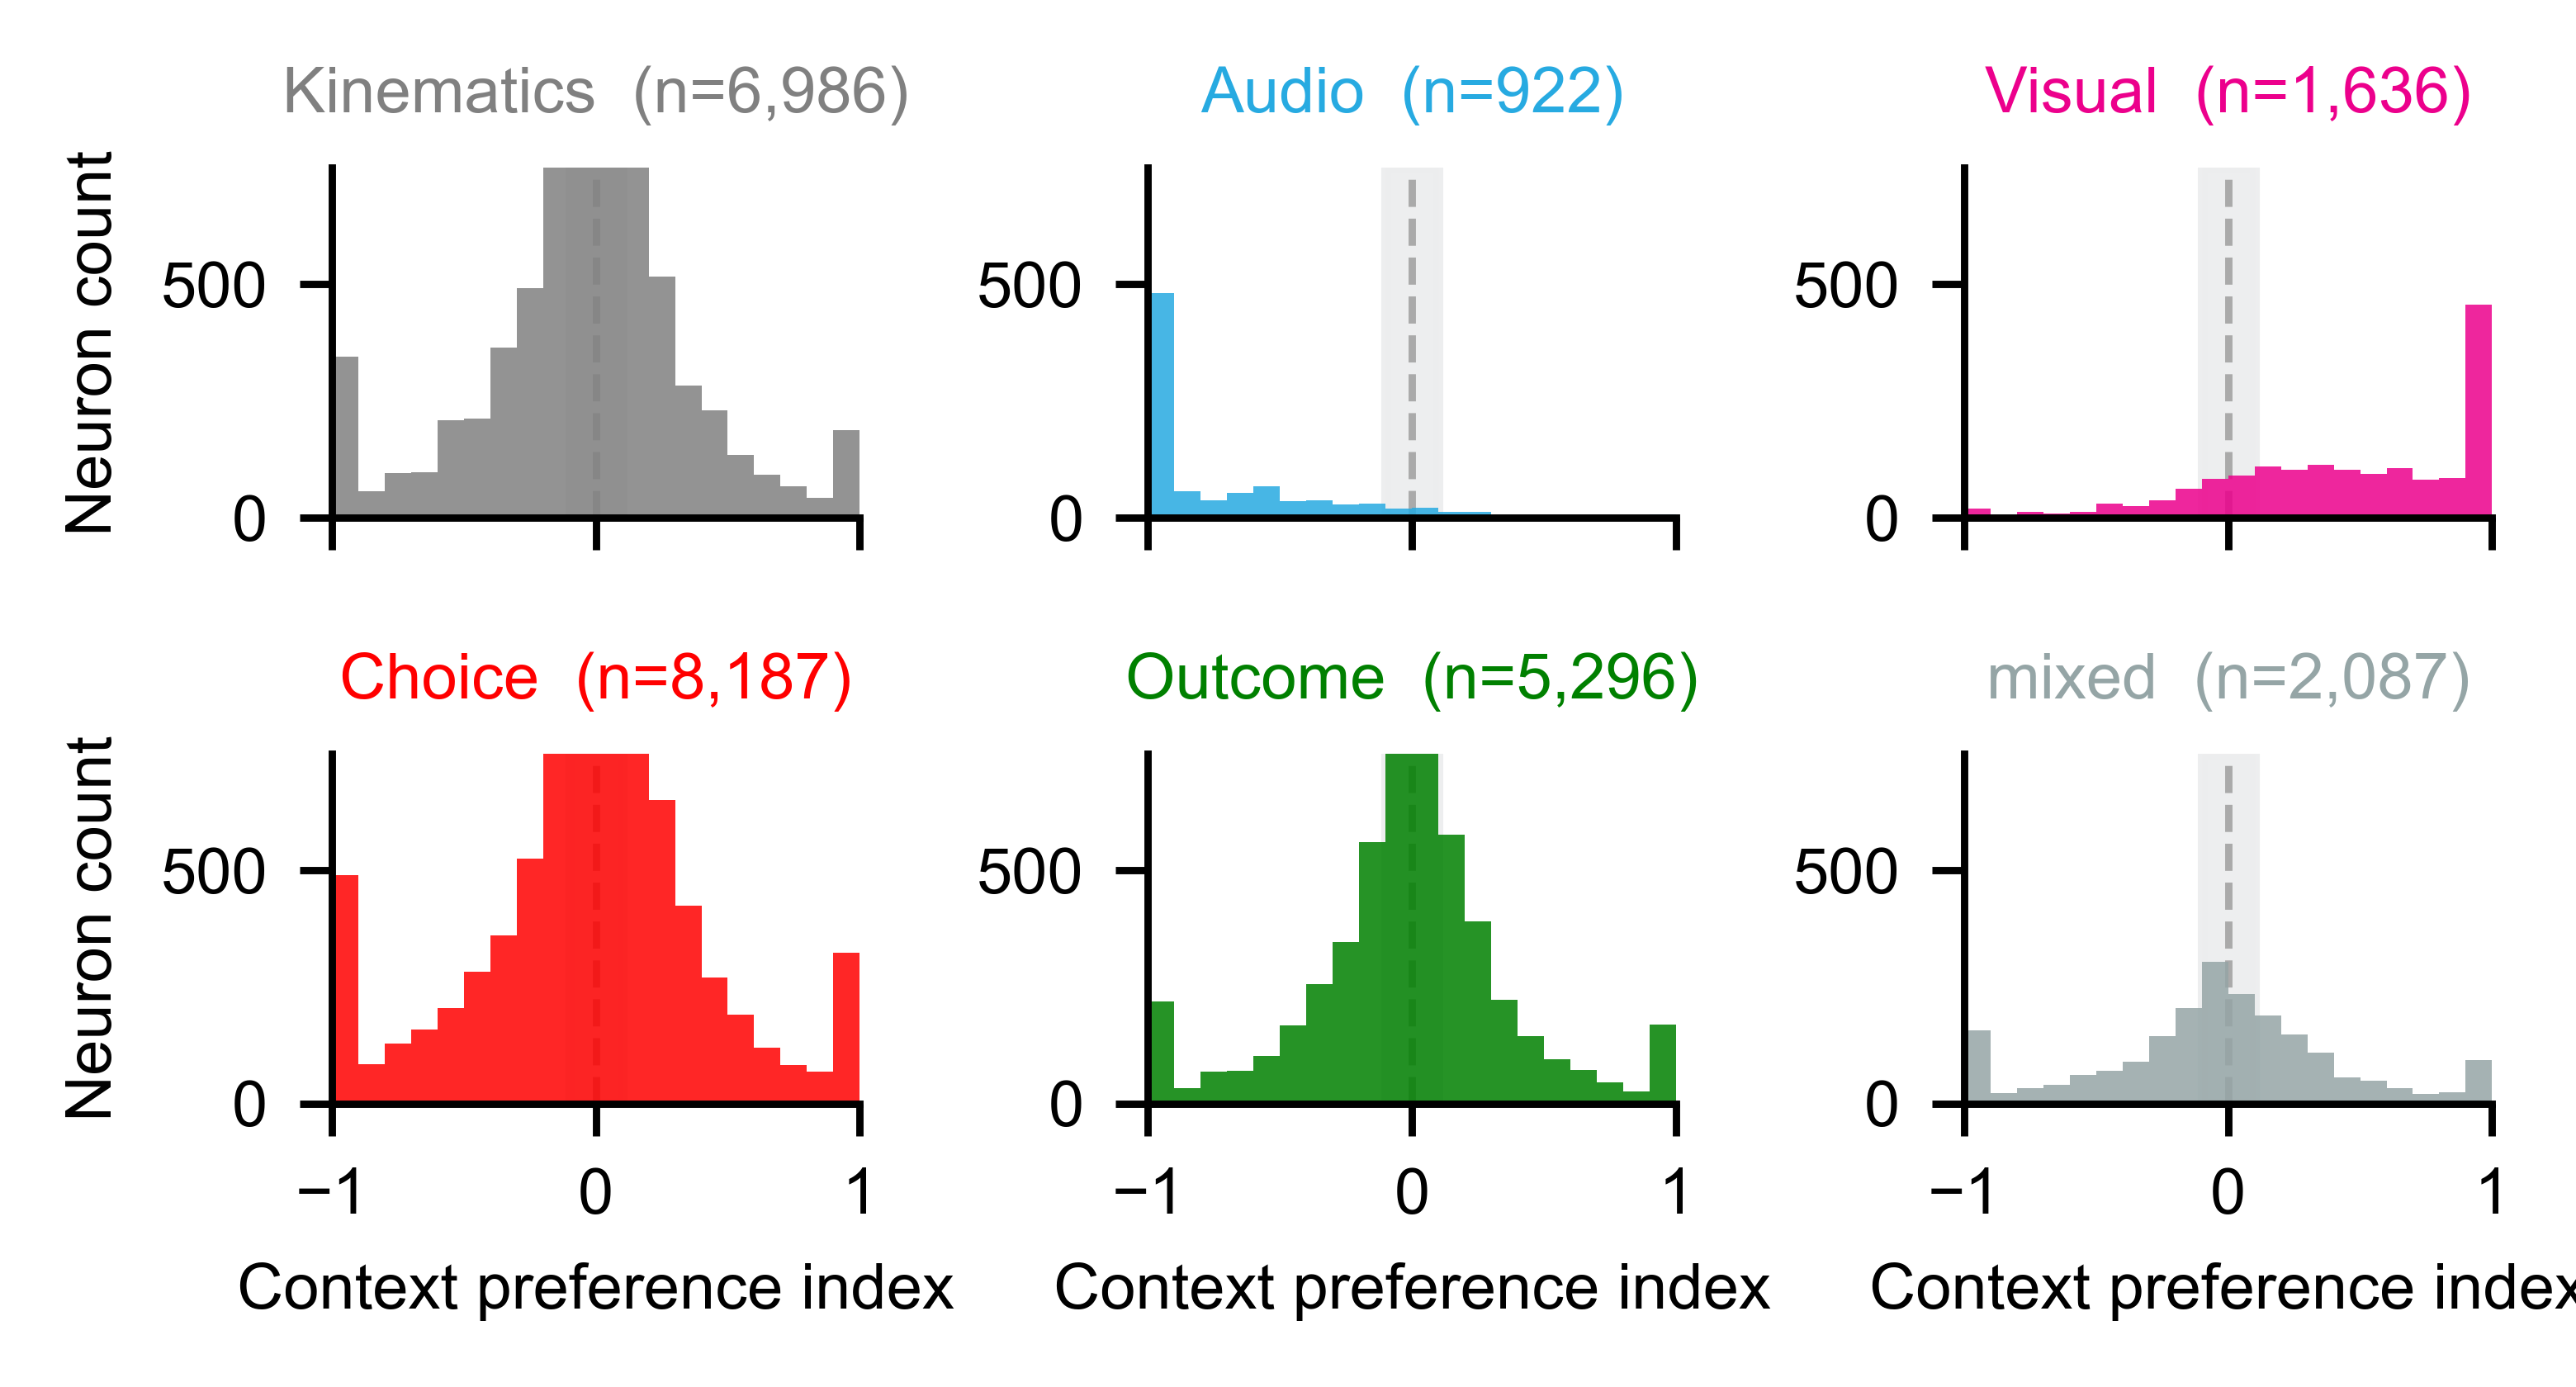

In [26]:
from scipy.stats import gaussian_kde, wilcoxon

PLOT_CLASSES  = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome', 'mixed']
CLASS_COLORS_MERGED = {**MERGE_COLORS, 'mixed': '#95A5A6', 'unclassified': '#BDC3C7'}

def plot_cpi_by_class_faceted(df, resp_threshold=0.1, invariant_thresh=0.1,
                               bins=20, figsize=(4, 2.2)):

    resp_df = df[df['is_responsive'] & df['merged_class'].isin(PLOT_CLASSES)].copy()

    n_cols = 3
    n_rows = int(np.ceil(len(PLOT_CLASSES) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize, dpi=800,
                             sharex=True, sharey=False)
    axes = axes.flatten()

    print(f'{"Class":<15s}  {"n":>6s}  {"median CPI":>10s}  {"p vs 0":>10s}')
    print('-' * 50)

    for idx, cls in enumerate(PLOT_CLASSES):
        ax    = axes[idx]
        color = CLASS_COLORS_MERGED.get(cls, '#AAAAAA')
        sub   = resp_df[resp_df['merged_class'] == cls]['vis_aud_ci'].dropna().values

        # Shaded invariant zone + centre line
        ax.axvspan(-invariant_thresh, invariant_thresh,
                   color='#ECEDEE', alpha=0.9, zorder=0)
        ax.axvline(0, color='#AAAAAA', lw=0.8, ls='--', zorder=1)

        if len(sub) < 10:
            ax.set_title(f'{cls}  (n={len(sub)})', fontsize=7, color=color)
            print(f'  {cls:<13s}  skipped (n={len(sub)})')
            continue

        ax.hist(sub, bins=bins, range=(-1, 1),
                color=color, alpha=0.85, edgecolor='none', zorder=2)

        median = np.median(sub)
        # ax.axvline(median, color='k', lw=1.0, ls='-', zorder=3,
        #            label=f'median={median:+.2f}')

        try:
            _, p_val = wilcoxon(sub)
            p_str = f'{p_val:.2e}'
        except Exception:
            p_str = 'n/a'

        ax.set_title(f'{cls}  (n={len(sub):,})', fontsize=7, color=color)
        # ax.text(1.2, 0.95, f'med={median:+.2f}\np={p_str}',
        #         transform=ax.transAxes, fontsize=5.5,
        #         ha='right', va='top', color='#333333')

        ax.set_xlim(-1, 1)
        ax.set_ylim(0,750)
        ax.set_ylim(bottom=0)
        sns.despine(ax=ax)

        print(f'  {cls:<13s}  {len(sub):>6,}  {median:>+10.3f}  {p_str:>10s}')

    # Shared axis labels
    for ax in axes[n_cols * (n_rows - 1):]:
        ax.set_xlabel('Context preference index', fontsize=7)
    for ax in axes[::n_cols]:
        ax.set_ylabel('Neuron count', fontsize=7)

    # Hide any unused panels
    for ax in axes[len(PLOT_CLASSES):]:
        ax.set_visible(False)

    # # Shared Audio/Visual pref annotations on bottom row
    # for ax in axes[n_cols * (n_rows - 1): n_cols * (n_rows - 1) + n_cols]:
    #     if ax.get_visible():
    #         ax.text(-0.97, ax.get_ylim()[1] * 0.92, 'Audio\npref.',
    #                 fontsize=5, color=CTX_COLORS_STR['audio'], va='top', ha='left')
    #         ax.text( 0.97, ax.get_ylim()[1] * 0.92, 'Visual\npref.',
    #                 fontsize=5, color=CTX_COLORS_STR['visual'], va='top', ha='right')

    #plt.suptitle('CPI distribution by neuron class', fontsize=8, y=1.01)
    plt.tight_layout()
    return fig

fig_cpi_facet = plot_cpi_by_class_faceted(df_uni)
plt.savefig('figures/cpi_by_neuron_class_faceted.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

# Coupling analysis 

Context                   p  sig
-----------------------------------
  frac_dev_visual  3.638e-12  ***
  frac_dev_audio  3.638e-12  ***


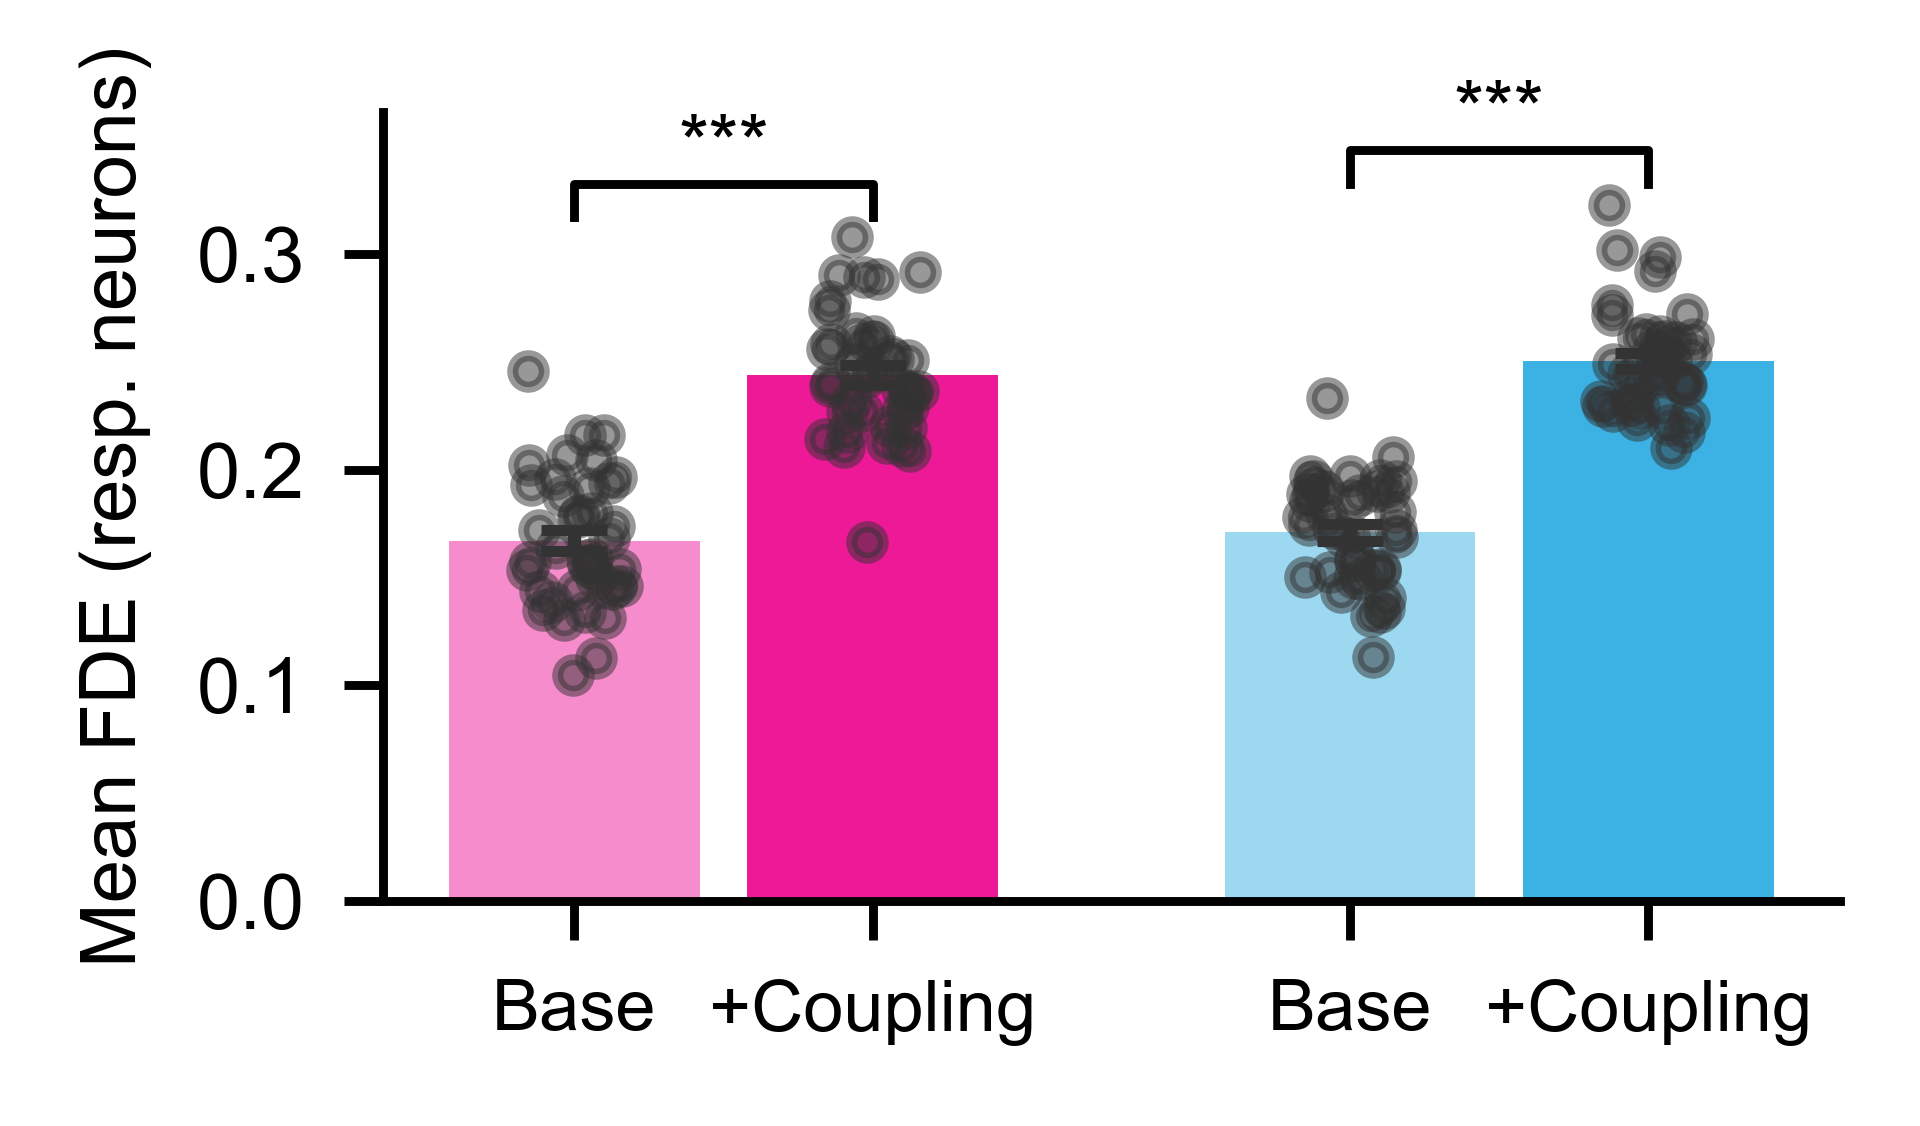

In [27]:
def plot_coupling_comparison(df_base, df_coup, resp_threshold=0.1, figsize=(2.5, 1.5)):
    """Bar plot: base vs coupling mean FDE for visual and audio contexts."""
    from scipy.stats import wilcoxon

    # Match neurons present in both models
    shared_idx = df_base.index.intersection(df_coup.index)
    base = df_base.loc[shared_idx]
    coup = df_coup.loc[shared_idx]

    # Use responsive in either model
    resp_mask = base['is_responsive'] | coup['is_responsive']
    base = base[resp_mask]
    coup = coup[resp_mask]

    # Session-level means
    def sess_means(df, col):
        return df.groupby(['mouse_ID', 'date'])[col].mean().reset_index()

    ctx_cols   = ['frac_dev_visual', 'frac_dev_audio']
    ctx_labels = ['Visual', 'Audio']
    ctx_colors = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio']]

    sess_base = {c: sess_means(base, c)[c].values for c in ctx_cols}
    sess_coup = {c: sess_means(coup, c)[c].values for c in ctx_cols}
    n_sess    = len(sess_base[ctx_cols[0]])

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    x_positions = [0, 0.5, 1.3, 1.8]
    labels      = ['Base', '+Coupling', 'Base', '+Coupling']
    values      = [sess_base['frac_dev_visual'], sess_coup['frac_dev_visual'],
                   sess_base['frac_dev_audio'],  sess_coup['frac_dev_audio']]
    colors      = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['visual'],
                   CTX_COLORS_STR['audio'],  CTX_COLORS_STR['audio']]
    alphas      = [0.45, 0.9, 0.45, 0.9]

    for xi, vals, color, alpha in zip(x_positions, values, colors, alphas):
        mean_v = vals.mean()
        sem_v  = vals.std() / np.sqrt(n_sess)
        ax.bar(xi, mean_v, width=0.42, color=color, alpha=alpha, edgecolor='none',
               yerr=sem_v, error_kw=dict(elinewidth=1.2, capsize=3, ecolor='#333333'),
               zorder=2)
        rng    = np.random.default_rng(seed=int(xi * 10))
        jitter = rng.uniform(-0.08, 0.08, size=n_sess)
        ax.scatter(xi + jitter, vals, color='#333333', s=8, alpha=0.5, zorder=3)

    # Wilcoxon: base vs coupling for each context
    print(f'{"Context":<15s}  {"p":>10s}  {"sig"}')
    print('-' * 35)
    for col, x_pair, color in zip(ctx_cols, [(0, 0.5), (1.3, 1.8)], ctx_colors):
        _, p   = wilcoxon(sess_base[col], sess_coup[col])
        x_mid  = np.mean(x_pair)
        y_top  = max(sess_coup[col].max(), sess_base[col].max())
        bar_h  = y_top * 1.08
        sig    = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        ax.plot([x_pair[0], x_pair[0], x_pair[1], x_pair[1]],
                [y_top * 1.03, bar_h, bar_h, y_top * 1.03], lw=0.8, color='k')
        ax.text(x_mid, bar_h, sig, ha='center', va='bottom', fontsize=7)
        print(f'  {col:<13s}  {p:.3e}  {sig}')

    ax.set_xticks(x_positions)
    ax.set_xticklabels(labels, fontsize=6.5)
    ax.set_ylabel('Mean FDE (resp. neurons)', fontsize=7)
    sns.despine()
    plt.tight_layout()
    return fig

fig_coup_bar = plot_coupling_comparison(df_uni, df_uni_coup)
plt.savefig('figures/coupling_fde_comparison.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Context            mean Δ      SEM      p vs 0
------------------------------------------------
  Visual          +0.0769   0.0031  3.638e-12
  Audio           +0.0793   0.0028  3.638e-12

  Visual vs Audio ΔFDE: p=1.847e-01  ns


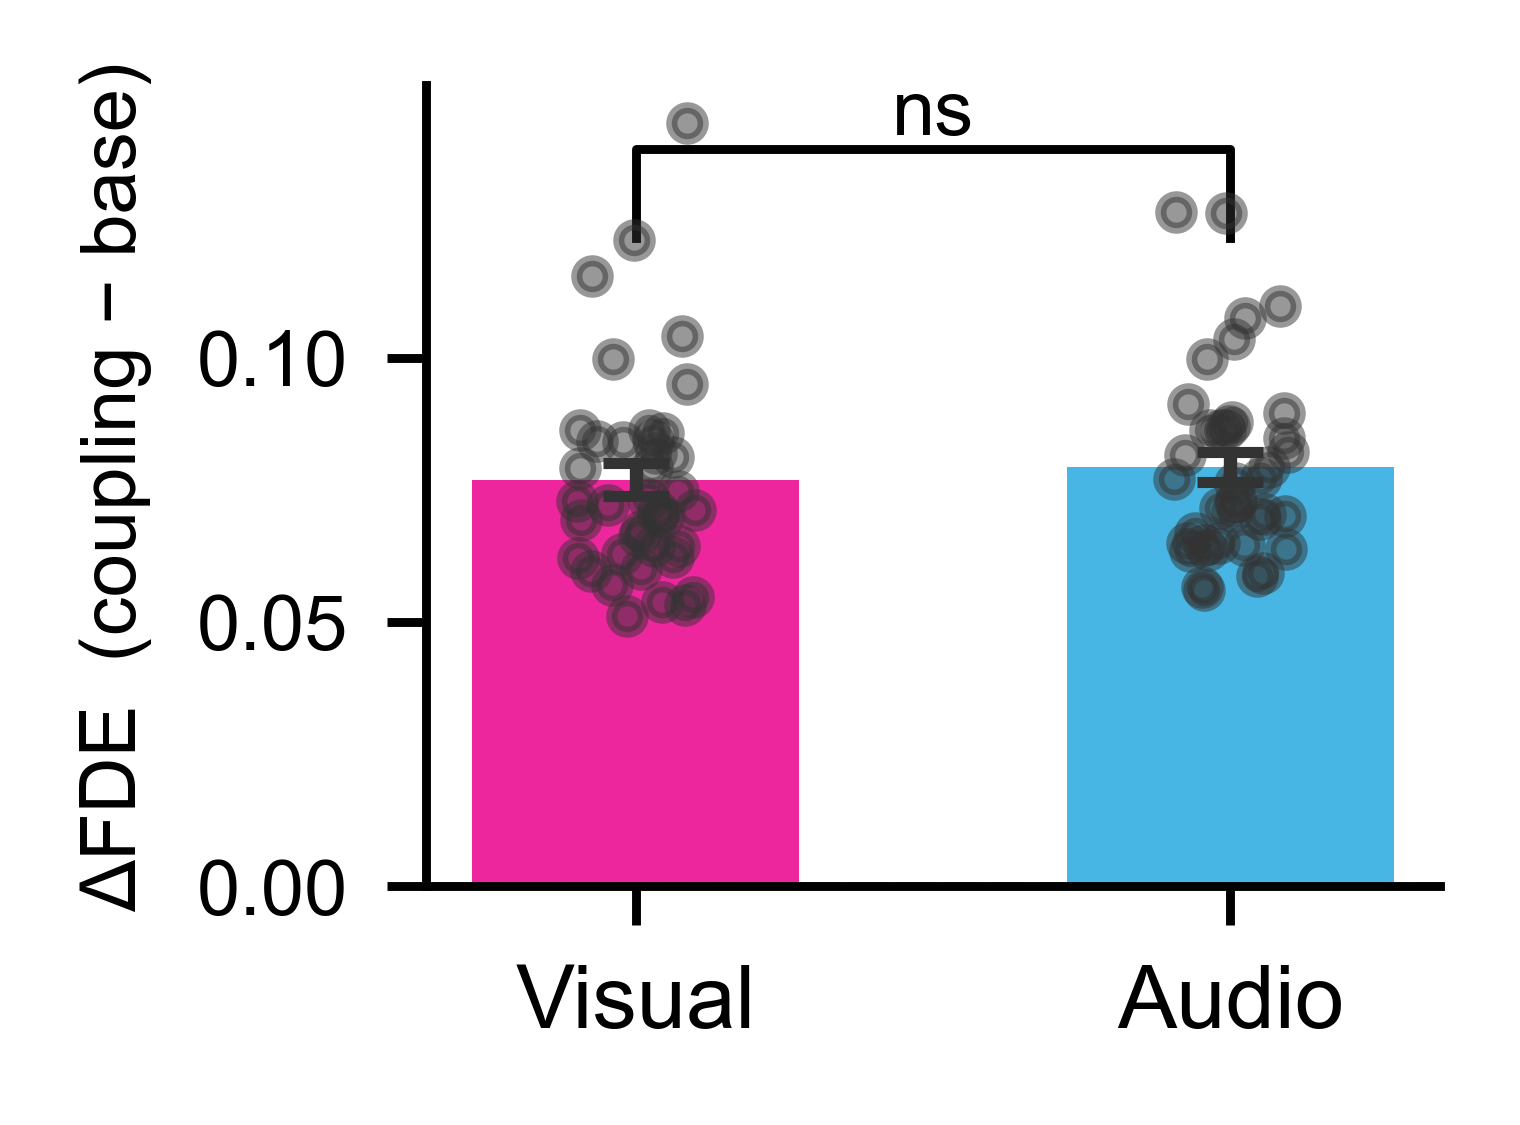

In [28]:
def plot_coupling_delta(df_base, df_coup, figsize=(2.0, 1.5)):
    from scipy.stats import wilcoxon

    shared_idx = df_base.index.intersection(df_coup.index)
    base = df_base.loc[shared_idx]
    coup = df_coup.loc[shared_idx]

    resp_mask  = base['is_responsive'] | coup['is_responsive']
    base, coup = base[resp_mask], coup[resp_mask]

    ctx_cols   = ['frac_dev_visual', 'frac_dev_audio']
    ctx_labels = ['Visual', 'Audio']
    ctx_colors = [CTX_COLORS_STR['visual'], CTX_COLORS_STR['audio']]

    combined = base[['mouse_ID', 'date']].copy()
    for col in ctx_cols:
        combined[f'delta_{col}'] = coup[col].values - base[col].values

    sess_delta = combined.groupby(['mouse_ID', 'date'])[
        [f'delta_{c}' for c in ctx_cols]
    ].mean().reset_index()

    fig, ax = plt.subplots(figsize=figsize, dpi=800)
    ax.axhline(0, color='#AAAAAA', lw=0.8, ls='--', zorder=1)

    print(f'{"Context":<15s}  {"mean Δ":>8s}  {"SEM":>7s}  {"p vs 0":>10s}')
    print('-' * 48)

    for i, (col, label, color) in enumerate(zip(ctx_cols, ctx_labels, ctx_colors)):
        vals = sess_delta[f'delta_{col}'].values
        vals = vals[vals > 0.01]          # remove exact-zero sessions

        mean_v = vals.mean()
        sem_v  = vals.std() / np.sqrt(len(vals))

        ax.bar(i, mean_v, yerr=sem_v, width=0.55,
               color=color, alpha=0.85, edgecolor='none',
               error_kw=dict(elinewidth=1.2, capsize=3, ecolor='#333333'),
               zorder=2)

        rng    = np.random.default_rng(seed=i)
        jitter = rng.uniform(-0.1, 0.1, size=len(vals))
        ax.scatter(i + jitter, vals, color='#333333', s=8, alpha=0.5, zorder=3)

        _, p = wilcoxon(vals)
        print(f'  {label:<13s}  {mean_v:>+8.4f}  {sem_v:>7.4f}  {p:.3e}')

    # Bracket comparing Visual vs Audio delta
    vis_vals = sess_delta['delta_frac_dev_visual'].values
    aud_vals = sess_delta['delta_frac_dev_audio'].values
    vis_vals = vis_vals[vis_vals != 0]
    aud_vals = aud_vals[aud_vals != 0]
    _, p_diff = wilcoxon(vis_vals[:len(aud_vals)], aud_vals[:len(vis_vals)])
    sig_diff  = '***' if p_diff < 0.001 else '**' if p_diff < 0.01 else '*' if p_diff < 0.05 else 'ns'
    y_bracket = ax.get_ylim()[1] * 0.92
    ax.plot([0, 0, 1, 1],
            [y_bracket * 0.88, y_bracket, y_bracket, y_bracket * 0.88],
            lw=0.8, color='k')
    ax.text(0.5, y_bracket, sig_diff, ha='center', va='bottom', fontsize=7)
    print(f'\n  Visual vs Audio ΔFDE: p={p_diff:.3e}  {sig_diff}')

    ax.set_xticks([0, 1])
    ax.set_xticklabels(ctx_labels, fontsize=8)
    ax.set_yticks([0, 0.05, 0.1])
    ax.set_ylabel('ΔFDE  (coupling − base)', fontsize=7)
    #ax.set_title(f'Coupling gain  |  N={len(sess_delta)} sessions', fontsize=7)
    sns.despine()
    plt.tight_layout()
    return fig

fig_coup_delta = plot_coupling_delta(df_uni, df_uni_coup)
plt.savefig('figures/coupling_delta_fde.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Pearson  r=-0.268  p=0.00e+00
Spearman r=-0.312  p=0.00e+00


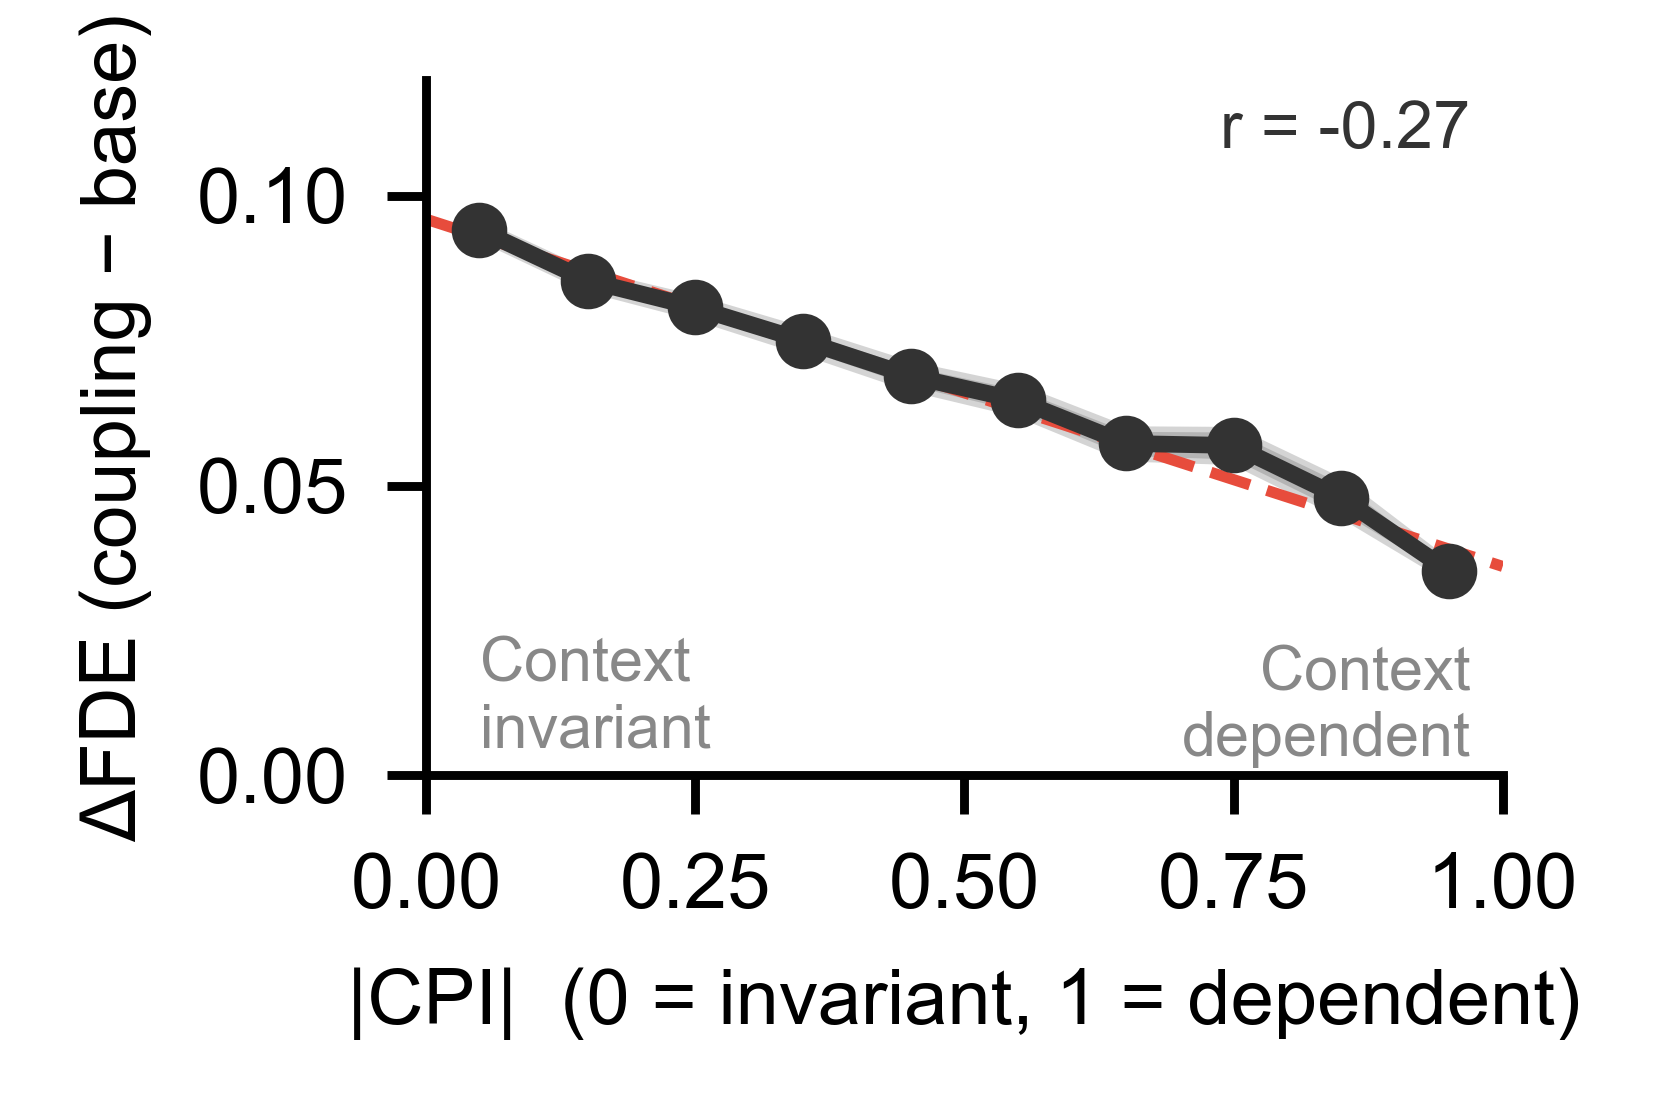

In [47]:
def plot_coupling_gain_vs_invariance(df_base, df_coup, n_bins=10, figsize=(2.2, 1.5)):
    """Does coupling gain depend on context invariance (|CPI|)?"""
    from scipy.stats import pearsonr, spearmanr

    shared_idx = df_base.index.intersection(df_coup.index)
    base = df_base.loc[shared_idx]
    coup = df_coup.loc[shared_idx]
    resp_mask = base['is_responsive']
    base = base[resp_mask].copy()
    coup = coup.loc[base.index]

    # Mean ΔFDE across both contexts per neuron
    base['delta_fde'] = (
        (coup['frac_dev_visual'].values - base['frac_dev_visual'].values) +
        (coup['frac_dev_audio'].values  - base['frac_dev_audio'].values)
    ) / 2

    base['abs_cpi'] = base['vis_aud_ci'].abs()

    # Bin by |CPI|
    base['cpi_bin'] = pd.cut(base['abs_cpi'], bins=n_bins)
    binned = base.groupby('cpi_bin', observed=True)['delta_fde'].agg(['mean', 'sem', 'count'])
    bin_centers = np.array([interval.mid for interval in binned.index])

    r_p, p_p = pearsonr(base['abs_cpi'], base['delta_fde'])
    r_s, p_s = spearmanr(base['abs_cpi'], base['delta_fde'])
    print(f'Pearson  r={r_p:.3f}  p={p_p:.2e}')
    print(f'Spearman r={r_s:.3f}  p={p_s:.2e}')

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    ax.fill_between(bin_centers,
                    binned['mean'] - binned['sem'],
                    binned['mean'] + binned['sem'],
                    alpha=0.25, color='#555555')
    ax.plot(bin_centers, binned['mean'], color='#333333',
            lw=1.5, marker='o', ms=4, zorder=3)

    # Regression line
    m, b   = np.polyfit(base['abs_cpi'], base['delta_fde'], 1)
    x_line = np.linspace(0, 1, 100)
    ax.plot(x_line, m * x_line + b, color='#E74C3C',
            lw=1.0, ls='--', zorder=2)

    ax.text(0.97, 0.97, f'r = {r_p:.2f}', #\np = {p_p:.2e}
            transform=ax.transAxes, fontsize=6,
            ha='right', va='top', color='#333333')

    # Shade invariant zone
    # ax.axvspan(0, 0.2, color='#ECEDEE', alpha=0.6, zorder=0,
    #            label='Context-invariant')
    # ax.axvline(0.2, color='#AAAAAA', lw=0.7, ls='--', zorder=1)

    ax.set_xlabel('|CPI|  (0 = invariant, 1 = dependent)', fontsize=7)
    ax.set_ylabel('ΔFDE (coupling − base)', fontsize=7)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 0.12)
    ax.set_ylim(bottom=0)

    ax.text(0.05, 0.2, 'Context\ninvariant', transform=ax.transAxes,
            fontsize=5.5, color='#888888', va='top')
    ax.text(0.97, 0.01, 'Context\ndependent', transform=ax.transAxes,
            fontsize=5.5, color='#888888', va='bottom', ha='right')

    sns.despine()
    plt.tight_layout()
    return fig

fig_gain_inv = plot_coupling_gain_vs_invariance(df_uni, df_uni_coup)
plt.savefig('figures/coupling_gain_vs_invariance.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Class               n   mean ΔFDE      p vs 0
----------------------------------------------
  Kinematics    6,986     +0.0751  0.00e+00
  Audio           922     +0.0227  7.67e-139
  Visual        1,636     +0.0299  2.03e-244
  Choice        8,187     +0.0788  0.00e+00
  Outcome       5,296     +0.0937  0.00e+00


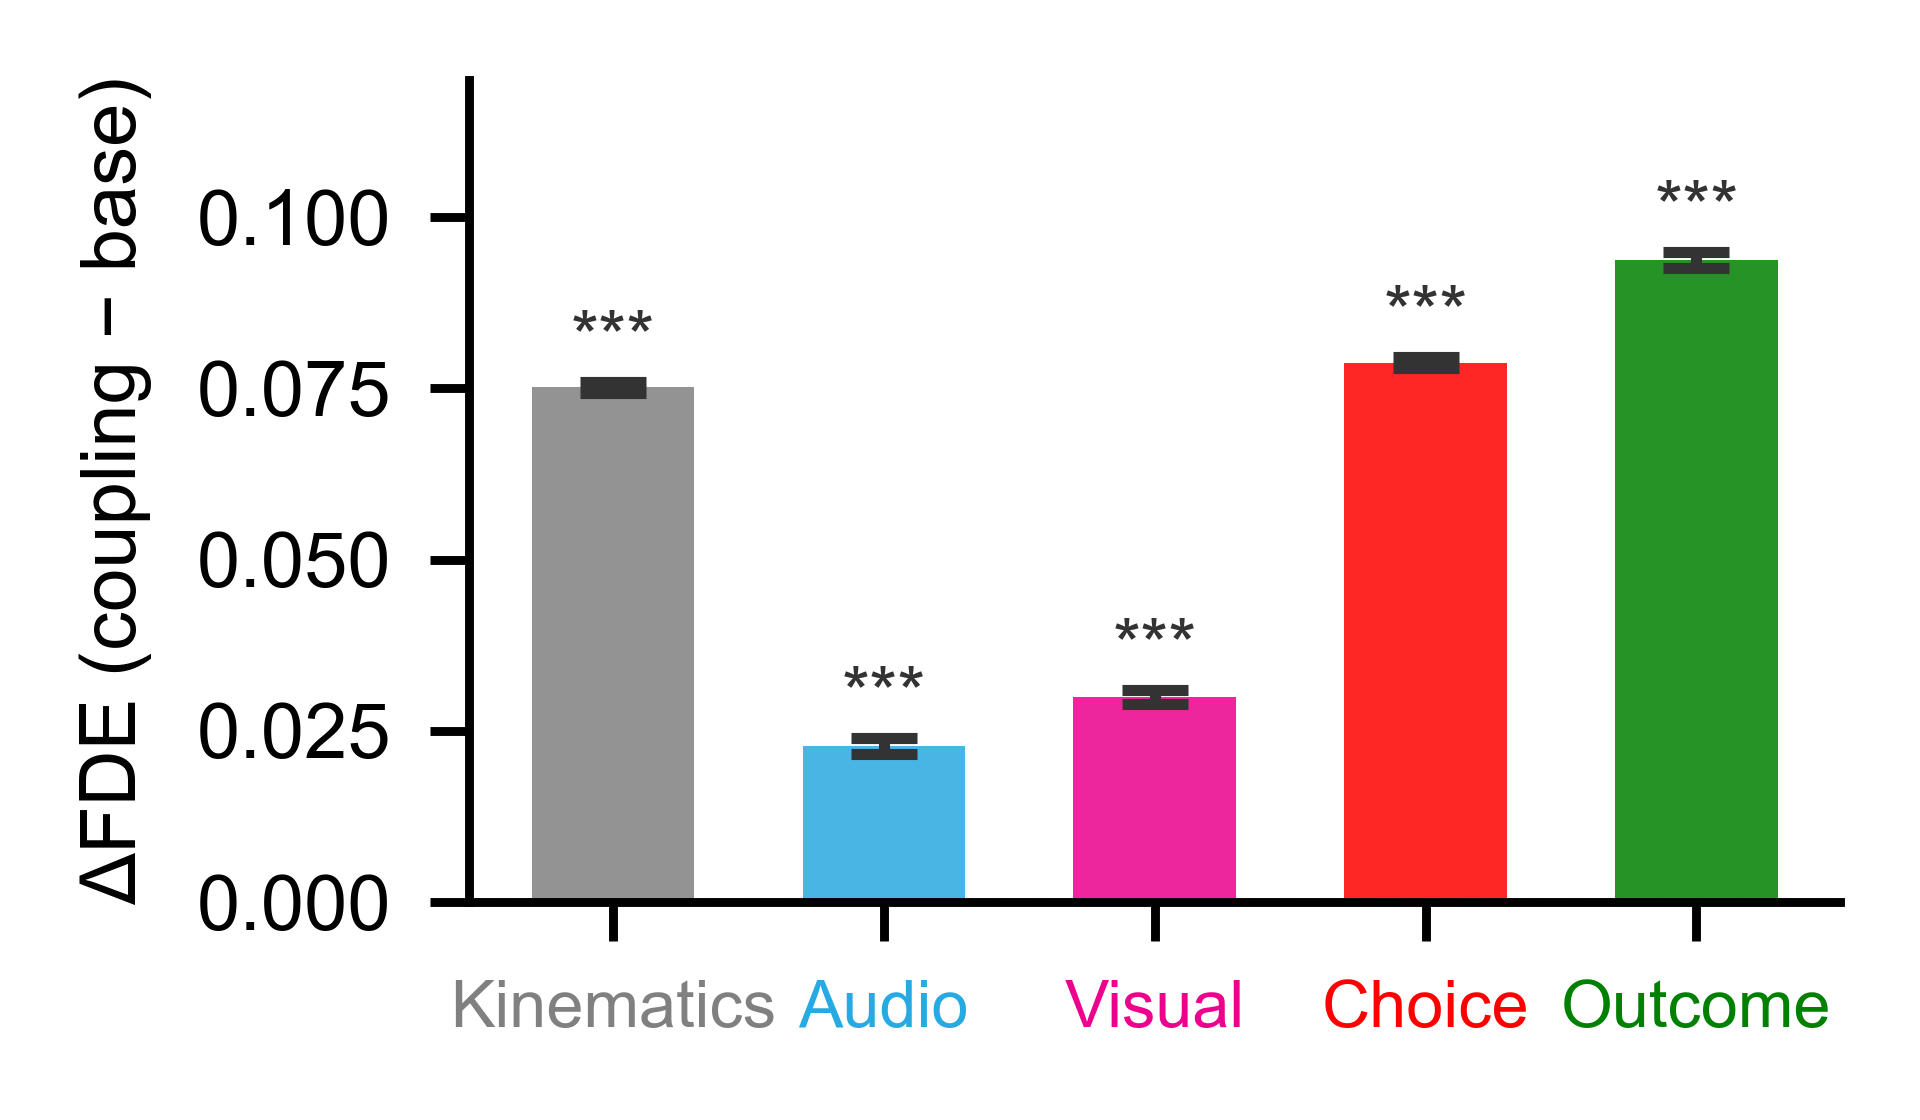

In [46]:
def plot_coupling_delta_by_class(df_base, df_coup, figsize=(2.5, 1.5)):
    """Bar: mean coupling ΔFDE per neuron class (averaged across vis + aud contexts)."""
    from scipy.stats import wilcoxon

    shared_idx = df_base.index.intersection(df_coup.index)
    base = df_base.loc[shared_idx]
    coup = df_coup.loc[shared_idx]
    resp_mask = base['is_responsive']
    base = base[resp_mask].copy()
    coup = coup.loc[base.index]

    # Mean ΔFDE across both contexts per neuron
    base['delta_fde'] = (
        (coup['frac_dev_visual'].values - base['frac_dev_visual'].values) +
        (coup['frac_dev_audio'].values  - base['frac_dev_audio'].values)
    ) / 2

    plot_order = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome']
    colors     = [MERGE_COLORS[c] for c in plot_order]

    fig, ax = plt.subplots(figsize=figsize, dpi=800)
    ax.axhline(0, color='#AAAAAA', lw=0.7, ls='--', zorder=1)

    print(f'{"Class":<13s}  {"n":>6s}  {"mean ΔFDE":>10s}  {"p vs 0":>10s}')
    print('-' * 46)

    for i, (cls, color) in enumerate(zip(plot_order, colors)):
        sub  = base[base['merged_class'] == cls]['delta_fde'].values
        if len(sub) < 5:
            continue
        mean_v = sub.mean()
        sem_v  = sub.std() / np.sqrt(len(sub))

        ax.bar(i, mean_v, width=0.6, color=color, alpha=0.85,
               edgecolor='none', yerr=sem_v,
               error_kw=dict(elinewidth=1.0, capsize=3, ecolor='#333333'),
               zorder=2)

        try:
            _, p = wilcoxon(sub)
        except Exception:
            p = np.nan
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        ax.text(i, mean_v + sem_v + 0.001, sig,
                ha='center', va='bottom', fontsize=6.5, color='#333333')
        print(f'  {cls:<11s}  {len(sub):>6,}  {mean_v:>+10.4f}  {p:.2e}')

    ax.set_xticks(range(len(plot_order)))
    ax.set_xticklabels(plot_order, fontsize=6)
    for tick, color in zip(ax.get_xticklabels(), colors):
        tick.set_color(color)
    ax.set_ylabel('ΔFDE (coupling − base)', fontsize=7)
    ax.set_ylim(0, 0.12)
    sns.despine()
    plt.tight_layout()
    return fig

fig_delta_class = plot_coupling_delta_by_class(df_uni, df_uni_coup)
plt.savefig('figures/coupling_delta_by_class.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Class               n        r           p
------------------------------------------
  Kinematics    6,986   -0.215  1.50e-73  ***
  Audio           922   -0.233  7.81e-13  ***
  Visual        1,636   -0.231  3.03e-21  ***
  Choice        8,187   -0.241  1.31e-108  ***
  Outcome       5,296   -0.145  2.07e-26  ***


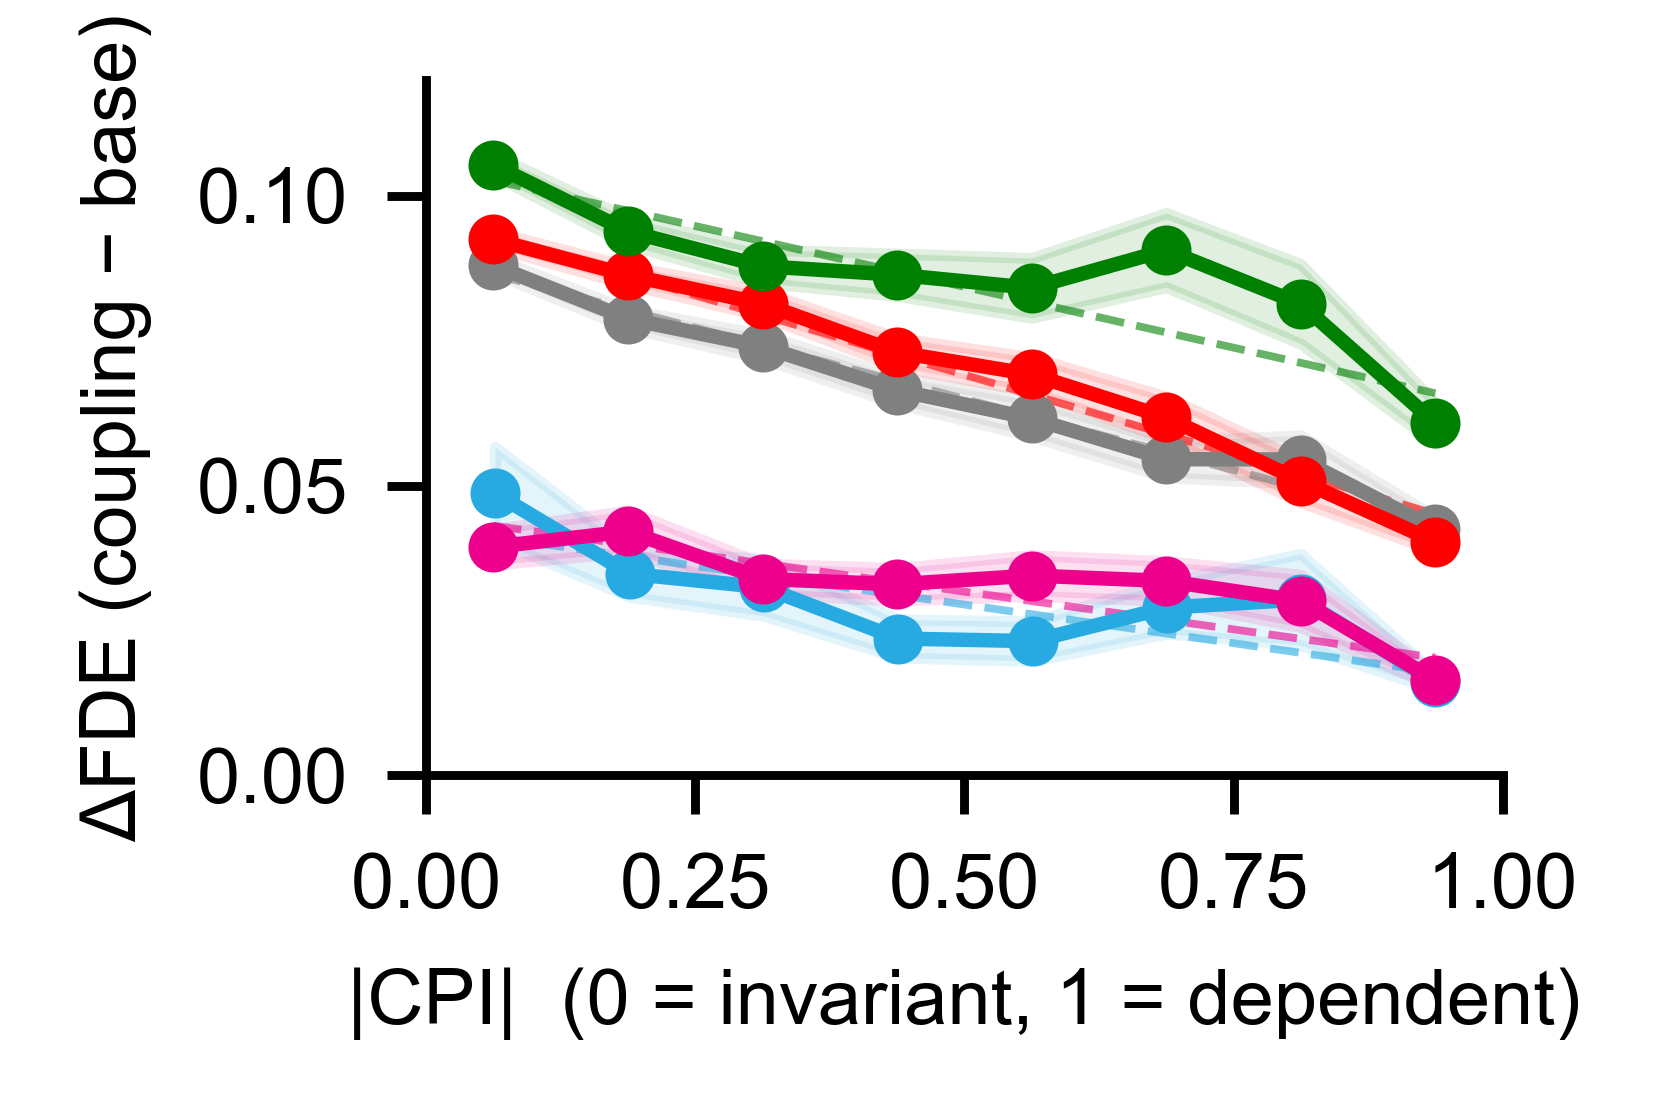

In [45]:
def plot_coupling_gain_vs_invariance_by_class(df_base, df_coup, n_bins=8, figsize=(2.2, 1.5)):
    from scipy.stats import pearsonr

    shared_idx = df_base.index.intersection(df_coup.index)
    base = df_base.loc[shared_idx]
    coup = df_coup.loc[shared_idx]
    resp_mask = base['is_responsive']
    base = base[resp_mask].copy()
    coup = coup.loc[base.index]

    base['delta_fde'] = (
        (coup['frac_dev_visual'].values - base['frac_dev_visual'].values) +
        (coup['frac_dev_audio'].values  - base['frac_dev_audio'].values)
    ) / 2
    base['abs_cpi'] = base['vis_aud_ci'].abs()

    plot_order = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome']

    fig, ax = plt.subplots(figsize=figsize, dpi=800)
    #ax.axvline(0.2, color='#AAAAAA', lw=0.7, ls='--', zorder=1)
    #ax.axhline(0,   color='#AAAAAA', lw=0.5, ls='--', zorder=1)

    print(f'{"Class":<13s}  {"n":>6s}  {"r":>7s}  {"p":>10s}')
    print('-' * 42)

    for cls in plot_order:
        color = MERGE_COLORS.get(cls, CLASS_COLORS_MERGED.get(cls, '#AAAAAA'))
        sub   = base[base['merged_class'] == cls]
        if len(sub) < 20:
            print(f'  {cls:<11s}  skipped (n={len(sub)})')
            continue

        sub = sub.copy()
        sub['cpi_bin'] = pd.cut(sub['abs_cpi'], bins=n_bins)
        binned = sub.groupby('cpi_bin', observed=True)['delta_fde'].agg(['mean', 'sem', 'count'])
        bin_centers = np.array([iv.mid for iv in binned.index])

        # Only plot bins with enough neurons
        valid = binned['count'] >= 5
        xv, yv, ev = bin_centers[valid], binned['mean'][valid].values, binned['sem'][valid].values

        ax.fill_between(xv, yv - ev, yv + ev, alpha=0.12, color=color)
        ax.plot(xv, yv, color=color, lw=1.3, marker='o', ms=3.5,
                label=f'{cls}  (n={len(sub):,})', zorder=3)

        # Regression line per class
        r, p = pearsonr(sub['abs_cpi'], sub['delta_fde'])
        m, b = np.polyfit(sub['abs_cpi'], sub['delta_fde'], 1)
        x_fit = np.linspace(xv.min(), xv.max(), 100)
        ax.plot(x_fit, m * x_fit + b, color=color, lw=0.7, ls='--', alpha=0.6, zorder=2)

        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        print(f'  {cls:<11s}  {len(sub):>6,}  {r:>+7.3f}  {p:.2e}  {sig}')

    ax.set_xlabel('|CPI|  (0 = invariant, 1 = dependent)', fontsize=7)
    ax.set_ylabel('ΔFDE (coupling − base)', fontsize=7)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 0.12)

    # ax.text(0.01, 0.97, 'Context\ninvariant', transform=ax.transAxes,
    #         fontsize=5.5, color='#888888', va='top')
    # ax.text(0.97, 0.05, 'Context\ndependent', transform=ax.transAxes,
    #         fontsize=5.5, color='#888888', va='bottom', ha='right')

    # ax.legend(fontsize=5.5, frameon=False,
    #           loc='upper right', bbox_to_anchor=(1.0, 0.92),
    #           handlelength=1.2)

    sns.despine()
    plt.tight_layout()
    return fig

fig_gain_class = plot_coupling_gain_vs_invariance_by_class(df_uni, df_uni_coup)
plt.savefig('figures/coupling_gain_vs_invariance_by_class.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

# CG analysis 

In [70]:
# ── Extended matched dataframe with group labels ──────────────────────────────
RESP_THRESHOLD = 0.1
KEY      = ['mouse_ID', 'date', 'neuron_idx']
SESS_KEY = ['mouse_ID', 'date']

# Fine-to-merged class mapping for df_cg neuron_class
fine_to_merged = {}
for merged, fine_list in MERGE_GROUPS.items():
    for fine in fine_list:
        fine_to_merged[fine] = merged
fine_to_merged['mixed']        = 'mixed'
fine_to_merged['unclassified'] = 'mixed'

# Outer join: capture ALL neurons from either model
# Include neuron_class from df_cg for proper CG-only classification
df_all = (
    df_uni[KEY + ['test_frac_dev', 'merged_class', 'is_responsive']]
    .rename(columns={'test_frac_dev': 'fde_uni',
                     'is_responsive': 'is_resp_uni',
                     'merged_class':  'cls_uni'})
    .merge(
        df_cg[KEY + ['test_frac_dev', 'is_responsive', 'neuron_class']]
        .rename(columns={'test_frac_dev': 'fde_cg',
                         'is_responsive': 'is_resp_cg',
                         'neuron_class':  'cls_cg'}),
        on=KEY, how='outer'
    )
)

# Fill missing FDE with 0 (neuron absent from that model)
df_all['fde_uni'] = df_all['fde_uni'].fillna(0.0)
df_all['fde_cg']  = df_all['fde_cg'].fillna(0.0)

# Responsiveness flags
df_all['resp_uni'] = df_all['fde_uni'] > RESP_THRESHOLD
df_all['resp_cg']  = df_all['fde_cg']  > RESP_THRESHOLD

# Group assignment
df_all['group'] = 'neither'
df_all.loc[ df_all['resp_uni'] &  df_all['resp_cg'], 'group'] = 'both'
df_all.loc[ df_all['resp_uni'] & ~df_all['resp_cg'], 'group'] = 'uni_only'
df_all.loc[~df_all['resp_uni'] &  df_all['resp_cg'], 'group'] = 'cg_only'

# Map df_cg neuron_class → merged class
df_all['cls_cg_merged'] = (
    df_all['cls_cg']
    .map(fine_to_merged)
    .fillna('mixed')
)

# Class label:
#   both / uni_only → use cls_uni (reliable, neuron was responsive in uni)
#   cg_only         → use cls_cg_merged (reliable, neuron was responsive in CG)
#   neither         → 'mixed' (not meaningful)
df_all['cls'] = (
    df_all['cls_uni']
    .fillna('mixed')
    .replace({'unclassified': 'mixed'})
)
df_all.loc[df_all['group'] == 'cg_only', 'cls'] = (
    df_all.loc[df_all['group'] == 'cg_only', 'cls_cg_merged']
)

# Summary
print('Group counts:')
for g in ['both', 'uni_only', 'cg_only', 'neither']:
    n = (df_all['group'] == g).sum()
    print(f'  {g:<12s}: {n:>6,}  ({n/len(df_all)*100:.1f}%)')

print('\nClass breakdown per group:')
for g in ['both', 'uni_only', 'cg_only']:
    sub   = df_all[df_all['group'] == g]
    total = len(sub)
    print(f'\n  {g} (N={total:,}):')
    for cls in MERGE_ORDER + ['mixed']:
        n   = (sub['cls'] == cls).sum()
        pct = n / total * 100
        print(f'    {cls:12s}: {n:>5,}  ({pct:.1f}%)')

# Session-level summary per group
sess_groups = (
    df_all[df_all['group'] != 'neither']
    .groupby(SESS_KEY + ['group'])
    .agg(
        n_neurons   =('fde_uni',   'count'),
        mean_fde_uni=('fde_uni',   'mean'),
        mean_fde_cg =('fde_cg',    'mean'),
    )
    .reset_index()
)

print('\nSession-level mean FDE by group (mean ± SEM across sessions):')
for g in ['both', 'uni_only', 'cg_only']:
    sub = sess_groups[sess_groups['group'] == g]
    for col, label in [('mean_fde_uni', 'uni FDE'), ('mean_fde_cg', 'cg FDE')]:
        m = sub[col].mean()
        s = sub[col].sem()
        print(f'  {g:<12s}  {label}: {m:.3f} ± {s:.3f}')

Group counts:
  both        : 17,406  (28.8%)
  uni_only    :  7,708  (12.7%)
  cg_only     :  6,051  (10.0%)
  neither     : 29,330  (48.5%)

Class breakdown per group:

  both (N=17,406):
    Kinematics  : 4,899  (28.1%)
    Audio       :   294  (1.7%)
    Visual      : 1,198  (6.9%)
    Choice      : 5,681  (32.6%)
    Outcome     : 3,899  (22.4%)
    mixed       : 1,435  (8.2%)

  uni_only (N=7,708):
    Kinematics  : 2,087  (27.1%)
    Audio       :   628  (8.1%)
    Visual      :   438  (5.7%)
    Choice      : 2,506  (32.5%)
    Outcome     : 1,397  (18.1%)
    mixed       :   652  (8.5%)

  cg_only (N=6,051):
    Kinematics  :     0  (0.0%)
    Audio       :     0  (0.0%)
    Visual      :     0  (0.0%)
    Choice      :     0  (0.0%)
    Outcome     :     0  (0.0%)
    mixed       : 6,051  (100.0%)

Session-level mean FDE by group (mean ± SEM across sessions):
  both          uni FDE: 0.248 ± 0.004
  both          cg FDE: 0.267 ± 0.005
  uni_only      uni FDE: 0.167 ± 0.003
  

Wilcoxon (N=39 sessions): p < 0.001
  Unisensory: 0.224 ± 0.003
  CG:         0.242 ± 0.005


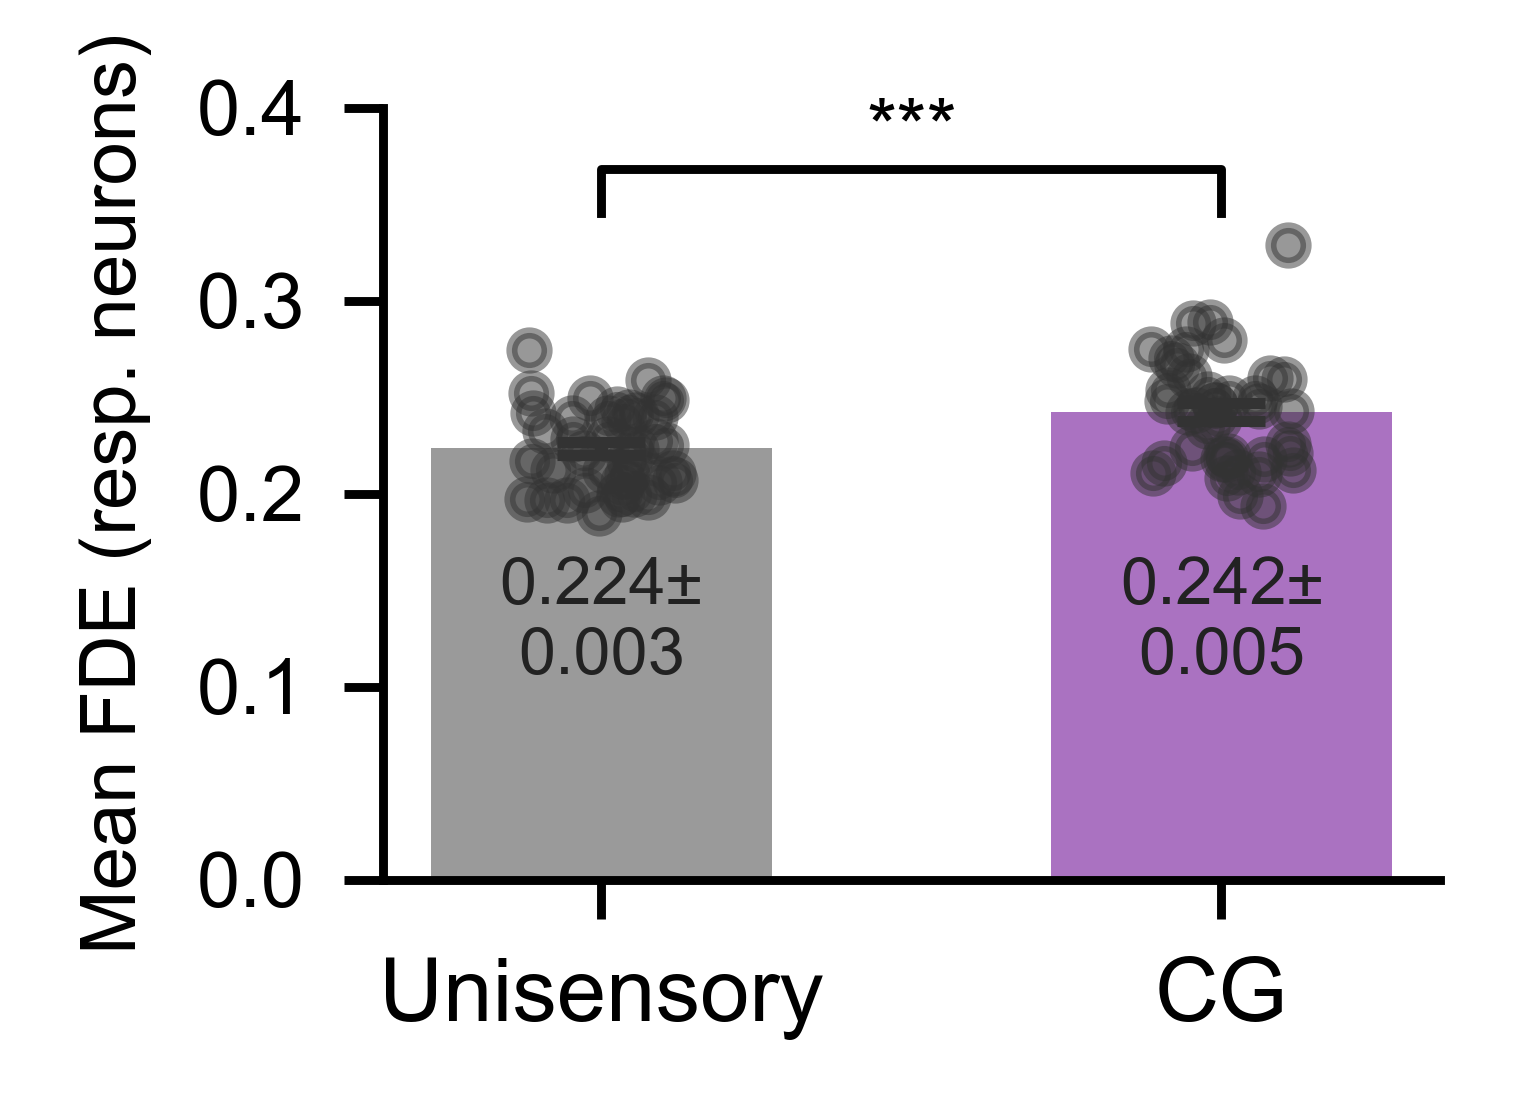

In [71]:
def plot_fde_uni_vs_cg_separate(df_uni, df_cg, resp_threshold=0.1, figsize=(2, 1.5)):
    """
    Mean test FDE from each model separately, using their own responsive populations.
    NOT matched — each bar represents neurons that passed the threshold in that model.
    """
    from scipy.stats import wilcoxon

    SESS_KEY = ['mouse_ID', 'date']

    sess_uni = (
        df_uni[df_uni['test_frac_dev'] > resp_threshold]
        .groupby(SESS_KEY)['test_frac_dev']
        .mean()
        .reset_index(name='fde_uni')
    )

    sess_cg = (
        df_cg[df_cg['test_frac_dev'] > resp_threshold]
        .groupby(SESS_KEY)['test_frac_dev']
        .mean()
        .reset_index(name='fde_cg')
    )

    sess = sess_uni.merge(sess_cg, on=SESS_KEY, how='inner')
    n = len(sess)

    _, p = wilcoxon(sess['fde_uni'], sess['fde_cg'])
    p_str = 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'
    print(f'Wilcoxon (N={n} sessions): {p_str}')
    print(f'  Unisensory: {sess["fde_uni"].mean():.3f} ± {sess["fde_uni"].sem():.3f}')
    print(f'  CG:         {sess["fde_cg"].mean():.3f} ± {sess["fde_cg"].sem():.3f}')

    cols   = ['fde_uni', 'fde_cg']
    labels = ['Unisensory', 'CG']
    colors = ['#888888', CTX_COLORS_STR['cg']]

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for i, (col, color) in enumerate(zip(cols, colors)):
        mean_val = sess[col].mean()
        sem_val  = sess[col].sem()

        ax.bar(i, mean_val, yerr=sem_val, width=0.55,
               color=color, alpha=0.85, edgecolor='none',
               error_kw=dict(elinewidth=1.2, capsize=4, ecolor='#333333'),
               zorder=2)

        rng    = np.random.default_rng(seed=i)
        jitter = rng.uniform(-0.12, 0.12, size=n)
        ax.scatter(i + jitter, sess[col].values,
                   color='#333333', s=10, alpha=0.5, zorder=3)

        ax.text(i, 0.1,
                f'{mean_val:.3f}±\n{sem_val:.3f}',
                ha='center', va='bottom', fontsize=6, color='#222222')

    y_top = sess[cols].values.max()
    bar_h = y_top * 1.12
    ax.plot([0, 0, 1, 1],
            [y_top * 1.05, bar_h, bar_h, y_top * 1.05],
            lw=0.8, color='k')
    star = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    ax.text(0.5, bar_h, star, ha='center', va='bottom', fontsize=7)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel('Mean FDE (resp. neurons)', fontsize=7)
    ax.set_ylim(0, 0.4)

    sns.despine()
    plt.tight_layout()
    return fig


fig_q1b = plot_fde_uni_vs_cg_separate(df_uni, df_cg)
plt.savefig('figures/fde_uni_vs_cg_separate.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Neuron group counts:
  Neither                     : 29,330  (48.5%)
  Both responsive             : 17,406  (28.8%)
  Uni only (dropped)          :  7,708  (12.7%)
  CG only (recruited)         :  6,051  (10.0%)


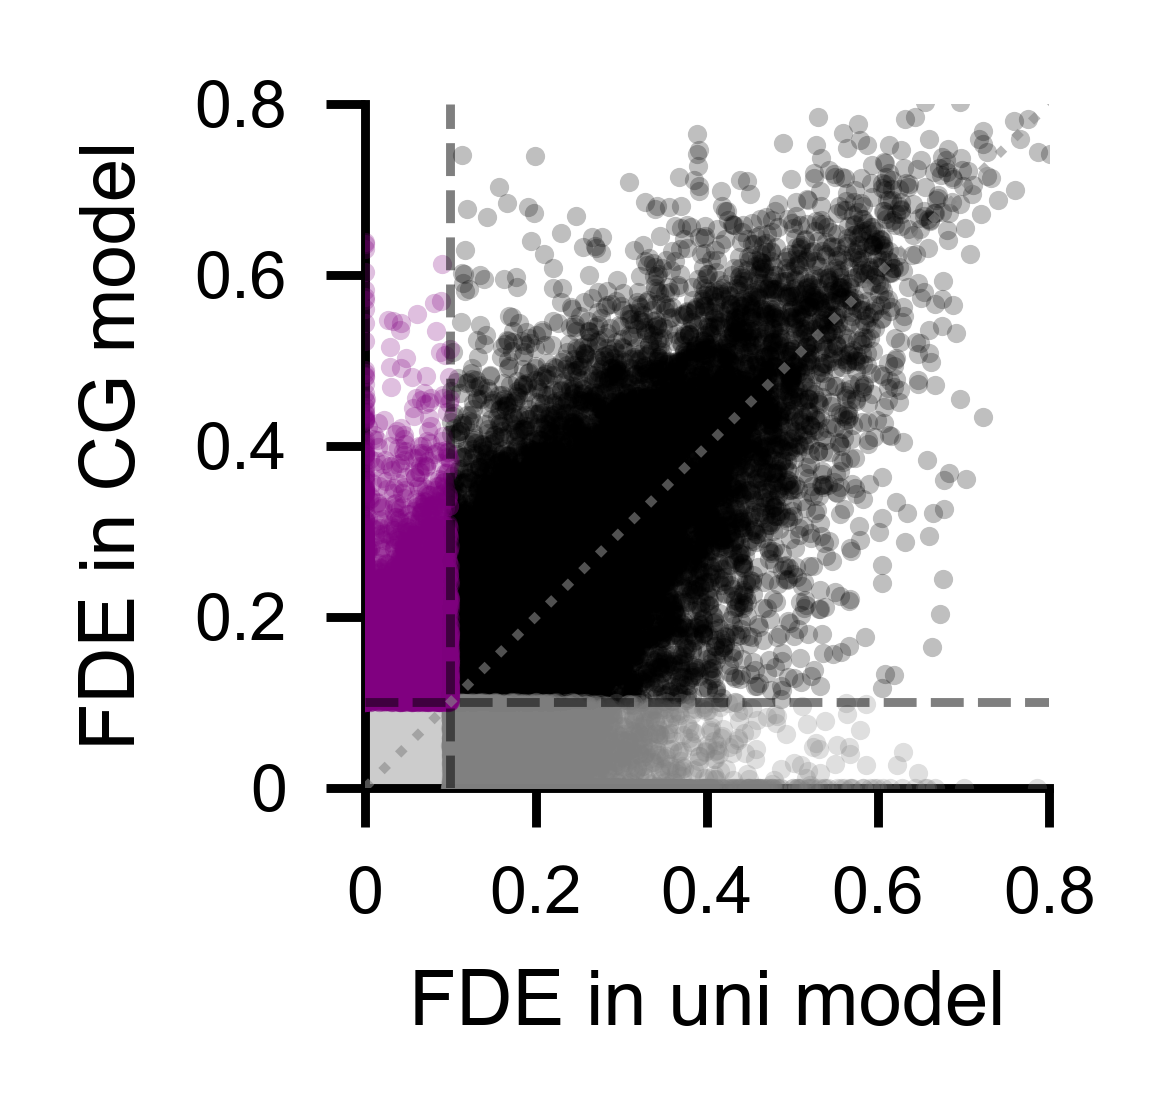

In [80]:
def plot_uni_vs_cg_fde_scatter(df_uni, df_cg, resp_threshold=0.1, figsize=(1.7, 1.5)):
    """
    Scatter: uni FDE vs CG FDE per neuron.
    Uses outer join of df_uni and df_cg — captures all neurons from either model.
    Color-coded by responsiveness group (both, uni-only, CG-only, neither).
    Scatter dots are rasterized to keep SVG/PDF file size small.
    """
    KEY = ['mouse_ID', 'date', 'neuron_idx']

    df = (
        df_uni[KEY + ['test_frac_dev']]
        .rename(columns={'test_frac_dev': 'fde_uni'})
        .merge(
            df_cg[KEY + ['test_frac_dev']]
            .rename(columns={'test_frac_dev': 'fde_cg'}),
            on=KEY, how='outer'
        )
    )
    df['fde_uni'] = df['fde_uni'].fillna(0.0)
    df['fde_cg']  = df['fde_cg'].fillna(0.0)

    uni_resp = df['fde_uni'] > resp_threshold
    cg_resp  = df['fde_cg']  > resp_threshold

    df['group'] = 'neither'
    df.loc[ uni_resp &  cg_resp, 'group'] = 'both'
    df.loc[ uni_resp & ~cg_resp, 'group'] = 'uni_only'
    df.loc[~uni_resp &  cg_resp, 'group'] = 'cg_only'

    GROUP_COLORS = {
        'both'    : 'black',
        'uni_only': 'grey',
        'cg_only' : 'purple',
        'neither' : '#CCCCCC',
    }
    GROUP_LABELS = {
        'both'    : 'Both responsive',
        'uni_only': 'Uni only (dropped)',
        'cg_only' : 'CG only (recruited)',
        'neither' : 'Neither',
    }
    GROUP_ORDER = ['neither', 'both', 'uni_only', 'cg_only']

    print('Neuron group counts:')
    for g in GROUP_ORDER:
        n = (df['group'] == g).sum()
        print(f'  {GROUP_LABELS[g]:<28s}: {n:>6,}  ({n/len(df)*100:.1f}%)')

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for g in GROUP_ORDER:
        sub   = df[df['group'] == g]
        alpha = 0.08 if g == 'neither' else 0.25
        size  = 1.5  if g == 'neither' else 3

        ax.scatter(sub['fde_uni'], sub['fde_cg'],
                   color=GROUP_COLORS[g], s=size, alpha=alpha,
                   linewidths=0, zorder=2 if g == 'neither' else 3,
                   rasterized=True,
                   label=f'{GROUP_LABELS[g]} (n={len(sub):,})')

    # Threshold lines and unity line remain as vectors (no rasterized=True)
    ax.axvline(resp_threshold, color='k', lw=0.8, ls='--', alpha=0.5, zorder=4)
    ax.axhline(resp_threshold, color='k', lw=0.8, ls='--', alpha=0.5, zorder=4)
    ax.plot([0, 0.8], [0, 0.8], color='#888888', lw=0.8, ls=':', alpha=0.6, zorder=4)

    ax.set_xlabel('FDE in uni model', fontsize=7)
    ax.set_ylabel('FDE in CG model', fontsize=7)
    ax.set_xlim(0, 0.8)
    ax.set_ylim(0, 0.8)
    ax.set_aspect('equal')

    ticks = [0, 0.2, 0.4, 0.6, 0.8]
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(ticks, fontsize=6)
    ax.set_yticklabels(ticks, fontsize=6)

    sns.despine()
    plt.tight_layout()
    return fig, df


fig_scatter, df_groups = plot_uni_vs_cg_fde_scatter(df_uni, df_cg)
plt.savefig('figures/uni_vs_cg_fde_scatter.pdf',
            bbox_inches='tight', facecolor='white', edgecolor='none',
            dpi=800)
plt.show()

Both: uni=0.248, cg=0.267, p=0.0000
Uni only: uni=0.167, cg=0.036, p=0.0000
CG only: uni=0.050, cg=0.169, p=0.0000


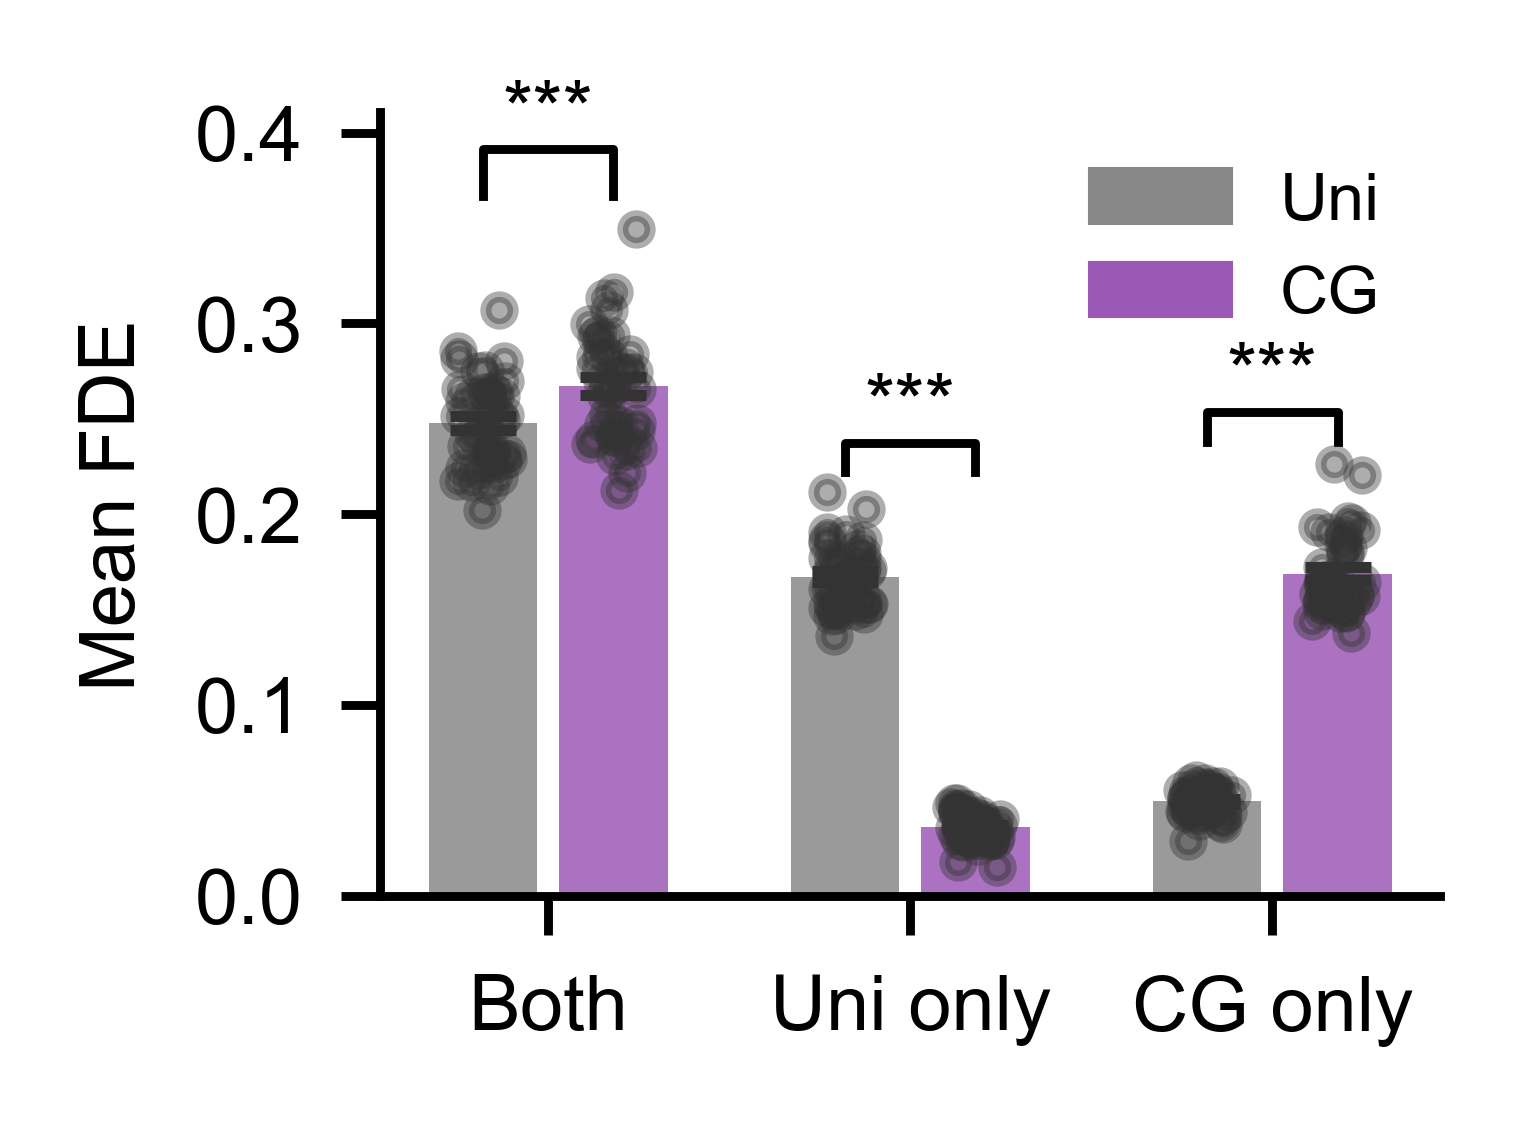

In [73]:
def plot_fde_by_group(df_groups, figsize=(2.0, 1.5)):
    """
    3 groups on x-axis (both, uni_only, cg_only).
    2 bars per group: uni model FDE vs CG model FDE.
    Paired Wilcoxon within each group (session-level means).
    """
    from matplotlib.patches import Patch
    from scipy.stats import wilcoxon

    SESS_KEY     = ['mouse_ID', 'date']
    groups       = ['both', 'uni_only', 'cg_only']
    GROUP_LABELS = {'both': 'Both', 'uni_only': 'Uni only', 'cg_only': 'CG only'}
    MODEL_COLORS = {'fde_uni': '#888888', 'fde_cg': CTX_COLORS_STR['cg']}
    MODEL_LABELS = {'fde_uni': 'Uni', 'fde_cg': 'CG'}

    sess = (
        df_groups[df_groups['group'].isin(groups)]
        .groupby(SESS_KEY + ['group'])[['fde_uni', 'fde_cg']]
        .mean()
        .reset_index()
    )

    x_centers = [0, 1, 2]
    bar_w     = 0.3
    offsets   = [-0.18, 0.18]   # uni left, CG right
    models    = ['fde_uni', 'fde_cg']

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for gi, (group, x_center) in enumerate(zip(groups, x_centers)):
        sub = sess[sess['group'] == group]

        for mi, (model_col, offset) in enumerate(zip(models, offsets)):
            x        = x_center + offset
            mean_val = sub[model_col].mean()
            sem_val  = sub[model_col].sem()

            ax.bar(x, mean_val, yerr=sem_val, width=bar_w,
                   color=MODEL_COLORS[model_col], alpha=0.85, edgecolor='none',
                   error_kw=dict(elinewidth=1.2, capsize=3, ecolor='#333333'),
                   zorder=2)

            rng    = np.random.default_rng(seed=gi * 10 + mi)
            jitter = rng.uniform(-0.07, 0.07, size=len(sub))
            ax.scatter(x + jitter, sub[model_col].values,
                       color='#333333', s=6, alpha=0.4, zorder=3)

        # Paired Wilcoxon within each group
        _, p = wilcoxon(sub['fde_uni'], sub['fde_cg'])
        star  = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
        y_top = sub[models].values.max()
        bar_h = y_top * 1.12
        ax.plot([x_center - 0.18, x_center - 0.18,
                 x_center + 0.18, x_center + 0.18],
                [y_top * 1.05, bar_h, bar_h, y_top * 1.05],
                lw=0.8, color='k')
        ax.text(x_center, bar_h, star, ha='center', va='bottom', fontsize=7)
        print(f'{GROUP_LABELS[group]}: uni={sub["fde_uni"].mean():.3f}, '
              f'cg={sub["fde_cg"].mean():.3f}, p={p:.4f}')

    ax.set_xticks(x_centers)
    ax.set_xticklabels([GROUP_LABELS[g] for g in groups], fontsize=7)
    ax.set_ylabel('Mean FDE', fontsize=7)
    ax.set_ylim(bottom=0)

    handles = [Patch(color=MODEL_COLORS[m], label=MODEL_LABELS[m]) for m in models]
    ax.legend(handles=handles, fontsize=6, frameon=False, loc='upper right')

    sns.despine()
    plt.tight_layout()
    return fig


fig_group_fde = plot_fde_by_group(df_groups)
plt.savefig('figures/fde_by_group.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Resp. in both       : n=17,406  r=0.324  p<0.001  slope=0.1156  CI mean=0.0104  CD mean=0.1211
  Mann-Whitney CI vs CD: p<0.001
Uni only            : n=7,708  r=0.166  p<0.001  slope=0.0346  CI mean=-0.1276  CD mean=-0.0939
  Mann-Whitney CI vs CD: p<0.001


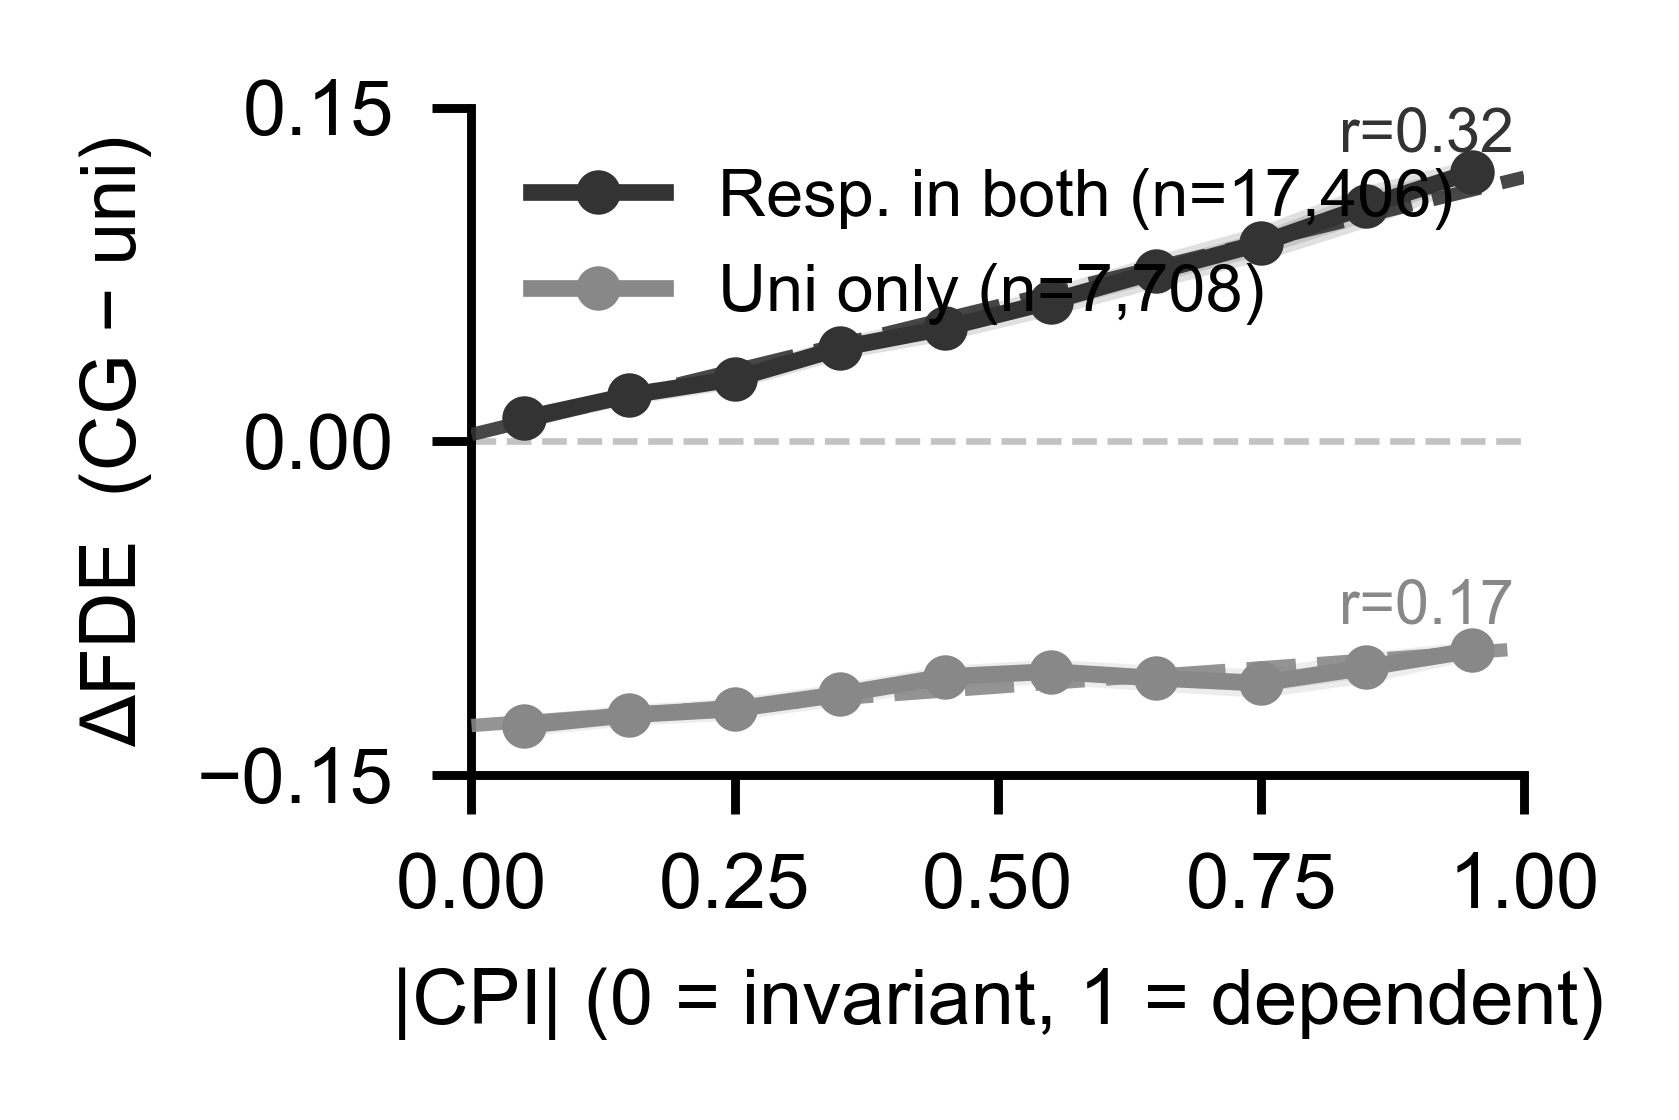

In [74]:
def plot_abscpi_vs_delta_fde_two_groups(df_uni, df_cg, resp_threshold=0.1,
                                         ci_threshold=0.1, cd_threshold=0.9,
                                         n_bins=10, figsize=(2.2, 1.5)):
    """
    |CPI| vs delta FDE (CG - uni mean), overlaid for:
      - Both (black):     responsive in uni AND CG
      - Uni only (grey):  responsive in uni only
    Equal-width bins from 0 to 1, with linear regression fit per group.
    """
    from scipy.stats import pearsonr, mannwhitneyu, linregress

    KEY = ['mouse_ID', 'date', 'neuron_idx']

    merged = (
        df_uni[KEY + ['frac_dev_visual', 'frac_dev_audio',
                      'test_frac_dev', 'vis_aud_ci']]
        .rename(columns={'test_frac_dev': 'fde_uni'})
        .merge(
            df_cg[KEY + ['frac_dev_cg', 'test_frac_dev']]
            .rename(columns={'test_frac_dev': 'fde_cg'}),
            on=KEY, how='left'
        )
    )
    merged['fde_cg']      = merged['fde_cg'].fillna(0.0)
    merged['frac_dev_cg'] = merged['frac_dev_cg'].fillna(0.0)

    merged = merged[merged['fde_uni'] > resp_threshold].copy()
    merged['group']             = np.where(
        merged['fde_cg'] > resp_threshold, 'both', 'uni_only'
    )
    merged['frac_dev_uni_mean'] = (merged['frac_dev_visual'] + merged['frac_dev_audio']) / 2
    merged['delta_fde']         = merged['frac_dev_cg'] - merged['frac_dev_uni_mean']
    merged['abs_cpi']           = merged['vis_aud_ci'].abs()

    GROUP_STYLES = {
        'both'    : {'color': '#333333', 'label': 'Resp. in both'},
        'uni_only': {'color': '#888888', 'label': 'Uni only'},
    }

    # Print stats
    for group, style in GROUP_STYLES.items():
        sub   = merged[merged['group'] == group]
        ci_m  = sub.loc[sub['abs_cpi'] <  ci_threshold, 'delta_fde']
        cd_m  = sub.loc[sub['abs_cpi'] >  cd_threshold, 'delta_fde']
        r, p_r = pearsonr(sub['abs_cpi'].values, sub['delta_fde'].values)
        slope, intercept, _, p_lr, _ = linregress(sub['abs_cpi'].values,
                                                   sub['delta_fde'].values)
        p_str = 'p<0.001' if p_r < 0.001 else f'p={p_r:.3f}'
        print(f'{style["label"]:20s}: n={len(sub):,}  r={r:.3f}  {p_str}  '
              f'slope={slope:.4f}  CI mean={ci_m.mean():.4f}  CD mean={cd_m.mean():.4f}')
        if len(ci_m) > 0 and len(cd_m) > 0:
            _, p_mw = mannwhitneyu(ci_m, cd_m, alternative='two-sided')
            print(f'  Mann-Whitney CI vs CD: {"p<0.001" if p_mw<0.001 else f"p={p_mw:.3f}"}')

    bin_edges   = np.linspace(0, 1, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for group, style in GROUP_STYLES.items():
        sub = merged[merged['group'] == group].copy()

        # Binned means
        sub['bin'] = pd.cut(sub['abs_cpi'], bins=bin_edges, include_lowest=True)
        binned = sub.groupby('bin', observed=True).agg(
            delta_mean=('delta_fde', 'mean'),
            delta_sem =('delta_fde', 'sem'),
        )

        fde_mean = np.full(len(bin_centers), np.nan)
        fde_sem  = np.full(len(bin_centers), np.nan)
        for i, b in enumerate(pd.cut(pd.Series(bin_centers),
                                     bins=bin_edges, include_lowest=True)):
            if b in binned.index:
                fde_mean[i] = binned.loc[b, 'delta_mean']
                fde_sem[i]  = binned.loc[b, 'delta_sem']

        ax.fill_between(bin_centers,
                        fde_mean - fde_sem,
                        fde_mean + fde_sem,
                        alpha=0.15, color=style['color'], zorder=2)
        ax.plot(bin_centers, fde_mean,
                color=style['color'], lw=1.5, marker='o', ms=3,
                zorder=3, label=f'{style["label"]} (n={len(sub):,})')

        # Linear regression fit on raw neuron data
        slope, intercept, r, p, _ = linregress(sub['abs_cpi'].values,
                                                sub['delta_fde'].values)
        x_fit = np.array([0, 1])
        y_fit = slope * x_fit + intercept
        p_str = 'p<0.001' if p < 0.001 else f'p={p:.3f}'

        ax.plot(x_fit, y_fit,
                color=style['color'], lw=1.2, ls='--',
                zorder=4, alpha=0.9)
        # r label placed at right end of fit line
        ax.text(0.99, y_fit[1] + 0.006,
                f'r={r:.2f}', ha='right', va='bottom',
                fontsize=5.5, color=style['color'])

    ax.axhline(0, color='#AAAAAA', lw=0.6, ls='--', zorder=1, alpha=0.7)

    ax.set_xlabel('|CPI| (0 = invariant, 1 = dependent)', fontsize=7)
    ax.set_ylabel('ΔFDE  (CG − uni)', fontsize=7)
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_yticks([-0.15, 0, 0.15])
    ax.legend(fontsize=6, frameon=False, loc='upper left')

    sns.despine()
    plt.tight_layout()
    return fig


fig_abs = plot_abscpi_vs_delta_fde_two_groups(df_uni, df_cg)
plt.savefig('figures/abscpi_vs_delta_fde_two_groups.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Resp. in both:
  CI: mean=0.0101 ± 0.0036  n_sess=39
  CD: mean=0.1122 ± 0.0050  n_sess=39
  Wilcoxon CI vs CD: ***
Uni only:
  CI: mean=-0.1210 ± 0.0042  n_sess=39
  CD: mean=-0.0865 ± 0.0037  n_sess=39
  Wilcoxon CI vs CD: ***


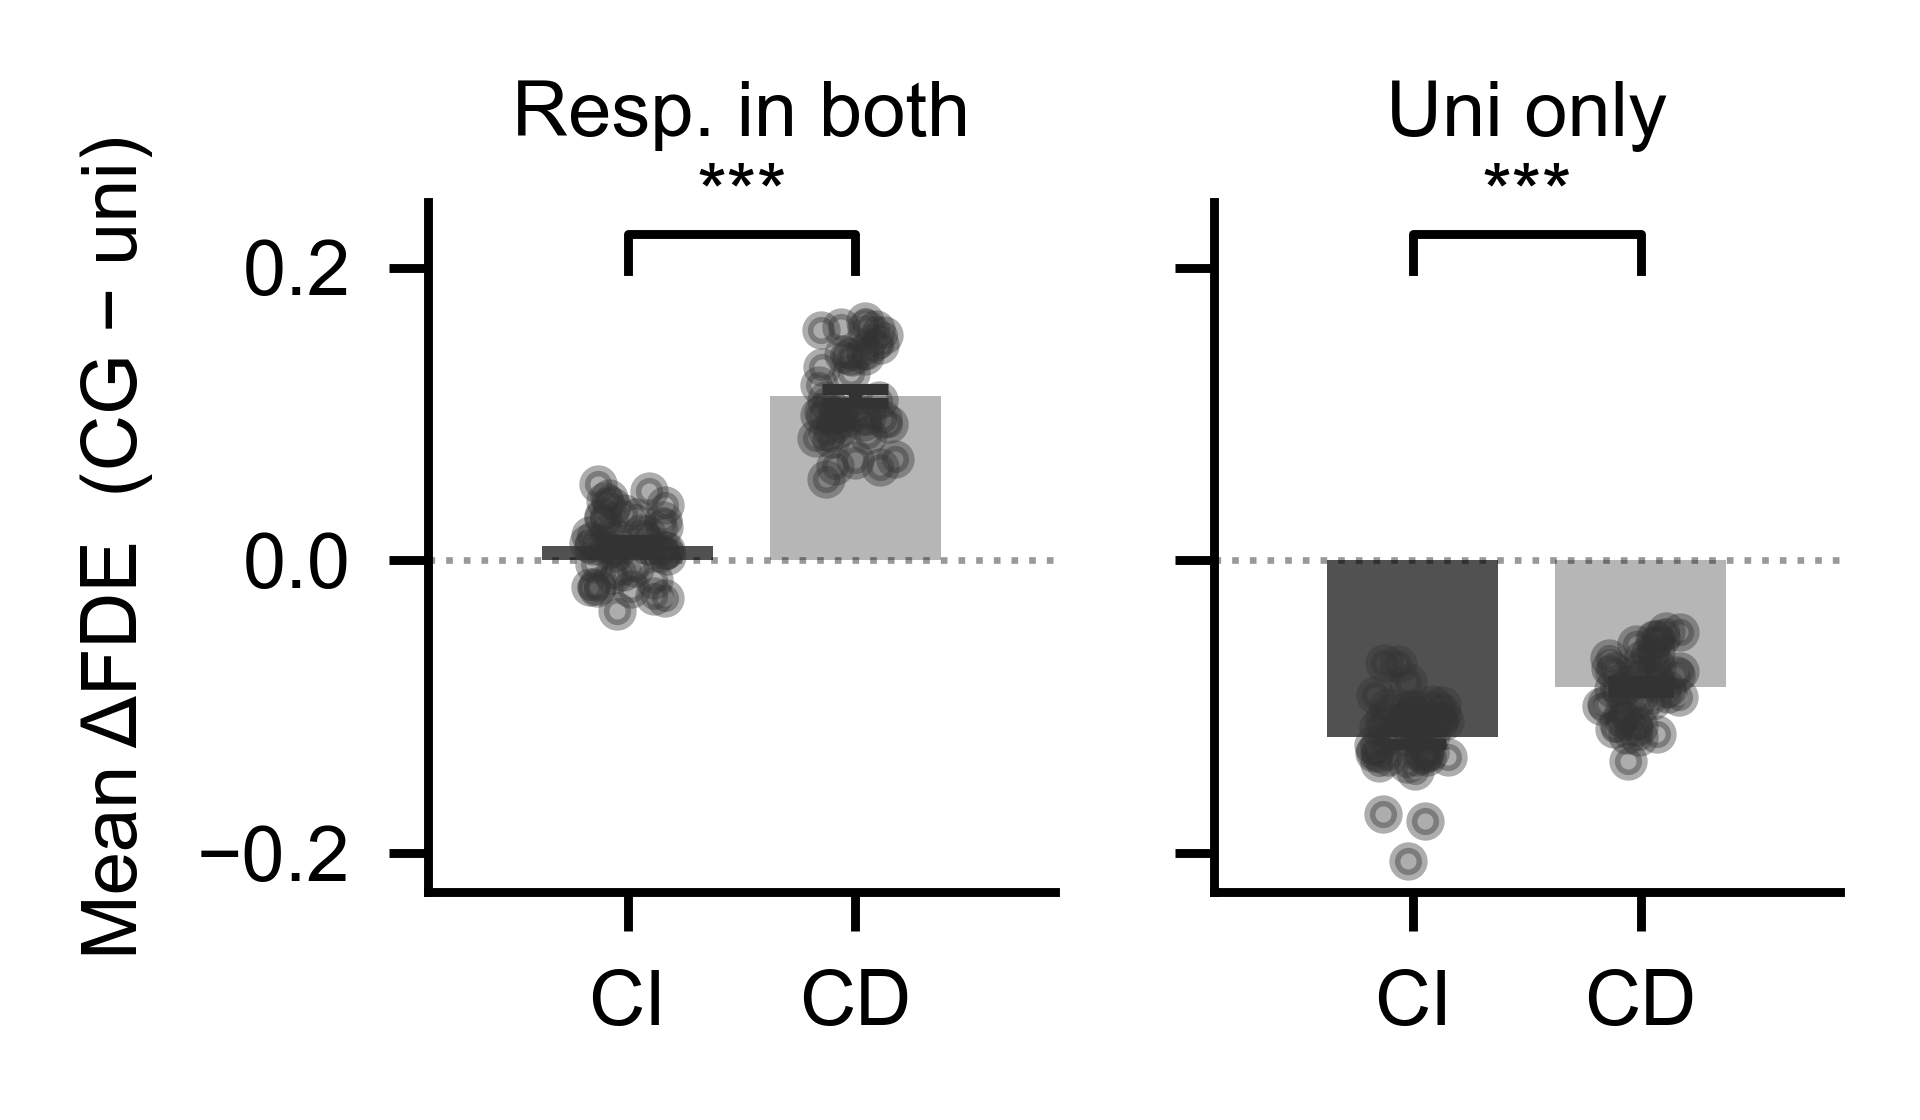

In [75]:
def plot_delta_fde_ci_cd_barplot(df_uni, df_cg, resp_threshold=0.1,
                                  ci_threshold=0.1, cd_threshold=0.9,
                                  figsize=(2.5, 1.5)):
    """
    Bar plot of mean delta FDE (CG - uni) for CI vs CD neurons,
    split into two panels: Both responsive and Uni only.
    Session-level means with paired Wilcoxon CI vs CD per panel.
    """
    from scipy.stats import wilcoxon
    from matplotlib.patches import Patch

    KEY      = ['mouse_ID', 'date', 'neuron_idx']
    SESS_KEY = ['mouse_ID', 'date']

    merged = (
        df_uni[KEY + ['frac_dev_visual', 'frac_dev_audio',
                      'test_frac_dev', 'vis_aud_ci']]
        .rename(columns={'test_frac_dev': 'fde_uni'})
        .merge(
            df_cg[KEY + ['frac_dev_cg', 'test_frac_dev']]
            .rename(columns={'test_frac_dev': 'fde_cg'}),
            on=KEY, how='left'
        )
    )
    merged['fde_cg']      = merged['fde_cg'].fillna(0.0)
    merged['frac_dev_cg'] = merged['frac_dev_cg'].fillna(0.0)
    merged = merged[merged['fde_uni'] > resp_threshold].copy()

    merged['resp_group']        = np.where(merged['fde_cg'] > resp_threshold, 'both', 'uni_only')
    merged['frac_dev_uni_mean'] = (merged['frac_dev_visual'] + merged['frac_dev_audio']) / 2
    merged['delta_fde']         = merged['frac_dev_cg'] - merged['frac_dev_uni_mean']
    merged['abs_cpi']           = merged['vis_aud_ci'].abs()
    merged['cpi_group']         = 'intermediate'
    merged.loc[merged['abs_cpi'] <  ci_threshold, 'cpi_group'] = 'CI'
    merged.loc[merged['abs_cpi'] >  cd_threshold, 'cpi_group'] = 'CD'

    # Keep only CI and CD neurons
    df_plot = merged[merged['cpi_group'].isin(['CI', 'CD'])].copy()

    # Session-level means per resp_group × cpi_group
    sess = (
        df_plot.groupby(SESS_KEY + ['resp_group', 'cpi_group'])['delta_fde']
        .mean()
        .reset_index(name='mean_delta')
    )

    RESP_GROUPS  = ['both', 'uni_only']
    RESP_LABELS  = {'both': 'Resp. in both', 'uni_only': 'Uni only'}
    CPI_GROUPS   = ['CI', 'CD']
    CD_COLOR     = '#AAAAAA'
    CI_COLOR     = '#333333'
    CPI_COLORS   = {'CI': CI_COLOR, 'CD': CD_COLOR}
    offsets      = {'CI': -0.2, 'CD': 0.2}
    bar_w        = 0.3

    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True, dpi=800)

    for ax, resp_grp in zip(axes, RESP_GROUPS):
        sub_resp = sess[sess['resp_group'] == resp_grp]

        for cpi_grp in CPI_GROUPS:
            sub  = sub_resp[sub_resp['cpi_group'] == cpi_grp]
            x    = offsets[cpi_grp]
            mean_val = sub['mean_delta'].mean()
            sem_val  = sub['mean_delta'].sem()
            n        = len(sub)

            ax.bar(x, mean_val, yerr=sem_val, width=bar_w,
                   color=CPI_COLORS[cpi_grp], alpha=0.85, edgecolor='none',
                   error_kw=dict(elinewidth=1.2, capsize=3, ecolor='#333333'),
                   zorder=2)

            rng    = np.random.default_rng(seed=hash(resp_grp + cpi_grp) % 999)
            jitter = rng.uniform(-0.07, 0.07, size=n)
            ax.scatter(x + jitter, sub['mean_delta'].values,
                       color='#333333', s=6, alpha=0.4, zorder=3)

        # Paired Wilcoxon CI vs CD (matched on session)
        wide = sub_resp.pivot(index=SESS_KEY, columns='cpi_group', values='mean_delta').dropna()
        if len(wide) >= 5:
            _, p = wilcoxon(wide['CI'], wide['CD'])
            star = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
        else:
            star = 'n/a'

        y_vals = sub_resp['mean_delta'].values
        y_top  = 0.18 #y_vals.max() if len(y_vals) else 0.1
        y_bot  = -0.18 #y_vals.min() if len(y_vals) else -0.1
        bar_h  = y_top + abs(y_top - y_bot) * 0.12
        ax.plot([-0.2, -0.2, 0.2, 0.2],
                [y_top + abs(y_top-y_bot)*0.05, bar_h, bar_h,
                 y_top + abs(y_top-y_bot)*0.05],
                lw=0.8, color='k')
        ax.text(0, bar_h, star, ha='center', va='bottom', fontsize=7)

        ax.axhline(0, color='k', lw=0.6, ls=':', alpha=0.4)
        ax.set_xticks([-0.2, 0.2])
        ax.set_xticklabels(CPI_GROUPS, fontsize=7)
        ax.set_xlim(-0.55, 0.55)
        ax.set_title(RESP_LABELS[resp_grp], fontsize=7)

        print(f'{RESP_LABELS[resp_grp]}:')
        for cpi_grp in CPI_GROUPS:
            sub = sub_resp[sub_resp['cpi_group'] == cpi_grp]
            print(f'  {cpi_grp}: mean={sub["mean_delta"].mean():.4f} ± {sub["mean_delta"].sem():.4f}  n_sess={len(sub)}')
        print(f'  Wilcoxon CI vs CD: {star}')

    axes[0].set_ylabel('Mean ΔFDE  (CG − uni)', fontsize=7)

    sns.despine()
    plt.tight_layout()
    return fig


fig_bar = plot_delta_fde_ci_cd_barplot(df_uni, df_cg)
plt.savefig('figures/delta_fde_ci_cd_barplot.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Kinematics  : n=4,899  r=0.233  slope=0.0842  p<0.001
Audio       : n=294  r=0.162  slope=0.0594  p=0.005
Visual      : n=1,198  r=0.438  slope=0.1740  p<0.001
Choice      : n=5,681  r=0.269  slope=0.1030  p<0.001
Outcome     : n=3,899  r=0.292  slope=0.1014  p<0.001
mixed       : n=1,435  r=0.301  slope=0.1064  p<0.001


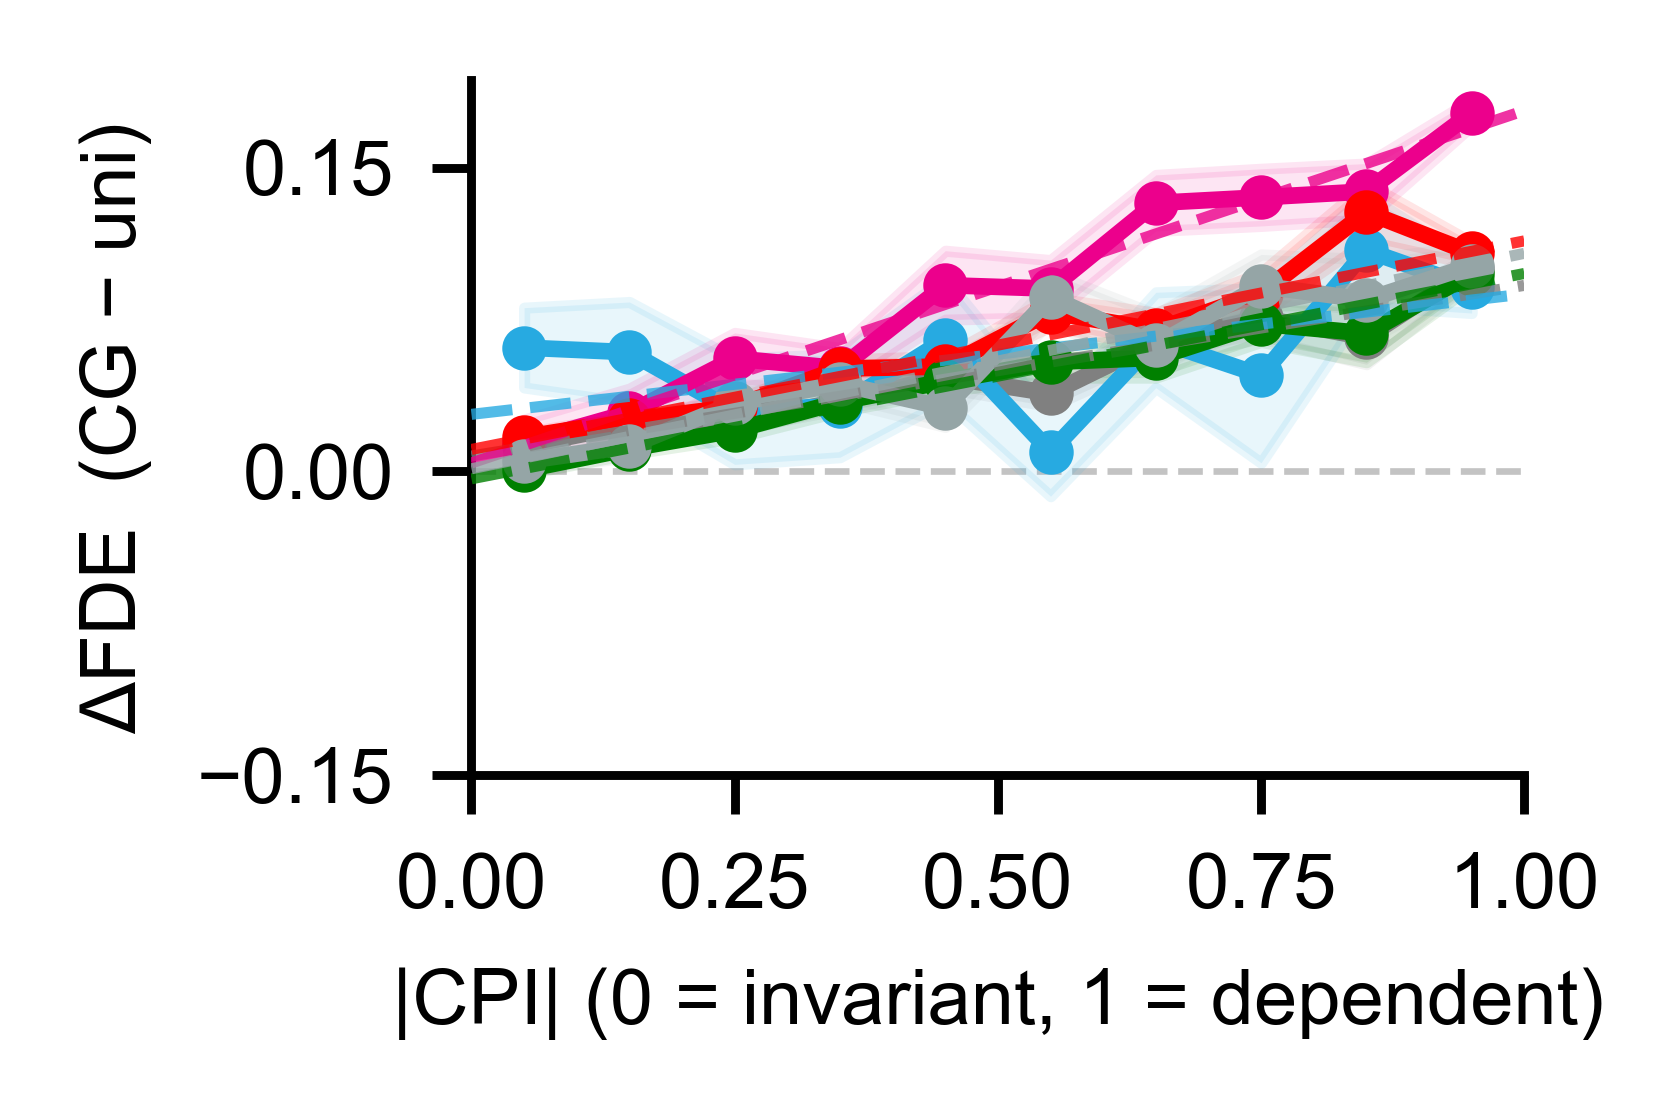

In [76]:
def plot_abscpi_vs_delta_fde_by_class(df_uni, df_cg, resp_threshold=0.1,
                                       n_bins=10, figsize=(2.2, 1.5)):
    """
    |CPI| vs delta FDE (CG - uni mean) for neurons responsive in BOTH models.
    All lesion subgroups overlaid as separate colored lines with linear fits.
    """
    from scipy.stats import pearsonr, linregress

    KEY = ['mouse_ID', 'date', 'neuron_idx']

    merged = (
        df_uni[KEY + ['frac_dev_visual', 'frac_dev_audio',
                      'test_frac_dev', 'vis_aud_ci', 'merged_class']]
        .rename(columns={'test_frac_dev': 'fde_uni'})
        .merge(
            df_cg[KEY + ['frac_dev_cg', 'test_frac_dev']]
            .rename(columns={'test_frac_dev': 'fde_cg'}),
            on=KEY, how='left'
        )
    )
    merged['fde_cg']      = merged['fde_cg'].fillna(0.0)
    merged['frac_dev_cg'] = merged['frac_dev_cg'].fillna(0.0)

    both = merged[
        (merged['fde_uni'] > resp_threshold) &
        (merged['fde_cg']  > resp_threshold)
    ].copy()
    both['frac_dev_uni_mean'] = (both['frac_dev_visual'] + both['frac_dev_audio']) / 2
    both['delta_fde']         = both['frac_dev_cg'] - both['frac_dev_uni_mean']
    both['abs_cpi']           = both['vis_aud_ci'].abs()
    both['merged_class']      = both['merged_class'].fillna('mixed').replace('unclassified', 'mixed')

    CLASS_ORDER = MERGE_ORDER + ['mixed']
    cls_colors  = {**MERGE_COLORS, 'mixed': '#95A5A6'}

    bin_edges   = np.linspace(0, 1, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for cls in CLASS_ORDER:
        sub   = both[both['merged_class'] == cls].copy()
        n     = len(sub)
        color = cls_colors.get(cls, '#999999')

        if n < 20:
            continue

        # Binned means
        sub['bin'] = pd.cut(sub['abs_cpi'], bins=bin_edges, include_lowest=True)
        binned = sub.groupby('bin', observed=True).agg(
            delta_mean=('delta_fde', 'mean'),
            delta_sem =('delta_fde', 'sem'),
            n_bin     =('delta_fde', 'count'),
        )

        fde_mean = np.full(len(bin_centers), np.nan)
        fde_sem  = np.full(len(bin_centers), np.nan)
        for i, b in enumerate(pd.cut(pd.Series(bin_centers),
                                     bins=bin_edges, include_lowest=True)):
            if b in binned.index and binned.loc[b, 'n_bin'] >= 5:
                fde_mean[i] = binned.loc[b, 'delta_mean']
                fde_sem[i]  = binned.loc[b, 'delta_sem']

        ax.fill_between(bin_centers,
                        fde_mean - fde_sem,
                        fde_mean + fde_sem,
                        alpha=0.1, color=color, zorder=2)
        ax.plot(bin_centers, fde_mean,
                color=color, lw=1.5, marker='o', ms=3,
                zorder=3, label=f'{cls} (n={n:,})')

        # Linear regression fit
        slope, intercept, r, p, _ = linregress(sub['abs_cpi'].values,
                                                sub['delta_fde'].values)
        x_fit = np.array([0, 1])
        y_fit = slope * x_fit + intercept
        ax.plot(x_fit, y_fit, color=color, lw=1.0, ls='--',
                zorder=4, alpha=0.8)

        p_str = 'p<0.001' if p < 0.001 else f'p={p:.3f}'
        print(f'{cls:12s}: n={n:,}  r={r:.3f}  slope={slope:.4f}  {p_str}')

    ax.axhline(0, color='#AAAAAA', lw=0.6, ls='--', alpha=0.7, zorder=1)

    ax.set_xlabel('|CPI| (0 = invariant, 1 = dependent)', fontsize=7)
    ax.set_ylabel('ΔFDE  (CG − uni)', fontsize=7)
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_yticks([-0.15, 0, 0.15])
    # ax.legend(fontsize=5, frameon=False, loc='lower left',
    #           ncol=2, handlelength=1.2)

    sns.despine()
    plt.tight_layout()
    return fig


fig_cls = plot_abscpi_vs_delta_fde_by_class(df_uni, df_cg)
plt.savefig('figures/abscpi_vs_delta_fde_by_class.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

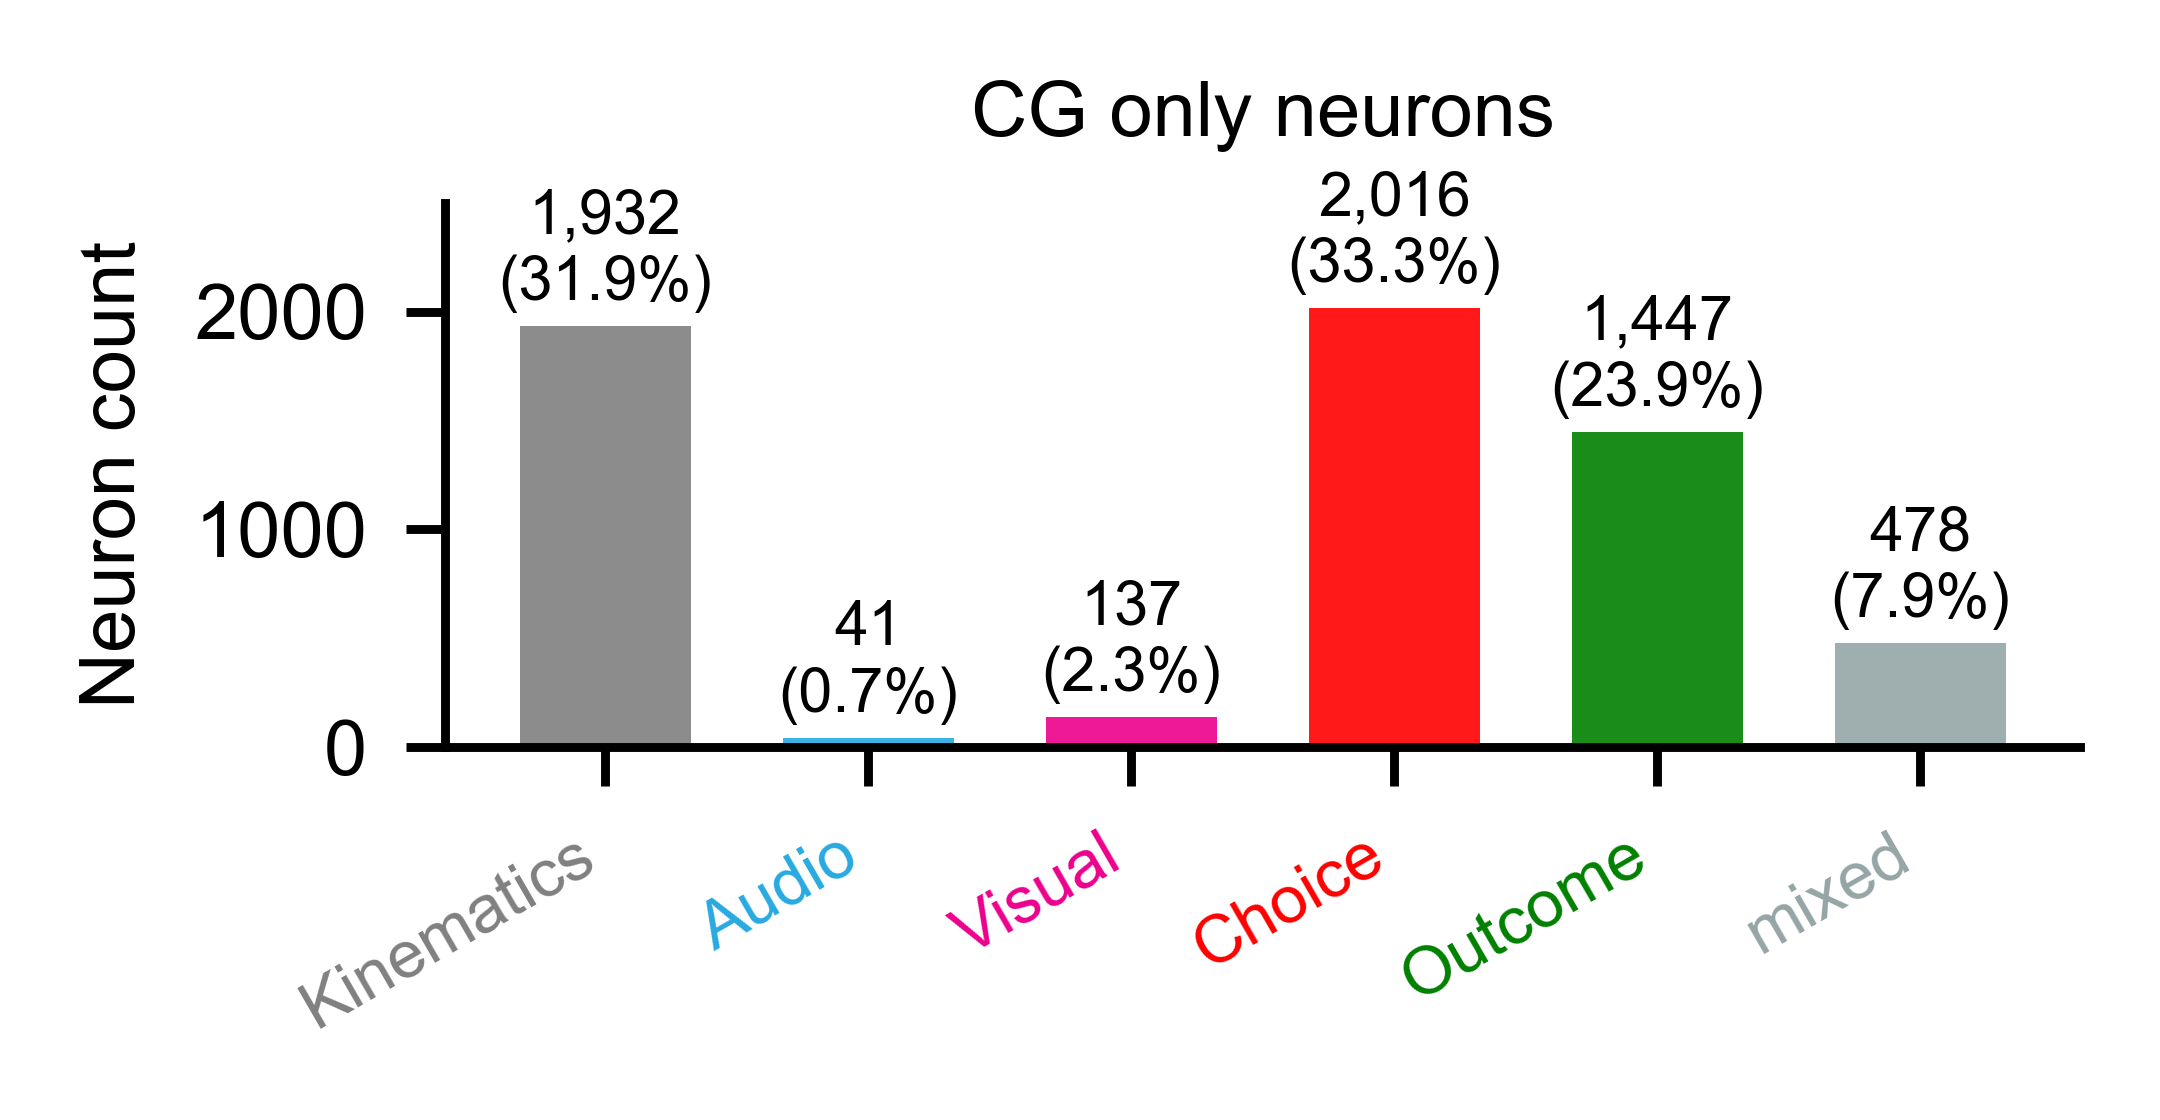

In [78]:
def plot_class_distribution_cg_only(df_groups, df_cg, figsize=(2.8, 1.5)):
    """
    Class composition of 'cg_only' neurons, classified by df_cg neuron_class.
    """
    KEY = ['mouse_ID', 'date', 'neuron_idx']

    cls_colors  = {**MERGE_COLORS, 'mixed': '#95A5A6', 'unclassified': '#95A5A6'}
    CLASS_ORDER = MERGE_ORDER + ['mixed']

    cg_only = df_groups[df_groups['group'] == 'cg_only'].merge(
        df_cg[KEY + ['neuron_class']], on=KEY, how='left'
    )
    cg_only['neuron_class'] = (
        cg_only['neuron_class']
        .fillna('mixed')
        .replace('unclassified', 'mixed')
    )

    counts = cg_only['neuron_class'].value_counts()
    total  = counts.sum()

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for i, cls in enumerate(CLASS_ORDER):
        n   = counts.get(cls, 0)
        pct = n / total * 100
        ax.bar(i, n, color=cls_colors.get(cls, '#999999'), width=0.65,
               edgecolor='none', alpha=0.9, zorder=2)
        ax.text(i, n + total * 0.01,
                f'{n:,}\n({pct:.1f}%)',
                ha='center', va='bottom', fontsize=5.5)

    ax.set_xticks(range(len(CLASS_ORDER)))
    ax.set_xticklabels(CLASS_ORDER, fontsize=6, rotation=30, ha='right')
    for tick, cls in zip(ax.get_xticklabels(), CLASS_ORDER):
        tick.set_color(cls_colors.get(cls, '#999999'))

    ax.set_ylabel('Neuron count', fontsize=7)
    ax.set_title(f'CG only neurons', fontsize=7)
    ax.set_ylim(0, 2500)
    sns.despine()
    plt.tight_layout()
    return fig


fig_cg_cls = plot_class_distribution_cg_only(df_groups, df_cg)
plt.savefig('figures/class_distribution_cg_only.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_12215/2599638401.py:42: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


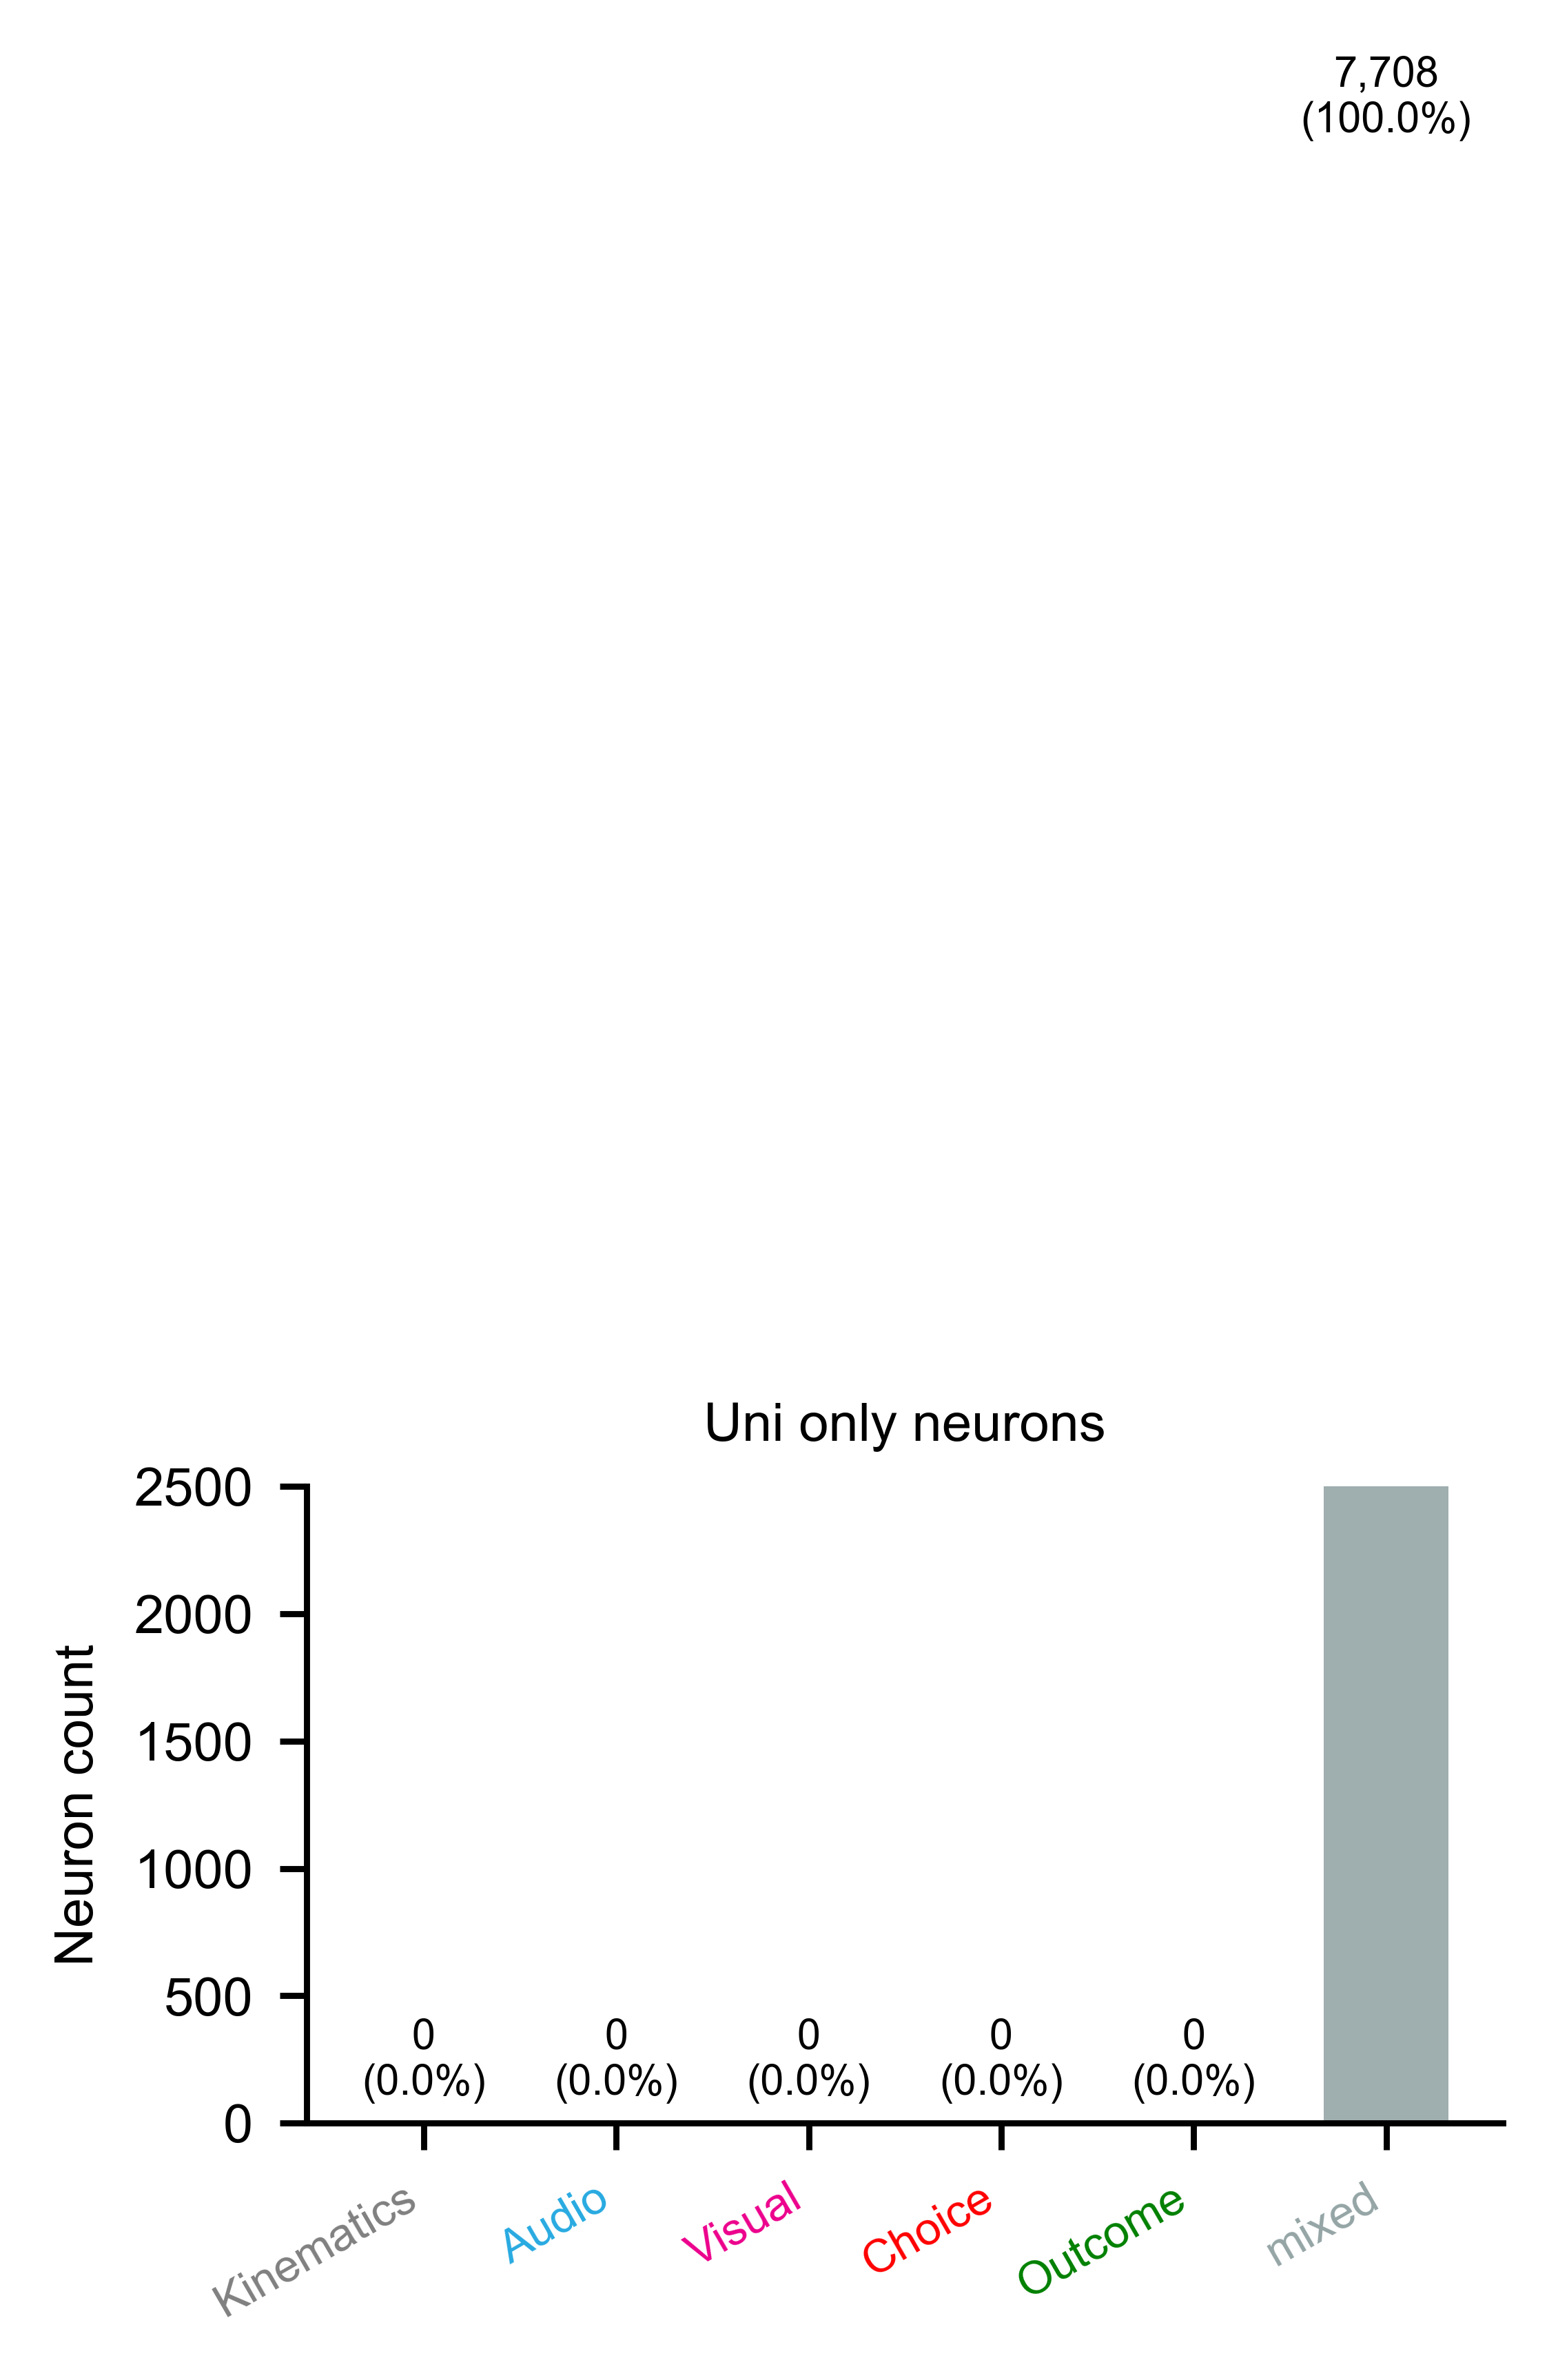

In [79]:
def plot_class_distribution_cg_only(df_groups, df_cg, figsize=(2.8, 1.5)):
    """
    Class composition of 'cg_only' neurons, classified by df_cg neuron_class.
    """
    KEY = ['mouse_ID', 'date', 'neuron_idx']

    cls_colors  = {**MERGE_COLORS, 'mixed': '#95A5A6', 'unclassified': '#95A5A6'}
    CLASS_ORDER = MERGE_ORDER + ['mixed']

    cg_only = df_groups[df_groups['group'] == 'uni_only'].merge(
        df_cg[KEY + ['neuron_class']], on=KEY, how='left'
    )
    cg_only['neuron_class'] = (
        cg_only['neuron_class']
        .fillna('mixed')
        .replace('unclassified', 'mixed')
    )

    counts = cg_only['neuron_class'].value_counts()
    total  = counts.sum()

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    for i, cls in enumerate(CLASS_ORDER):
        n   = counts.get(cls, 0)
        pct = n / total * 100
        ax.bar(i, n, color=cls_colors.get(cls, '#999999'), width=0.65,
               edgecolor='none', alpha=0.9, zorder=2)
        ax.text(i, n + total * 0.01,
                f'{n:,}\n({pct:.1f}%)',
                ha='center', va='bottom', fontsize=5.5)

    ax.set_xticks(range(len(CLASS_ORDER)))
    ax.set_xticklabels(CLASS_ORDER, fontsize=6, rotation=30, ha='right')
    for tick, cls in zip(ax.get_xticklabels(), CLASS_ORDER):
        tick.set_color(cls_colors.get(cls, '#999999'))

    ax.set_ylabel('Neuron count', fontsize=7)
    ax.set_title(f'Uni only neurons', fontsize=7)
    ax.set_ylim(0, 2500)
    sns.despine()
    plt.tight_layout()
    return fig


fig_cg_cls = plot_class_distribution_cg_only(df_groups, df_cg)
plt.savefig('figures/class_distribution_uni_only.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

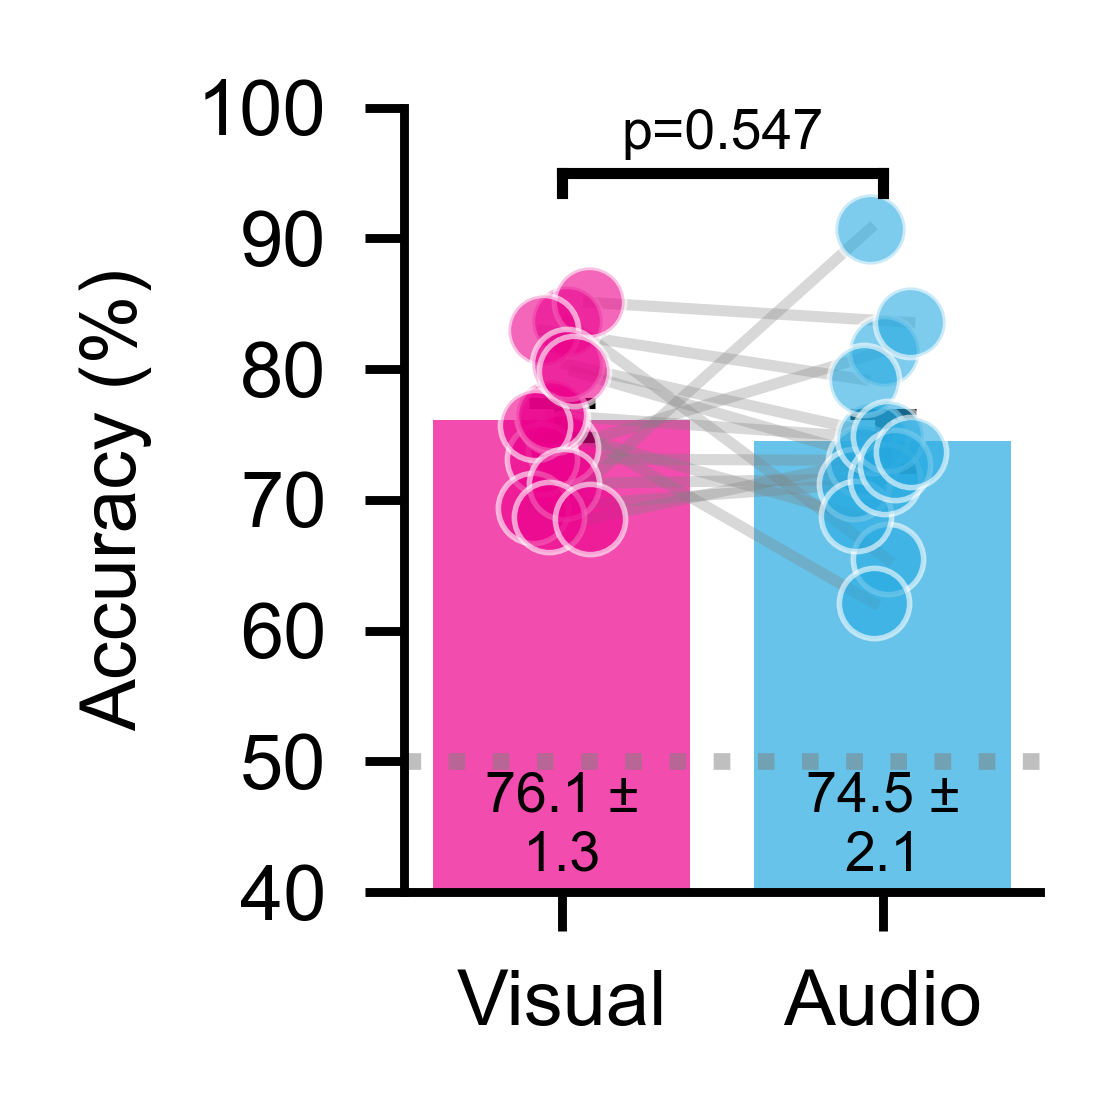

In [89]:
def plot_accuracy_from_stats(stats, contexts,
                              context_colors=None, figsize=(1.5, 1.5),
                              fontsize=7, jitter_seed=1000):
    """
    Plot accuracy bars from summary statistics, simulating individual data points.

    Parameters
    ----------
    stats : dict
        Maps context name → (n, mean, sem)
        e.g. {'Visual': (10, 85.2, 1.3), 'Audio': (10, 78.5, 2.1)}
    contexts : list
        Order of contexts on x-axis
    context_colors : dict, optional
        Maps context name → color string
    """
    from scipy.stats import ttest_rel

    if context_colors is None:
        context_colors = {
            'Visual'    : '#EC008C',
            'Audio'     : '#27AAE1',
            'Congruent' : 'purple',
        }

    # Simulate data points matching mean and SEM exactly
    def simulate_points(n, mean, sem, seed):
        std = sem * np.sqrt(n)
        rng = np.random.default_rng(seed)
        pts = rng.normal(mean, std, n)
        # Shift so simulated mean matches exactly
        pts = pts - pts.mean() + mean
        return pts

    data_dict = {}
    for i, ctx in enumerate(contexts):
        n, mean, sem = stats[ctx]
        data_dict[ctx] = simulate_points(n, mean, sem, seed=jitter_seed + i)

    fig, ax = plt.subplots(1, 1, figsize=figsize, dpi=800)

    x_positions  = np.arange(len(contexts))
    jitter_amount = 0.1

    # Bars
    for i, ctx in enumerate(contexts):
        n, mean, sem = stats[ctx]
        ax.bar(i, mean, color=context_colors.get(ctx, 'grey'), alpha=0.7)
        ax.errorbar(i, mean, yerr=sem,
                    fmt='none', color='black', capsize=3)
        ax.text(i, 45, f'{mean:.1f} ±\n{sem:.1f}',
                ha='center', va='center', fontsize=5, color='black')

    # Simulated dots + connecting lines
    n_common = min(len(data_dict[ctx]) for ctx in contexts)
    for animal_idx in range(n_common):
        rng    = np.random.default_rng(jitter_seed + animal_idx * 100)
        jitter = rng.uniform(-jitter_amount, jitter_amount)

        xs = [x_positions[ci] + jitter for ci in range(len(contexts))]
        ys = [data_dict[ctx][animal_idx] for ctx in contexts]

        ax.plot(xs, ys, color='gray', alpha=0.3, lw=1, zorder=1)
        for x, y, ctx in zip(xs, ys, contexts):
            ax.scatter(x, y, color=context_colors.get(ctx, 'grey'),
                       s=40, alpha=0.6, edgecolor='white', lw=0.5, zorder=2)

    # Paired t-tests on simulated points
    if len(contexts) == 3:
        comparisons = [(0, 1), (0, 2), (1, 2)]
    elif len(contexts) == 2:
        comparisons = [(0, 1)]
    else:
        comparisons = []

    line_start  = 95
    line_height = 6

    for i, (pos1, pos2) in enumerate(comparisons):
        ctx1, ctx2 = contexts[pos1], contexts[pos2]
        n = min(len(data_dict[ctx1]), len(data_dict[ctx2]))
        _, p = ttest_rel(data_dict[ctx1][:n], data_dict[ctx2][:n])

        y_pos  = line_start + i * line_height
        p_text = 'p<0.001' if p < 0.001 else f'p={p:.3f}'

        ax.plot([x_positions[pos1], x_positions[pos2]], [y_pos, y_pos],
                'k-', lw=1, clip_on=False)
        ax.plot([x_positions[pos1]] * 2, [y_pos - 1.5, y_pos],
                'k-', lw=1, clip_on=False)
        ax.plot([x_positions[pos2]] * 2, [y_pos - 1.5, y_pos],
                'k-', lw=1, clip_on=False)
        ax.text((x_positions[pos1] + x_positions[pos2]) / 2, y_pos + 1,
                p_text, ha='center', va='bottom',
                fontsize=fontsize - 2, clip_on=False)

    ax.set_xticks(x_positions)
    ax.set_xticklabels(contexts, fontsize=fontsize)
    ax.set_ylabel('Accuracy (%)', fontsize=fontsize)
    ax.set_ylim(40, 100)
    ax.set_yticks(np.arange(40, 101, 10))
    ax.axhline(50, color='gray', ls=':', alpha=0.5)
    ax.tick_params(axis='both', labelsize=fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    return fig, ax


# Example usage:
stats = {
    'Visual'    : (14, 76.1, 1.3),   # (n, mean, sem)
    'Audio'     : (14, 74.5, 2.1),
    'Congruent' : (14, 84.3, 1.2),
}
fig, ax = plot_accuracy_from_stats(
    stats,
    contexts=['Visual', 'Audio'],
)
plt.savefig('figures/uni_behavior.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Delta accuracy (CG − uni mean): 9.00 ± 1.65
One-sample t-test vs 0: p<0.001


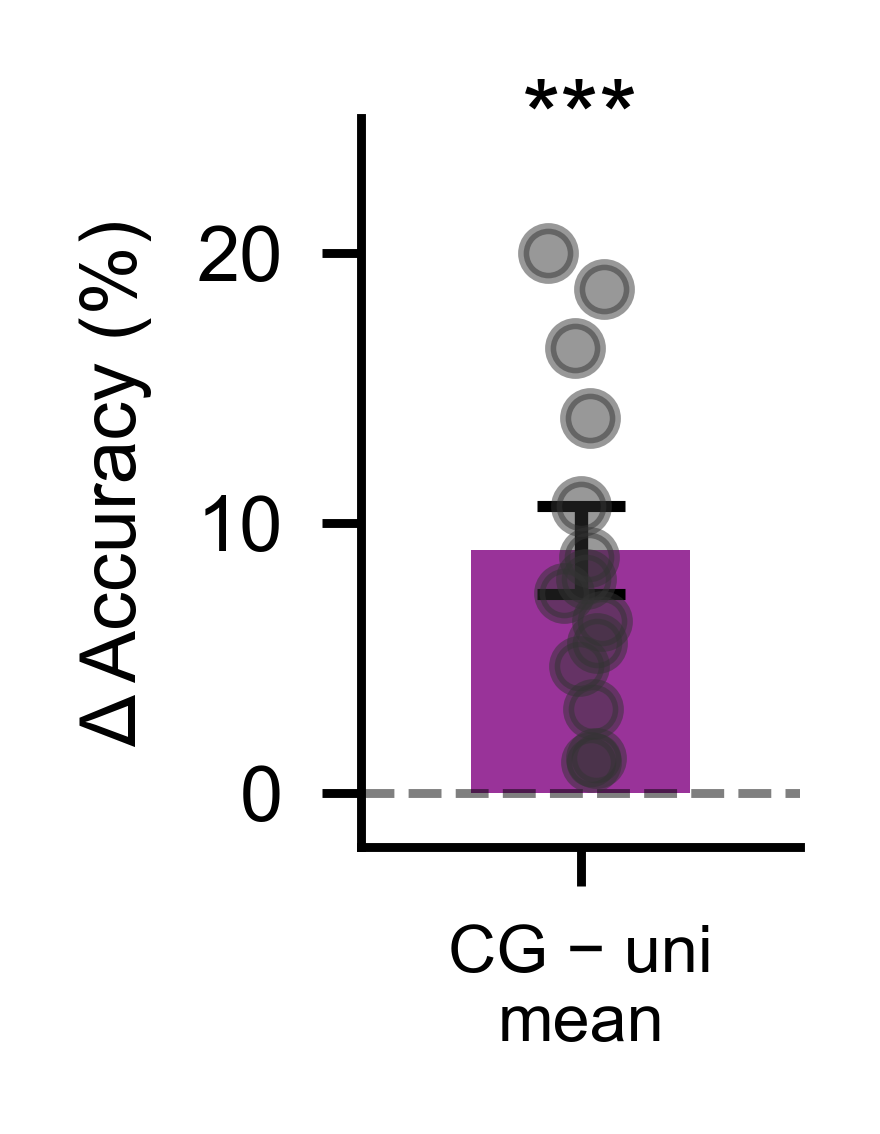

In [95]:
def plot_delta_accuracy_cg(stats, contexts_uni=('Visual', 'Audio'),
                            ctx_cg='Congruent',
                            context_colors=None, figsize=(1.2, 1.5),
                            fontsize=7, jitter_seed=1000):
    """
    Single bar showing delta accuracy: CG − mean(uni contexts).
    Significance tested against 0 (one-sample t-test on simulated points).

    Parameters
    ----------
    stats : dict
        Maps context name → (n, mean, sem)
        e.g. {'Visual': (14, 76.1, 1.3), 'Audio': (14, 74.5, 2.1),
               'Congruent': (14, 84.3, 1.2)}
    contexts_uni : tuple
        Context names to average as the unisensory baseline
    ctx_cg : str
        Name of the CG context
    """
    from scipy.stats import ttest_1samp

    if context_colors is None:
        context_colors = {
            'Visual'    : '#EC008C',
            'Audio'     : '#27AAE1',
            'Congruent' : 'purple',
        }

    def simulate_points(n, mean, sem, seed):
        std = sem * np.sqrt(n)
        rng = np.random.default_rng(seed)
        pts = rng.normal(mean, std, n)
        return pts - pts.mean() + mean   # exact mean

    # Simulate per-animal values for each context
    sim = {}
    for i, ctx in enumerate(list(contexts_uni) + [ctx_cg]):
        n, mean, sem = stats[ctx]
        sim[ctx] = simulate_points(n, mean, sem, seed=jitter_seed + i)

    # Delta per simulated animal: CG − mean(uni contexts)
    n_common  = min(len(sim[ctx]) for ctx in list(contexts_uni) + [ctx_cg])
    uni_mean  = np.mean([sim[ctx][:n_common] for ctx in contexts_uni], axis=0)
    deltas    = sim[ctx_cg][:n_common] - uni_mean

    mean_delta = deltas.mean()
    sem_delta  = deltas.std(ddof=1) / np.sqrt(n_common)
    _, p       = ttest_1samp(deltas, 0)
    p_text     = 'p<0.001' if p < 0.001 else f'p={p:.3f}'
    star       = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))

    print(f'Delta accuracy (CG − uni mean): {mean_delta:.2f} ± {sem_delta:.2f}')
    print(f'One-sample t-test vs 0: {p_text}')

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    # Bar
    ax.bar(0, mean_delta, width=0.5,
           color=context_colors.get(ctx_cg, 'purple'), alpha=0.8,
           edgecolor='none')
    ax.errorbar(0, mean_delta, yerr=sem_delta,
                fmt='none', color='black', capsize=4, elinewidth=1.2)

    # Simulated animal dots
    rng = np.random.default_rng(jitter_seed + 999)
    jitter = rng.uniform(-0.08, 0.08, size=n_common)
    ax.scatter(jitter, deltas,
               color='#333333', s=20, alpha=0.5, zorder=3)

    # Significance vs 0
    y_top = max(deltas.max(), mean_delta + sem_delta)
    bar_h = y_top * 1.15 if y_top > 0 else y_top * 0.85
    ax.text(0, bar_h, star, ha='center', va='bottom', fontsize=9)

    ax.axhline(0, color='k', lw=0.8, ls='--', alpha=0.5)
    ax.set_xticks([0])
    ax.set_xticklabels([f'CG − uni\nmean'], fontsize=fontsize - 1)
    ax.set_ylabel('Δ Accuracy (%)', fontsize=fontsize)
    ax.set_xlim(-0.5, 0.5)
    ax.set_ylim(-2, 25)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    return fig, ax


stats = {
    'Visual'    : (14, 76.1, 1.3),
    'Audio'     : (14, 74.5, 2.1),
    'Congruent' : (14, 84.3, 1.2),
}
fig, ax = plot_delta_accuracy_cg(stats)
plt.savefig('figures/delta_accuracy_cg.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Responsive neurons: 17,406
  Context-invariant (|CI| < 0.1): 6,631 (38.1%)
  CG-preferring     (CI ≥  0.1):  7,513  (43.2%)
  Uni-preferring    (CI ≤ -0.1): 3,262  (18.7%)


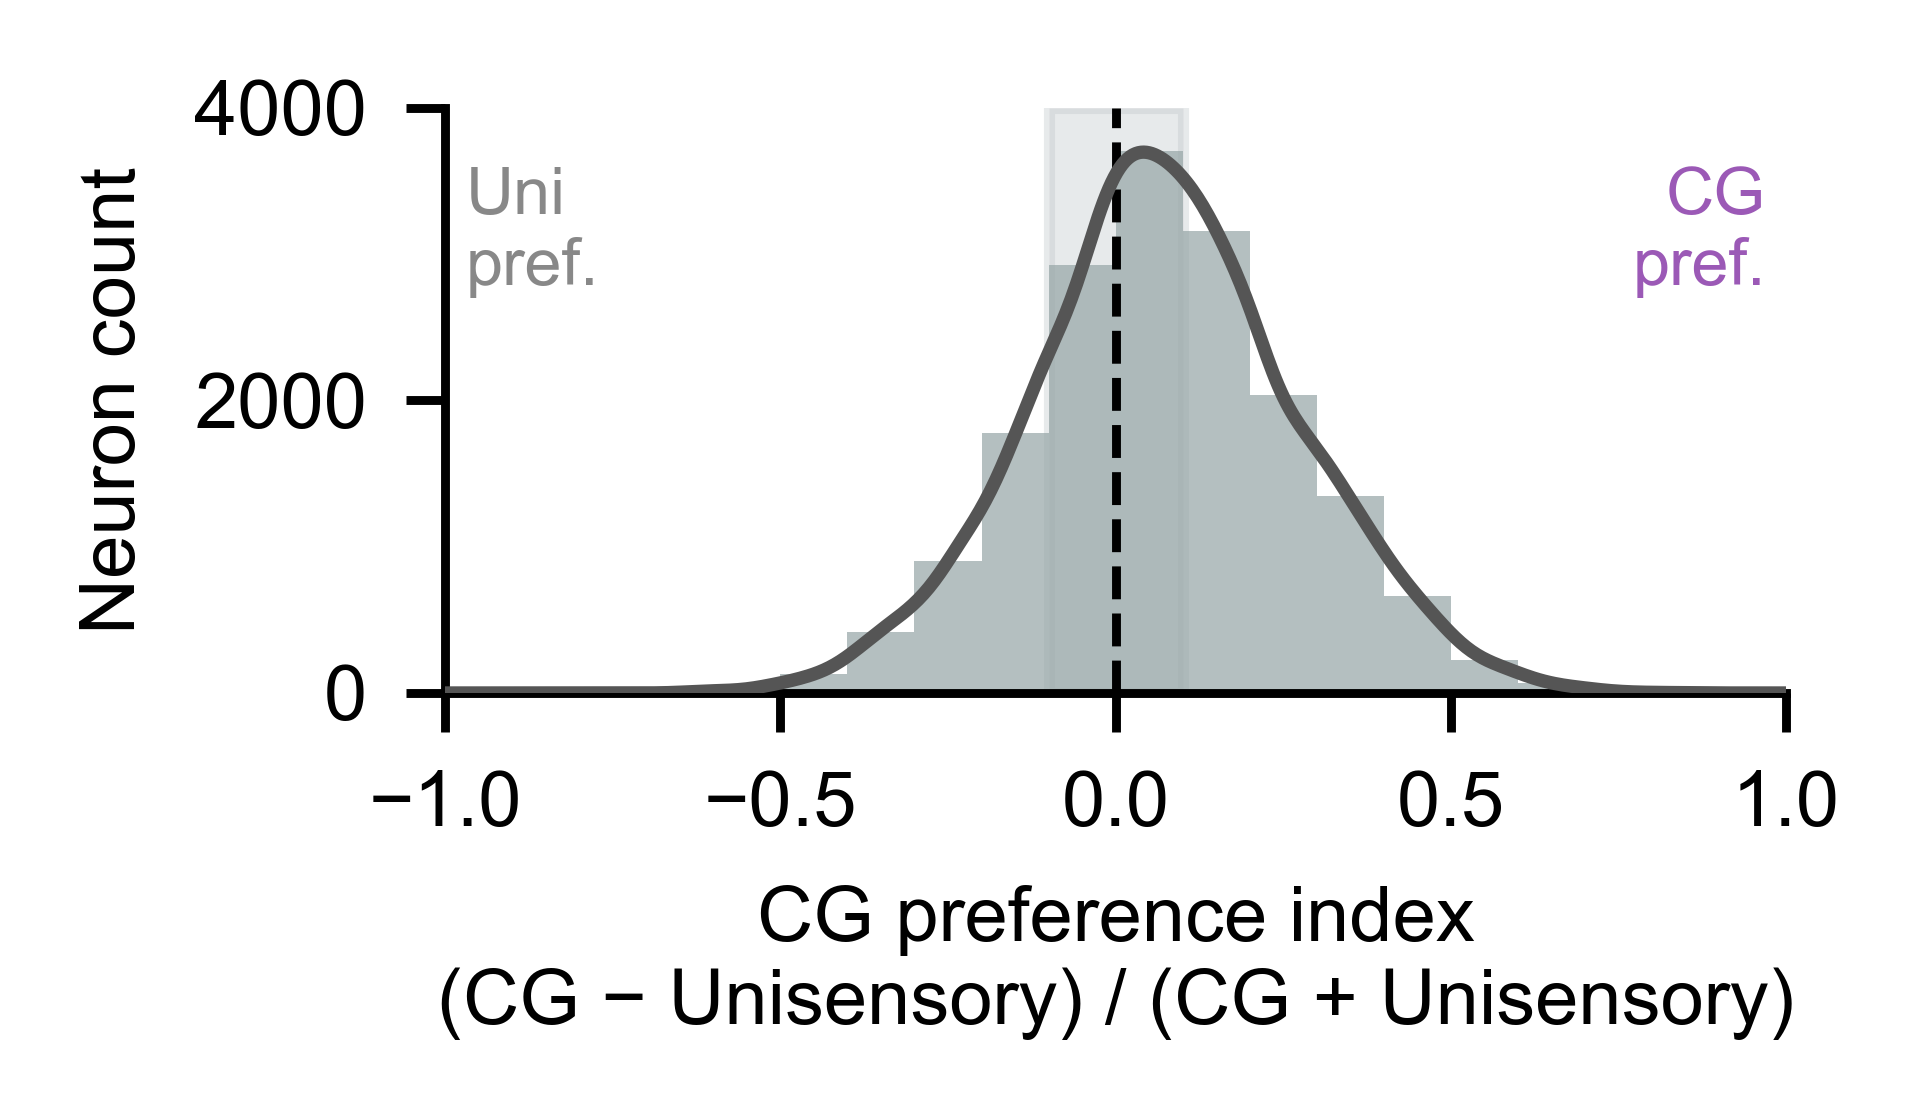

In [48]:
def plot_cg_vs_uni_ci(df_uni, df_cg, resp_threshold=0.1, invariant_thresh=0.1, figsize=(2.5, 1.5)):
    from scipy.stats import gaussian_kde

    # Merge at neuron level — take unisensory FDEs from df_uni, CG FDE from df_cg
    merge_keys = ['mouse_ID', 'date', 'neuron_idx']
    uni_cols   = merge_keys + ['frac_dev_visual', 'frac_dev_audio', 'test_frac_dev']
    cg_cols    = merge_keys + ['frac_dev_cg', 'test_frac_dev']

    merged = df_uni[uni_cols].merge(
        df_cg[cg_cols].rename(columns={'test_frac_dev': 'test_frac_dev_cg'}),
        on=merge_keys, how='inner'
    )

    # Responsive if above threshold in either model
    resp_df = merged[
        (merged['test_frac_dev']    > resp_threshold) &
        (merged['test_frac_dev_cg'] > resp_threshold)
    ].copy()

    resp_df['frac_dev_unisensory'] = (
        resp_df['frac_dev_visual'] + resp_df['frac_dev_audio']
    ) / 2

    resp_df['cg_uni_ci'] = (
        (resp_df['frac_dev_cg'] - resp_df['frac_dev_unisensory']) /
        (resp_df['frac_dev_cg'] + resp_df['frac_dev_unisensory'] + 1e-8)
    )

    ci      = resp_df['cg_uni_ci'].values
    n_total = len(ci)

    n_invariant = (np.abs(ci) < invariant_thresh).sum()
    n_cg_pref   = (ci >=  invariant_thresh).sum()
    n_uni_pref  = (ci <= -invariant_thresh).sum()
    print(f'Responsive neurons: {n_total:,}')
    print(f'  Context-invariant (|CI| < {invariant_thresh}): {n_invariant:,} ({n_invariant/n_total*100:.1f}%)')
    print(f'  CG-preferring     (CI ≥  {invariant_thresh}):  {n_cg_pref:,}  ({n_cg_pref/n_total*100:.1f}%)')
    print(f'  Uni-preferring    (CI ≤ -{invariant_thresh}): {n_uni_pref:,}  ({n_uni_pref/n_total*100:.1f}%)')

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    counts, edges, _ = ax.hist(
        ci, bins=20, range=(-1, 1),
        color='#95A5A6', edgecolor='none', alpha=0.7, zorder=2
    )

    # KDE overlay
    kde   = gaussian_kde(ci, bw_method=0.15)
    x_kde = np.linspace(-1, 1, 500)
    y_kde = kde(x_kde) * n_total * (edges[1] - edges[0])
    ax.plot(x_kde, y_kde, color='#555555', lw=1.2, zorder=4)

    # Shaded invariant zone
    ax.axvspan(-invariant_thresh, invariant_thresh,
               color='#BDC3C7', alpha=0.35, zorder=1)
    ax.axvline(0, color='k', lw=0.8, ls='--', zorder=3)

    y_max = counts.max()
    ax.text(-0.97, y_max * 0.97, 'Uni\npref.',
            fontsize=6, color='#888888', va='top', ha='left')
    ax.text( 0.97, y_max * 0.97, 'CG\npref.',
            fontsize=6, color=CTX_COLORS_STR['cg'], va='top', ha='right')

    ax.set_xlabel('CG preference index\n(CG − Unisensory) / (CG + Unisensory)', fontsize=7)
    ax.set_ylabel('Neuron count', fontsize=7)
    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 4000)

    sns.despine()
    plt.tight_layout()
    return fig

fig_cg_ci = plot_cg_vs_uni_ci(df_uni, df_cg)
plt.savefig('figures/cg_vs_uni_context_index_both.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Responsive neurons: 31,165
  Context-invariant (|CI| < 0.1): 7,119 (22.8%)
  CG-preferring     (CI ≥  0.1):  13,454  (43.2%)
  Uni-preferring    (CI ≤ -0.1): 10,592  (34.0%)


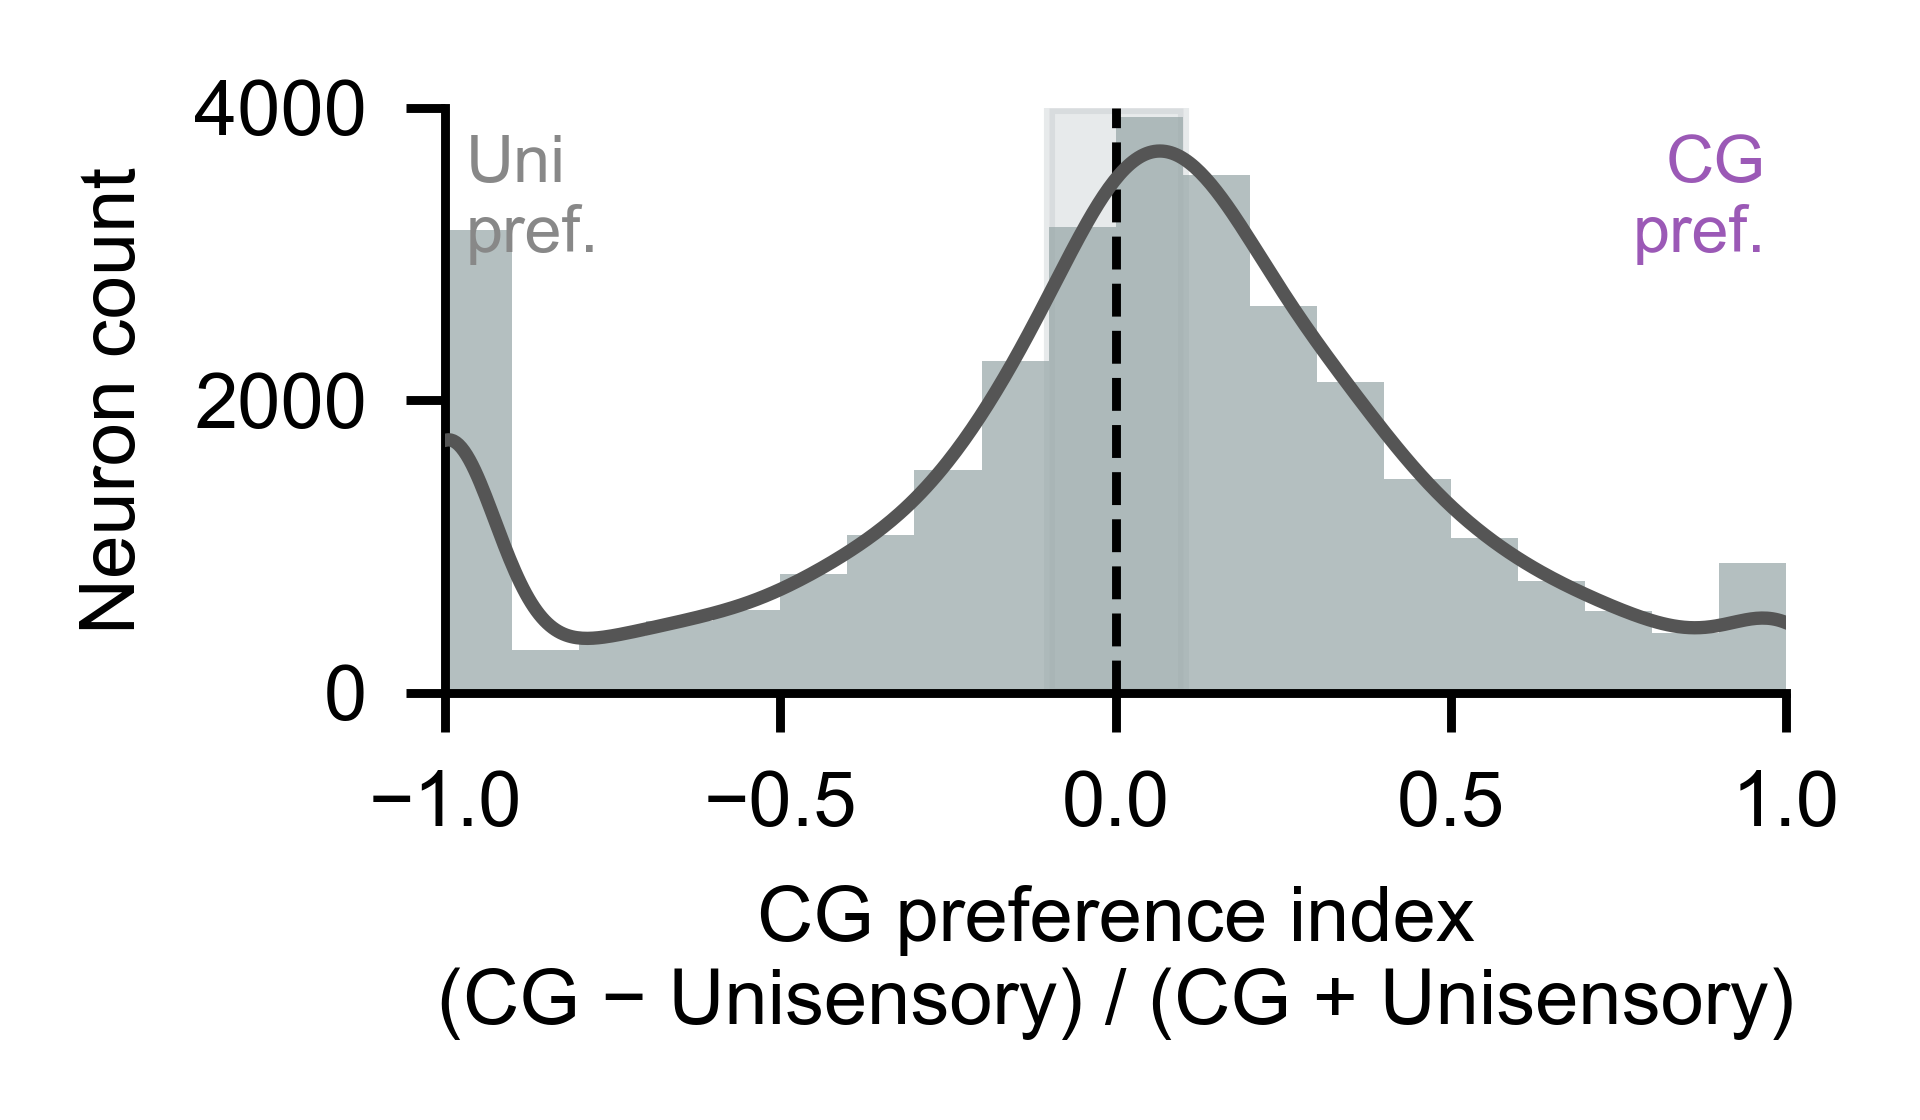

In [59]:
def plot_cg_vs_uni_ci(df_uni, df_cg, resp_threshold=0.1, invariant_thresh=0.1, figsize=(2.5, 1.5)):
    from scipy.stats import gaussian_kde

    # Merge at neuron level — take unisensory FDEs from df_uni, CG FDE from df_cg
    merge_keys = ['mouse_ID', 'date', 'neuron_idx']
    uni_cols   = merge_keys + ['frac_dev_visual', 'frac_dev_audio', 'test_frac_dev']
    cg_cols    = merge_keys + ['frac_dev_cg', 'test_frac_dev']

    merged = df_uni[uni_cols].merge(
        df_cg[cg_cols].rename(columns={'test_frac_dev': 'test_frac_dev_cg'}),
        on=merge_keys, how='inner'
    )

    # Responsive if above threshold in either model
    resp_df = merged[
        (merged['test_frac_dev']    > resp_threshold) |
        (merged['test_frac_dev_cg'] > resp_threshold)
    ].copy()

    resp_df['frac_dev_unisensory'] = (
        resp_df['frac_dev_visual'] + resp_df['frac_dev_audio']
    ) / 2

    resp_df['cg_uni_ci'] = (
        (resp_df['frac_dev_cg'] - resp_df['frac_dev_unisensory']) /
        (resp_df['frac_dev_cg'] + resp_df['frac_dev_unisensory'] + 1e-8)
    )

    ci      = resp_df['cg_uni_ci'].values
    n_total = len(ci)

    n_invariant = (np.abs(ci) < invariant_thresh).sum()
    n_cg_pref   = (ci >=  invariant_thresh).sum()
    n_uni_pref  = (ci <= -invariant_thresh).sum()
    print(f'Responsive neurons: {n_total:,}')
    print(f'  Context-invariant (|CI| < {invariant_thresh}): {n_invariant:,} ({n_invariant/n_total*100:.1f}%)')
    print(f'  CG-preferring     (CI ≥  {invariant_thresh}):  {n_cg_pref:,}  ({n_cg_pref/n_total*100:.1f}%)')
    print(f'  Uni-preferring    (CI ≤ -{invariant_thresh}): {n_uni_pref:,}  ({n_uni_pref/n_total*100:.1f}%)')

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    counts, edges, _ = ax.hist(
        ci, bins=20, range=(-1, 1),
        color='#95A5A6', edgecolor='none', alpha=0.7, zorder=2
    )

    # KDE overlay
    kde   = gaussian_kde(ci, bw_method=0.15)
    x_kde = np.linspace(-1, 1, 500)
    y_kde = kde(x_kde) * n_total * (edges[1] - edges[0])
    ax.plot(x_kde, y_kde, color='#555555', lw=1.2, zorder=4)

    # Shaded invariant zone
    ax.axvspan(-invariant_thresh, invariant_thresh,
               color='#BDC3C7', alpha=0.35, zorder=1)
    ax.axvline(0, color='k', lw=0.8, ls='--', zorder=3)

    y_max = counts.max()
    ax.text(-0.97, y_max * 0.97, 'Uni\npref.',
            fontsize=6, color='#888888', va='top', ha='left')
    ax.text( 0.97, y_max * 0.97, 'CG\npref.',
            fontsize=6, color=CTX_COLORS_STR['cg'], va='top', ha='right')

    ax.set_xlabel('CG preference index\n(CG − Unisensory) / (CG + Unisensory)', fontsize=7)
    ax.set_ylabel('Neuron count', fontsize=7)
    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 4000)

    sns.despine()
    plt.tight_layout()
    return fig

fig_cg_ci = plot_cg_vs_uni_ci(df_uni, df_cg)
plt.savefig('figures/cg_vs_uni_context_index.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Class                 n  median CG-CI      p vs 0
------------------------------------------------------
  Kinematics      4,899        +0.061   1.53e-105
  Audio             294        +0.138    6.08e-16
  Visual          1,198        +0.203   6.29e-104
  Choice          5,681        +0.072   2.13e-153
  Outcome         3,899        +0.041    7.28e-50
  mixed           1,435        +0.064    1.25e-33


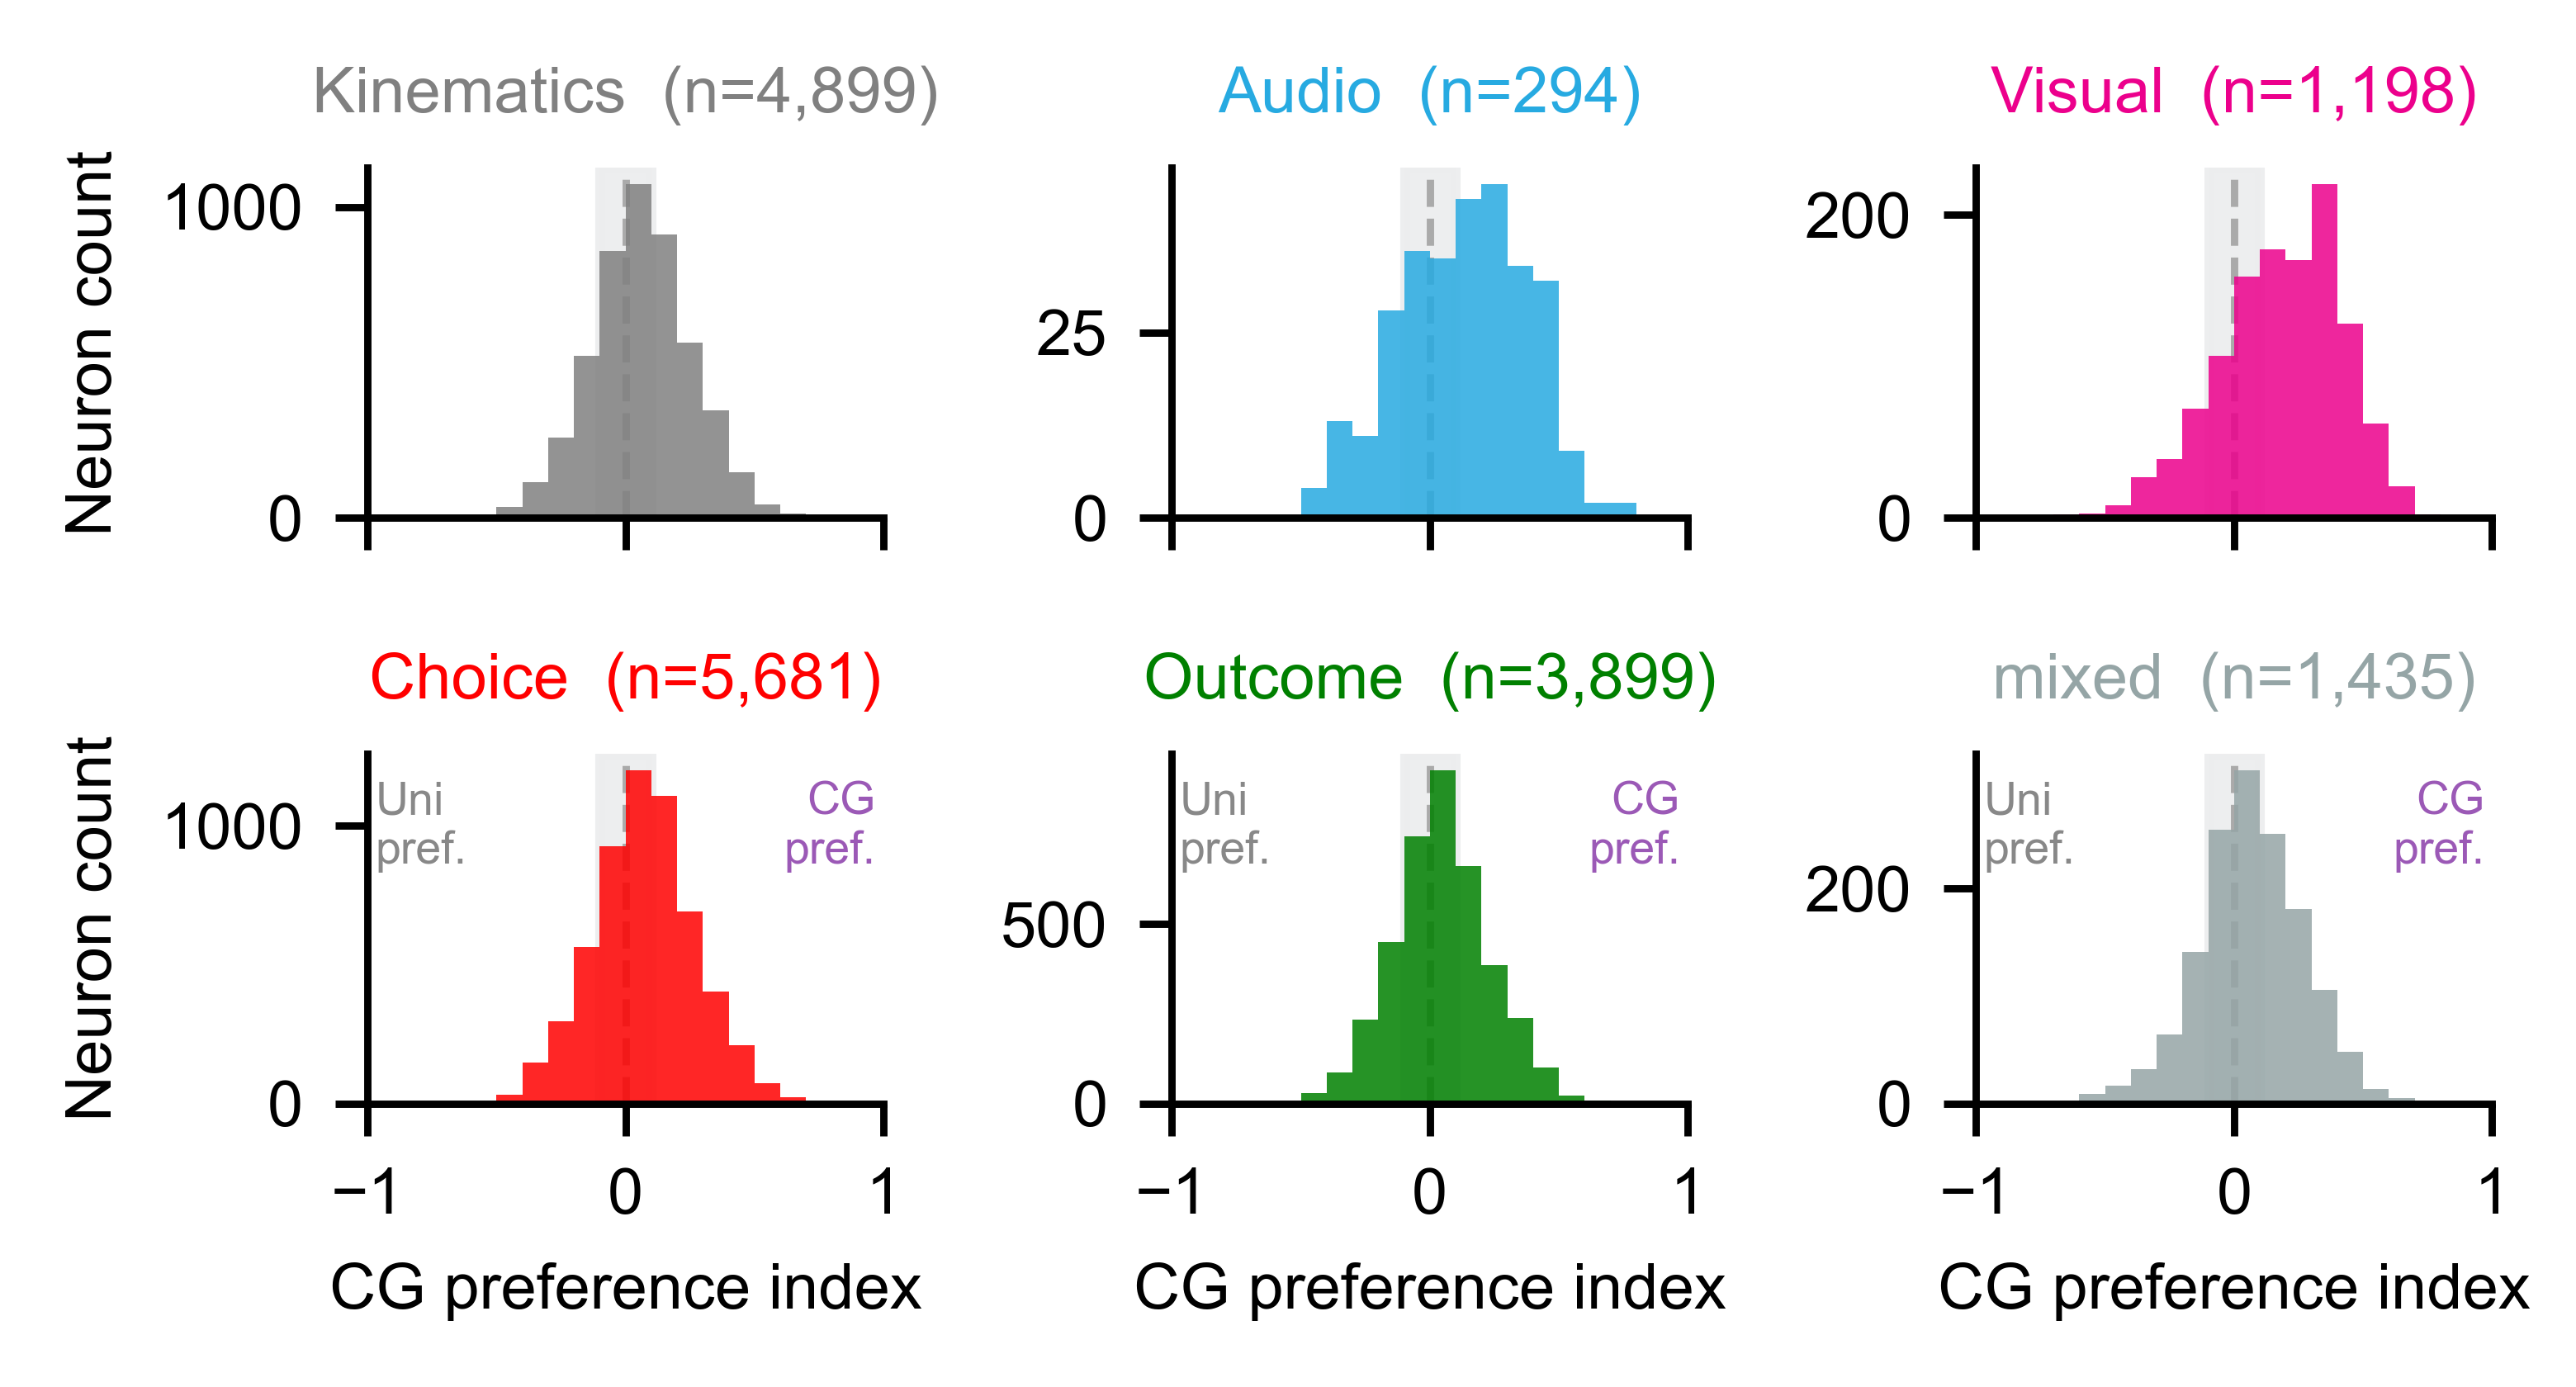

In [49]:
from scipy.stats import gaussian_kde, wilcoxon

PLOT_CLASSES       = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome', 'mixed']
CLASS_COLORS_MERGED = {**MERGE_COLORS, 'mixed': '#95A5A6', 'unclassified': '#BDC3C7'}

def plot_cg_ci_by_class_faceted(df_uni, df_cg, resp_threshold=0.1,
                                 invariant_thresh=0.1, bins=20, figsize=(4, 2.2)):
    # ── Merge at neuron level to get uni FDEs + CG FDE ───────────────────────
    merge_keys = ['mouse_ID', 'date', 'neuron_idx']
    merged = df_uni[merge_keys + ['frac_dev_visual', 'frac_dev_audio',
                                   'test_frac_dev', 'is_responsive',
                                   'merged_class']].merge(
        df_cg[merge_keys + ['frac_dev_cg', 'test_frac_dev']].rename(
            columns={'test_frac_dev': 'test_frac_dev_cg'}),
        on=merge_keys, how='inner'
    )

    # Fix (AND — responsive in both models):
    resp_df = merged[
        (merged['is_responsive'] &
        (merged['test_frac_dev_cg'] > resp_threshold)) &
        merged['merged_class'].isin(PLOT_CLASSES)
    ].copy()

    # CG preference index from the correct sources
    resp_df['frac_dev_unisensory'] = (
        resp_df['frac_dev_visual'] + resp_df['frac_dev_audio']
    ) / 2
    resp_df['cg_uni_ci'] = (
        (resp_df['frac_dev_cg'] - resp_df['frac_dev_unisensory']) /
        (resp_df['frac_dev_cg'] + resp_df['frac_dev_unisensory'] + 1e-8)
    )

    # ── Plot ─────────────────────────────────────────────────────────────────
    n_cols = 3
    n_rows = int(np.ceil(len(PLOT_CLASSES) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize, dpi=800,
                             sharex=True, sharey=False)
    axes = axes.flatten()

    print(f'{"Class":<15s}  {"n":>6s}  {"median CG-CI":>12s}  {"p vs 0":>10s}')
    print('-' * 54)

    for idx, cls in enumerate(PLOT_CLASSES):
        ax    = axes[idx]
        color = CLASS_COLORS_MERGED.get(cls, '#AAAAAA')
        sub   = resp_df[resp_df['merged_class'] == cls]['cg_uni_ci'].dropna().values

        ax.axvspan(-invariant_thresh, invariant_thresh,
                   color='#ECEDEE', alpha=0.9, zorder=0)
        ax.axvline(0, color='#AAAAAA', lw=0.8, ls='--', zorder=1)

        if len(sub) < 10:
            ax.set_title(f'{cls}  (n={len(sub)})', fontsize=7, color=color)
            print(f'  {cls:<13s}  skipped (n={len(sub)})')
            continue

        ax.hist(sub, bins=bins, range=(-1, 1),
                color=color, alpha=0.85, edgecolor='none', zorder=2)

        median = np.median(sub)
        # ax.axvline(median, color='k', lw=1.0, ls='-', zorder=3)

        try:
            _, p_val = wilcoxon(sub)
            p_str = f'{p_val:.2e}'
        except Exception:
            p_str = 'n/a'

        ax.set_title(f'{cls}  (n={len(sub):,})', fontsize=7, color=color)
        ax.set_xlim(-1, 1)
        ax.set_ylim(bottom=0)
        sns.despine(ax=ax)

        print(f'  {cls:<13s}  {len(sub):>6,}  {median:>+12.3f}  {p_str:>10s}')

    for ax in axes[n_cols * (n_rows - 1):]:
        ax.set_xlabel('CG preference index', fontsize=7)
    for ax in axes[::n_cols]:
        ax.set_ylabel('Neuron count', fontsize=7)

    for ax in axes[n_cols * (n_rows - 1): n_cols * (n_rows - 1) + n_cols]:
        if ax.get_visible():
            ax.text(-0.97, ax.get_ylim()[1] * 0.92, 'Uni\npref.',
                    fontsize=5, color='#888888', va='top', ha='left')
            ax.text( 0.97, ax.get_ylim()[1] * 0.92, 'CG\npref.',
                    fontsize=5, color=CTX_COLORS_STR['cg'], va='top', ha='right')

    for ax in axes[len(PLOT_CLASSES):]:
        ax.set_visible(False)

    plt.tight_layout()
    return fig

fig_cg_ci_facet = plot_cg_ci_by_class_faceted(df_uni, df_cg)
plt.savefig('figures/cg_ci_by_neuron_class_faceted.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Context            mean Δ      SEM      p vs 0
------------------------------------------------
  Unisensory      +0.0781   0.0028  3.638e-12
  CG              +0.0800   0.0031  3.638e-12

  Unisensory vs CG ΔFDE: p=1.311e-01  ns


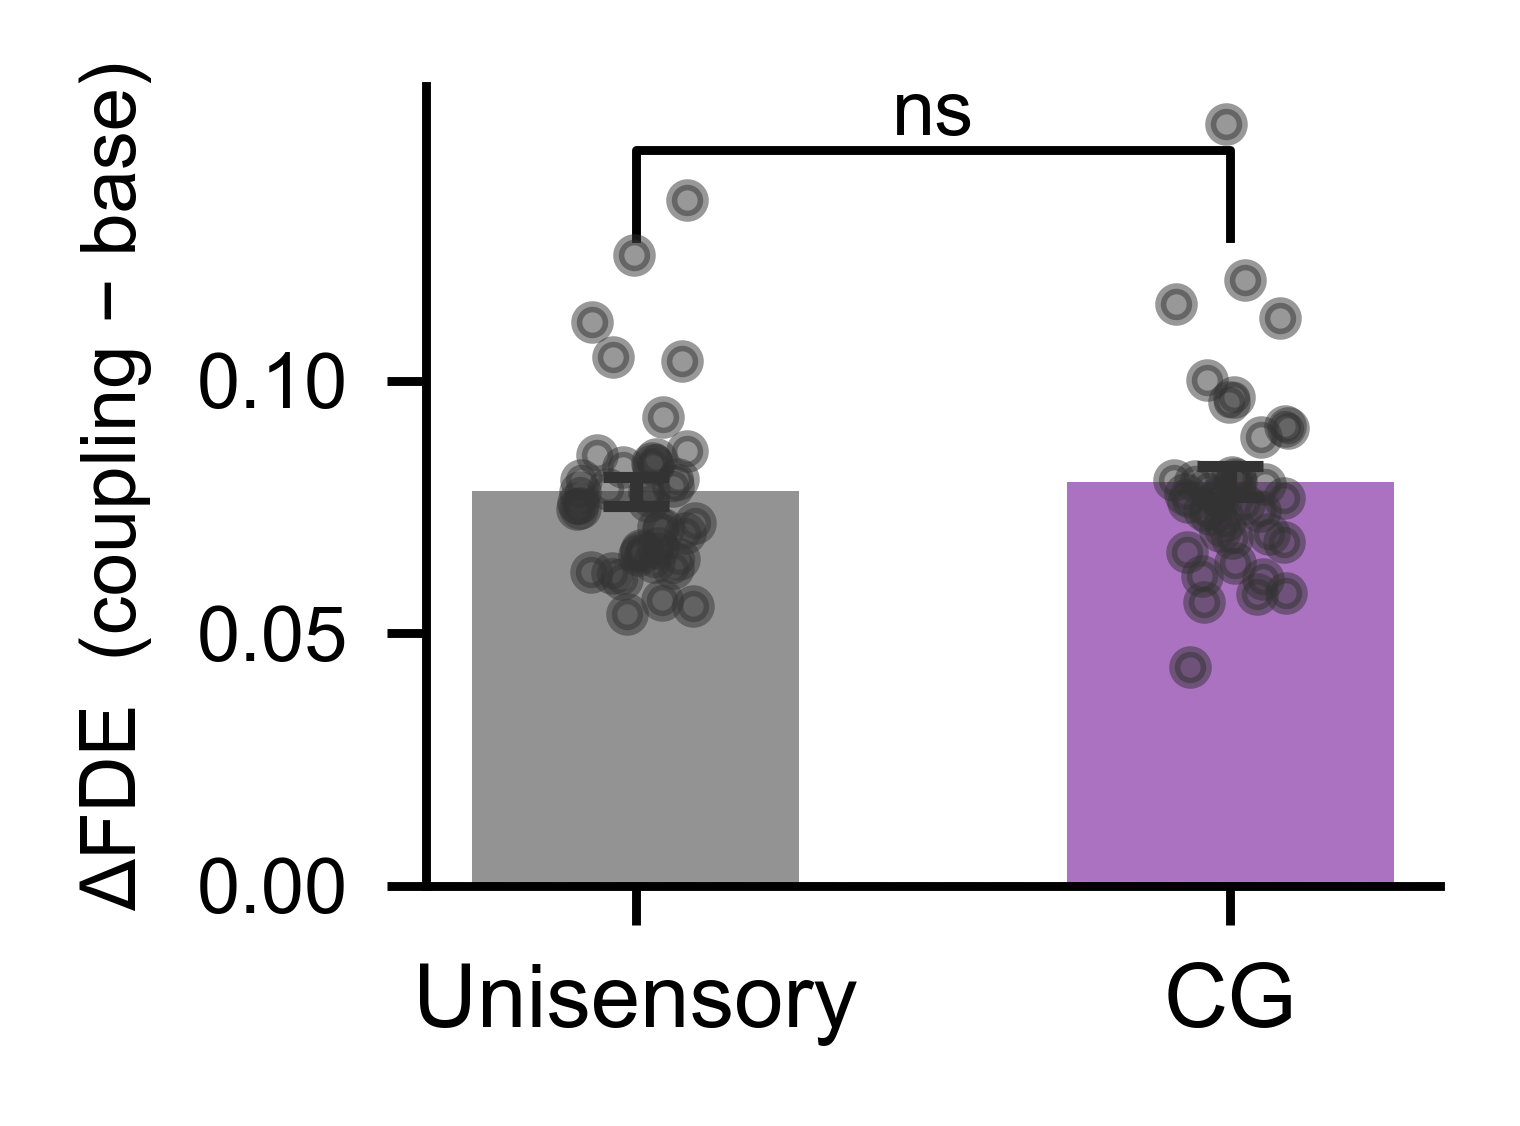

In [60]:
def plot_coupling_delta_uni_vs_cg(df_uni, df_uni_coup,
                                   df_cg, df_cg_coup,
                                   figsize=(2.0, 1.5)):
    from scipy.stats import wilcoxon

    # ── Unisensory delta: coupling vs base, on visual + audio FDE ────────────
    shared_uni = df_uni.index.intersection(df_uni_coup.index)
    base_uni   = df_uni.loc[shared_uni]
    coup_uni   = df_uni_coup.loc[shared_uni]

    resp_uni   = base_uni['is_responsive'] | coup_uni['is_responsive']
    base_uni   = base_uni[resp_uni]
    coup_uni   = coup_uni[resp_uni]

    df_uni_delta = base_uni[['mouse_ID', 'date']].copy()
    df_uni_delta['delta_unisensory'] = (
        (coup_uni['frac_dev_visual'].values - base_uni['frac_dev_visual'].values) +
        (coup_uni['frac_dev_audio'].values  - base_uni['frac_dev_audio'].values)
    ) / 2

    sess_uni = df_uni_delta.groupby(['mouse_ID', 'date'])['delta_unisensory'].mean().reset_index()

    # ── CG delta: coupling vs base, on CG FDE ────────────────────────────────
    shared_cg = df_cg.index.intersection(df_cg_coup.index)
    base_cg   = df_cg.loc[shared_cg]
    coup_cg   = df_cg_coup.loc[shared_cg]

    resp_cg   = base_cg['is_responsive'] | coup_cg['is_responsive']
    base_cg   = base_cg[resp_cg]
    coup_cg   = coup_cg[resp_cg]

    df_cg_delta = base_cg[['mouse_ID', 'date']].copy()
    df_cg_delta['delta_cg'] = (
        coup_cg['frac_dev_cg'].values - base_cg['frac_dev_cg'].values
    )

    sess_cg = df_cg_delta.groupby(['mouse_ID', 'date'])['delta_cg'].mean().reset_index()

    # ── Merge at session level ────────────────────────────────────────────────
    sess_delta = sess_uni.merge(sess_cg, on=['mouse_ID', 'date'], how='inner')

    ctx_cols   = ['delta_unisensory', 'delta_cg']
    ctx_labels = ['Unisensory', 'CG']
    ctx_colors = ['grey', CTX_COLORS_STR['cg']]

    fig, ax = plt.subplots(figsize=figsize, dpi=800)
    ax.axhline(0, color='#AAAAAA', lw=0.8, ls='--', zorder=1)

    print(f'{"Context":<15s}  {"mean Δ":>8s}  {"SEM":>7s}  {"p vs 0":>10s}')
    print('-' * 48)

    filtered_vals = {}
    for i, (col, label, color) in enumerate(zip(ctx_cols, ctx_labels, ctx_colors)):
        vals   = sess_delta[col].values
        vals   = vals[vals > 0.01]
        filtered_vals[col] = vals
        mean_v = vals.mean()
        sem_v  = vals.std() / np.sqrt(len(vals))

        ax.bar(i, mean_v, yerr=sem_v, width=0.55,
               color=color, alpha=0.85, edgecolor='none',
               error_kw=dict(elinewidth=1.2, capsize=3, ecolor='#333333'),
               zorder=2)

        rng    = np.random.default_rng(seed=i)
        jitter = rng.uniform(-0.1, 0.1, size=len(vals))
        ax.scatter(i + jitter, vals, color='#333333', s=8, alpha=0.5, zorder=3)

        _, p = wilcoxon(vals)
        print(f'  {label:<13s}  {mean_v:>+8.4f}  {sem_v:>7.4f}  {p:.3e}')

    # ── Significance bracket: Unisensory vs CG ───────────────────────────────
    uni_vals  = filtered_vals['delta_unisensory']
    cg_vals   = filtered_vals['delta_cg']
    n_paired  = min(len(uni_vals), len(cg_vals))
    _, p_diff = wilcoxon(uni_vals[:n_paired], cg_vals[:n_paired])
    sig_diff  = '***' if p_diff < 0.001 else '**' if p_diff < 0.01 else '*' if p_diff < 0.05 else 'ns'

    y_bracket = ax.get_ylim()[1] * 0.92
    ax.plot([0, 0, 1, 1],
            [y_bracket * 0.88, y_bracket, y_bracket, y_bracket * 0.88],
            lw=0.8, color='k')
    ax.text(0.5, y_bracket, sig_diff, ha='center', va='bottom', fontsize=7)
    print(f'\n  Unisensory vs CG ΔFDE: p={p_diff:.3e}  {sig_diff}')

    ax.set_xticks([0, 1])
    ax.set_xticklabels(ctx_labels, fontsize=8)
    ax.set_yticks([0, 0.05, 0.1])
    ax.set_ylabel('ΔFDE  (coupling − base)', fontsize=7)
    sns.despine()
    plt.tight_layout()
    return fig

fig_coup_uni_cg = plot_coupling_delta_uni_vs_cg(df_uni, df_uni_coup, df_cg, df_cg_coup)
plt.savefig('figures/coupling_delta_uni_vs_cg.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()

Pearson  r=0.042  p=1.85e-13
Spearman r=0.013  p=2.05e-02
Total neurons: 31,165  (uni-only: 7,708  cg-only: 6,053  both: 17,406)


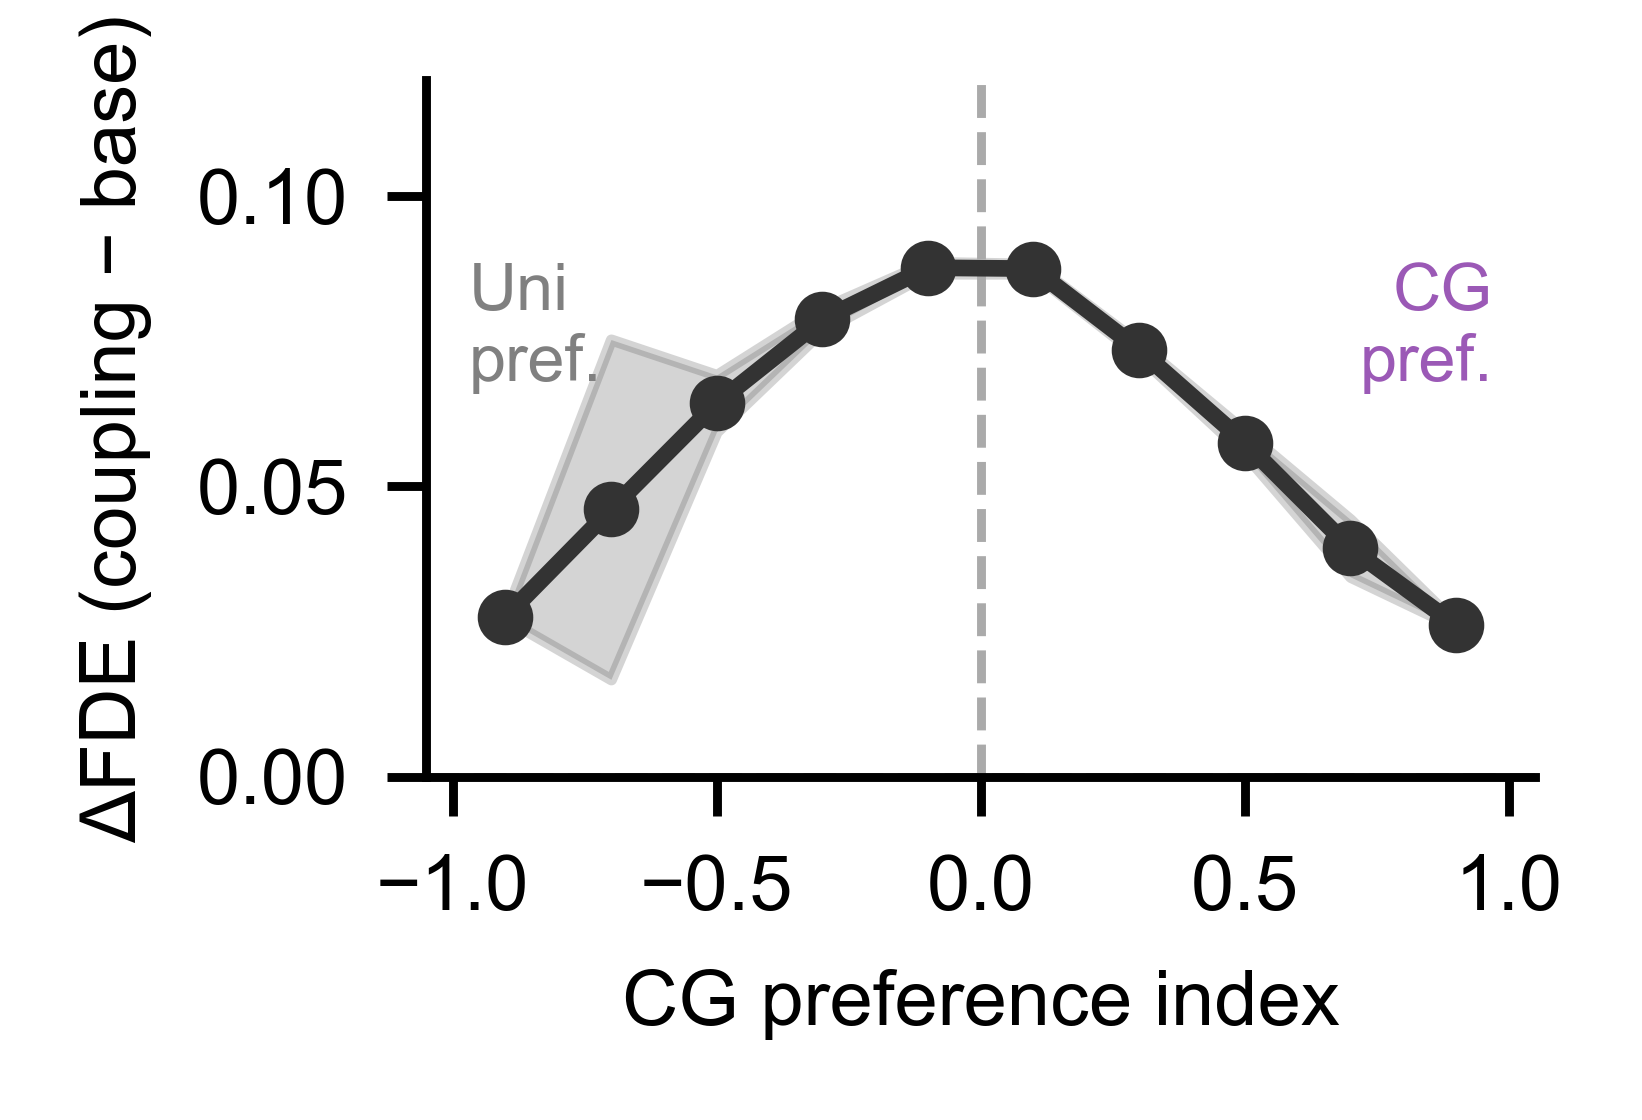

In [58]:
def plot_coupling_gain_vs_cg_preference(df_uni, df_uni_coup,
                                         df_cg, df_cg_coup,
                                         n_bins=10, figsize=(2.2, 1.5)):
    from scipy.stats import pearsonr, spearmanr

    merge_keys = ['mouse_ID', 'date', 'neuron_idx']

    shared_uni = df_uni.index.intersection(df_uni_coup.index)
    base_uni   = df_uni.loc[shared_uni][df_uni.loc[shared_uni]['is_responsive']].copy()
    coup_uni   = df_uni_coup.loc[base_uni.index]
    base_uni['delta_fde_uni'] = (
        (coup_uni['frac_dev_visual'].values - base_uni['frac_dev_visual'].values) +
        (coup_uni['frac_dev_audio'].values  - base_uni['frac_dev_audio'].values)
    ) / 2

    shared_cg = df_cg.index.intersection(df_cg_coup.index)
    base_cg   = df_cg.loc[shared_cg][df_cg.loc[shared_cg]['is_responsive']].copy()
    coup_cg   = df_cg_coup.loc[base_cg.index]
    base_cg['delta_fde_cg'] = (
        coup_cg['frac_dev_cg'].values - base_cg['frac_dev_cg'].values
    )

    merged = base_uni[['mouse_ID', 'date', 'neuron_idx',
                        'frac_dev_visual', 'frac_dev_audio',
                        'delta_fde_uni']].reset_index().merge(
        base_cg[['mouse_ID', 'date', 'neuron_idx',
                  'frac_dev_cg', 'delta_fde_cg']].reset_index(drop=True),
        on=merge_keys, how='outer'
    )

    merged['frac_dev_visual'] = merged['frac_dev_visual'].fillna(0)
    merged['frac_dev_audio']  = merged['frac_dev_audio'].fillna(0)
    merged['frac_dev_cg']     = merged['frac_dev_cg'].fillna(0)
    merged['delta_fde_uni']   = merged['delta_fde_uni'].fillna(0)
    merged['delta_fde_cg']    = merged['delta_fde_cg'].fillna(0)

    merged['frac_dev_unisensory'] = (
        merged['frac_dev_visual'] + merged['frac_dev_audio']
    ) / 2
    merged['cg_uni_ci'] = (
        (merged['frac_dev_cg'] - merged['frac_dev_unisensory']) /
        (merged['frac_dev_cg'] + merged['frac_dev_unisensory'] + 1e-8)
    )
    merged['delta_fde_mean'] = (
        merged['delta_fde_uni'] + merged['delta_fde_cg']
    ) / 2

    x = merged['cg_uni_ci'].values
    y = merged['delta_fde_mean'].values

    r_p, p_p = pearsonr(x, y)
    r_s, p_s = spearmanr(x, y)
    print(f'Pearson  r={r_p:.3f}  p={p_p:.2e}')
    print(f'Spearman r={r_s:.3f}  p={p_s:.2e}')
    print(f'Total neurons: {len(merged):,}  '
          f'(uni-only: {(merged["frac_dev_cg"]==0).sum():,}  '
          f'cg-only: {(merged["frac_dev_unisensory"]==0).sum():,}  '
          f'both: {((merged["frac_dev_cg"]>0) & (merged["frac_dev_unisensory"]>0)).sum():,})')

    # Equal-width bins from -1 to 1
    bin_edges   = np.linspace(-1, 1, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    merged['ci_bin'] = pd.cut(merged['cg_uni_ci'], bins=bin_edges, include_lowest=True)
    binned_raw  = merged.groupby('ci_bin', observed=True)['delta_fde_mean'].agg(['mean', 'sem'])

    binned_mean = np.full(len(bin_centers), np.nan)
    binned_sem  = np.full(len(bin_centers), np.nan)
    for i, b in enumerate(pd.cut(pd.Series(bin_centers), bins=bin_edges, include_lowest=True)):
        if b in binned_raw.index:
            binned_mean[i] = binned_raw.loc[b, 'mean']
            binned_sem[i]  = binned_raw.loc[b, 'sem']

    fig, ax = plt.subplots(figsize=figsize, dpi=800)

    ax.fill_between(bin_centers,
                    binned_mean - binned_sem,
                    binned_mean + binned_sem,
                    alpha=0.25, color='#555555')
    ax.plot(bin_centers, binned_mean, color='#333333',
            lw=1.5, marker='o', ms=4, zorder=3)

    ax.axvline(0, color='#AAAAAA', lw=0.8, ls='--', zorder=1)
    ax.axhline(0, color='#AAAAAA', lw=0.8, ls='--', zorder=1)

    y_top = ax.get_ylim()[1]
    ax.text(-0.97, y_top * 0.95, 'Uni\npref.',
            fontsize=6, color='grey', va='top', ha='left')
    ax.text( 0.97, y_top * 0.95, 'CG\npref.',
            fontsize=6, color=CTX_COLORS_STR['cg'], va='top', ha='right')

    ax.set_xlabel('CG preference index', fontsize=7)
    ax.set_ylabel('ΔFDE (coupling − base)', fontsize=7)
    ax.set_xlim(-1.05, 1.05)
    ax.set_xticks([-1, -0.5, 0, 0.5, 1])
    ax.set_ylim(0, 0.12)

    sns.despine()
    plt.tight_layout()
    return fig


fig_gain_cgci = plot_coupling_gain_vs_cg_preference(df_uni, df_uni_coup, df_cg, df_cg_coup)
plt.savefig('figures/coupling_gain_vs_cg_preference.svg',
            bbox_inches='tight', facecolor='white', edgecolor='none')
plt.show()